<a href="https://colab.research.google.com/github/asheshniraad1-hub/W2052152_CRM-CM_CW1/blob/main/CRM_CW_draft.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1 Data Preparation and Feature Engineering

In [1]:
%pip install -q yfinance lxml openpyxl seaborn

In [2]:
import os, sys, json, time, hashlib, platform, warnings
from io import StringIO                                   # lets pandas read text as if it were a file
from datetime import datetime, timezone, timedelta        # dates and the Sri Lanka time zone

import numpy as np
import pandas as pd
import requests
import yfinance as yf
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch   # shapes for the diagrams
import seaborn as sns
import scipy
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)   # hide pandas "future change" warnings
pd.set_option("display.float_format", "{:,.4f}".format)     # numbers with 4 decimals and commas
pd.set_option("display.max_columns", 30)                    # show up to 30 columns
sns.set_theme(style="whitegrid")                            # default chart style

# Version of every package used (the brief asks for this)
PKG_VERSIONS = {
    "python": platform.python_version(),
    "pandas": pd.__version__,            # DOUBLE underscores on both sides
    "numpy": np.__version__,
    "yfinance": yf.__version__,
    "requests": requests.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}
PKG_VERSIONS

{'python': '3.13.18',
 'pandas': '2.2.3',
 'numpy': '2.4.6',
 'yfinance': '0.2.66',
 'requests': '2.32.4',
 'matplotlib': '3.10.0',
 'seaborn': '0.13.2',
 'scipy': '1.16.3',
 'scikit-learn': '1.6.1'}

In [3]:
#study settings
STUDY_START = "2021-01-01"     # first date requested
STUDY_END = "2025-01-01"       # end date is EXCLUSIVE, so the last trading day is 31 Dec 2024
INDEX_TICKER = "^GSPC"         # S&P 500 index = the benchmark
BASELINE_DAYS = 20             # previous 20 sessions give the volume baseline
ACTIVITY_DAYS = 60             # latest 60 sessions for Frequency and Monetary
SPIKE_FACTOR = 2               # high-volume day = volume > 2 x baseline

WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
SL_TZ = timezone(timedelta(hours=5, minutes=30))    # Sri Lanka time = UTC + 5:30

# ---- Frozen-data switch ----
# True = first run only: scrape and download, then save the workbook.
# False = every later run: load the saved workbook (nothing is downloaded).
CREATE_SNAPSHOT = False

# ---- Folders and the one workbook that stores all the data ----
DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)
SNAPSHOT_FILE = os.path.join(DATA_DIR, "sp500_frozen_snapshot.xlsx")

def file_fingerprint(path):
    """A short code for a file. If the file changes, the code changes (used for the drift check)."""
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()[:16]

def sl_now():
    """Current date and time in Sri Lanka, as text."""
    return datetime.now(SL_TZ).strftime("%Y-%m-%d %H:%M") + " (Sri Lanka time)"

# Save the versions so they appear in your GitHub repo
with open("package_versions.json", "w") as f:
    json.dump(PKG_VERSIONS, f, indent=2)
with open("requirements.txt", "w") as f:
    for name in ["pandas", "numpy", "yfinance", "requests", "matplotlib", "seaborn", "scipy", "scikit-learn"]:
        f.write(name + "==" + PKG_VERSIONS[name] + "\n")

print("Study period :", STUDY_START, "to", STUDY_END, "(end exclusive)")
print("Snapshot file:", SNAPSHOT_FILE, "| already exists:", os.path.exists(SNAPSHOT_FILE))

Study period : 2021-01-01 to 2025-01-01 (end exclusive)
Snapshot file: data/sp500_frozen_snapshot.xlsx | already exists: False


In [4]:
# 1.1
def tidy_list(df):
    """Make the Wikipedia table simple: one row per share, Yahoo-style tickers."""
    df = df.copy()
    out = pd.DataFrame({
        "wiki_symbol": df["Symbol"].astype(str).str.strip(),
        "company": df["Security"],
        "sector": df["GICS Sector"],
        "sub_industry": df["GICS Sub-Industry"],
    })
    out["ticker"] = out["wiki_symbol"].str.replace(".", "-", regex=False)   # Yahoo writes BRK-B, not BRK.B
    return out.drop_duplicates("ticker").reset_index(drop=True)

def table_fingerprint(df):
    """Short code for a price table. Changes if any value, date or column changes.
    Values are rounded to 4 decimals first, because Excel keeps slightly fewer digits than Python."""
    h = hashlib.sha256()
    rounded = df.astype("float64").round(4).reset_index(drop=True)   # same number type every time
    h.update(pd.util.hash_pandas_object(rounded, index=False).values.tobytes())    # the numbers
    h.update("|".join(df.index.strftime("%Y-%m-%d")).encode())                      # the dates as text
    h.update("|".join(map(str, df.columns)).encode())                               # the symbols
    return h.hexdigest()[:16]

def clean_dates(df):
    """Real dates, no time zone, oldest first."""
    df = df.copy()
    df.index = pd.to_datetime(df.index)
    if df.index.tz is not None:
        df.index = df.index.tz_localize(None)
    df.index.name = "Date"
    return df.sort_index()

def check_period(df, label):
    """Stop if the table does not cover the study period."""
    first, last = df.index.min(), df.index.max()
    ok = (first >= pd.Timestamp(STUDY_START)) and (last < pd.Timestamp(STUDY_END)) \
         and (first <= pd.Timestamp(STUDY_START) + pd.Timedelta(days=7)) \
         and (last >= pd.Timestamp(STUDY_END) - pd.Timedelta(days=7))
    if not ok:
        raise ValueError(label + " covers " + str(first.date()) + " to " + str(last.date()) +
                         ", not the study period " + STUDY_START + " to " + STUDY_END +
                         ". Delete the workbook and rebuild it.")

# ---- Step 1: decide whether to load or create ----
if (not os.path.exists(SNAPSHOT_FILE)) and (not CREATE_SNAPSHOT):
    try:                                                    # Colab only: ask for the saved workbook
        from google.colab import files
        print("Workbook not found. Upload your saved workbook (.xlsx) from your device.")
        for name, content in files.upload().items():
            if name.lower().endswith(".xlsx"):
                with open(SNAPSHOT_FILE, "wb") as f:
                    f.write(content)
                break
    except ImportError:
        pass

if os.path.exists(SNAPSHOT_FILE):
    mode = "load"
elif CREATE_SNAPSHOT:
    mode = "create"
else:
    raise FileNotFoundError(SNAPSHOT_FILE + " not found. Upload it, or set CREATE_SNAPSHOT = True once.")
print("MODE:", mode)

if mode == "load":
    # ---- Load everything from the saved workbook ----
    sp500_list = pd.read_excel(SNAPSHOT_FILE, sheet_name="Constituents")
    notes_df = pd.read_excel(SNAPSHOT_FILE, sheet_name="Metadata")
    snapshot_notes = dict(zip(notes_df["key"].astype(str), notes_df["value"].astype(str)))
    adj_all = clean_dates(pd.read_excel(SNAPSHOT_FILE, sheet_name="AdjClose", index_col=0))
    close_all = clean_dates(pd.read_excel(SNAPSHOT_FILE, sheet_name="Close", index_col=0))
    vol_all = clean_dates(pd.read_excel(SNAPSHOT_FILE, sheet_name="Volume", index_col=0))

    # Prioritize original retrieved date keys from metadata ('constituents_retrieved' or 'list_retrieved')
    orig_retrieved = snapshot_notes.get("constituents_retrieved") or snapshot_notes.get("list_retrieved")

    if orig_retrieved and orig_retrieved not in ["n/a", "NaN", ""]:
        snapshot_notes["list_retrieved"] = orig_retrieved
    else:
        # Only fallback to file modification time if metadata is absolutely missing
        mtime = os.path.getmtime(SNAPSHOT_FILE)
        file_dt = datetime.fromtimestamp(mtime, SL_TZ).strftime("%Y-%m-%d %H:%M") + " (Sri Lanka time)"
        snapshot_notes["list_retrieved"] = file_dt

    source_text = "saved workbook (list retrieved " + str(snapshot_notes["list_retrieved"]) + ")"

else:
    # ---- First run only: scrape Wikipedia, download Yahoo prices, check, save ----
    reply = requests.get(WIKI_URL, headers={"User-Agent": "Mozilla/5.0 (university coursework)"}, timeout=30)
    reply.raise_for_status()                                # stop with a clear error if the request failed
    sp500_list = tidy_list(pd.read_html(StringIO(reply.text))[0])

    # Dynamically log the current scrape time in Sri Lankan time zone
    list_time = sl_now()

    symbols = sp500_list["ticker"].tolist() + [INDEX_TICKER]
    pieces = []
    for i in range(0, len(symbols), 100):
        for attempt in range(3):
            piece = yf.download(symbols[i:i + 100], start=STUDY_START, end=STUDY_END,
                                auto_adjust=False, progress=False)
            if not piece.empty:
                break
            time.sleep(5)
        pieces.append(piece)
        print("  downloaded", min(i + 100, len(symbols)), "of", len(symbols))
        time.sleep(1)
    price_time = sl_now()
    raw = pd.concat(pieces, axis=1)

    adj_all = clean_dates(raw["Adj Close"].reindex(columns=symbols))
    close_all = clean_dates(raw["Close"].reindex(columns=symbols))
    vol_all = clean_dates(raw["Volume"].reindex(columns=symbols))

    check_period(adj_all, "The download")
    no_data = [s for s in symbols if adj_all[s].isna().all()]
    print("Symbols with no data:", len(no_data), no_data)
    if INDEX_TICKER in no_data:
        raise RuntimeError("The benchmark failed to download. NOTHING was saved. Run the cell again.")
    if len(no_data) > 0.10 * len(symbols):
        raise RuntimeError("Over 10% of symbols failed. NOTHING was saved. Run the cell again.")

    snapshot_notes = {
        "list_source": WIKI_URL,
        "list_retrieved": list_time,
        "prices_downloaded": price_time,
        "price_source": "Yahoo Finance via yfinance " + yf.__version__ + ", auto_adjust=False",
        "study_start": STUDY_START,
        "study_end_exclusive": STUDY_END,
        "benchmark": INDEX_TICKER,
        "universe_note": "Current S&P 500 constituents on the retrieval date, not historical membership.",
        "n_list_tickers": str(len(sp500_list)),
        "adj_fingerprint": table_fingerprint(adj_all),
        "close_fingerprint": table_fingerprint(close_all),
        "volume_fingerprint": table_fingerprint(vol_all),
    }
    with pd.ExcelWriter(SNAPSHOT_FILE, engine="openpyxl") as writer:
        sp500_list.to_excel(writer, sheet_name="Constituents", index=False)
        pd.DataFrame({"key": list(snapshot_notes), "value": list(snapshot_notes.values())}).to_excel(
            writer, sheet_name="Metadata", index=False)
        adj_all.to_excel(writer, sheet_name="AdjClose")
        close_all.to_excel(writer, sheet_name="Close")
        vol_all.to_excel(writer, sheet_name="Volume")
    source_text = "first run: downloaded and saved to " + SNAPSHOT_FILE
    print("Workbook saved:", SNAPSHOT_FILE)
    try:
        from google.colab import files
        files.download(SNAPSHOT_FILE)
    except ImportError:
        pass
    print("NOW set CREATE_SNAPSHOT = False in the settings cell. Keep the downloaded workbook safe.")

# ---- Checks that run in BOTH modes ----
check_period(adj_all, "The workbook")
for label, tbl, key in [("AdjClose", adj_all, "adj_fingerprint"), ("Close", close_all, "close_fingerprint"),
                        ("Volume", vol_all, "volume_fingerprint")]:
    saved = snapshot_notes.get(key)
    if saved is not None and saved != table_fingerprint(tbl):
        raise ValueError(label + " does not match the fingerprint saved when the workbook was built. "
                         "The file has been changed. Re-upload the original workbook.")
assert sp500_list["ticker"].is_unique and sp500_list["ticker"].notna().all(), "Problem in the ticker list"

share_list = sp500_list["ticker"].tolist()
print("Data source   :", source_text)
print("List retrieved:", snapshot_notes.get("list_retrieved"))
print("Shares listed :", len(share_list))
print("Table shape   :", adj_all.shape, "(trading days x symbols incl. the index)")
print("Date range    :", adj_all.index.min().date(), "to", adj_all.index.max().date())
print("Fingerprint   :", table_fingerprint(adj_all), "(must be the same on every run)")
sp500_list.head()

Workbook not found. Upload your saved workbook (.xlsx) from your device.


Saving sp500_frozen_snapshot.xlsx to sp500_frozen_snapshot.xlsx
MODE: load
Data source   : saved workbook (list retrieved 2026-11-20 08:22 UTC)
List retrieved: 2026-11-20 08:22 UTC
Shares listed : 503
Table shape   : (1005, 504) (trading days x symbols incl. the index)
Date range    : 2021-01-04 to 2024-12-31
Fingerprint   : 94c766204a2ce149 (must be the same on every run)


,ticker,security,gics_sector,gics_sub_industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888)
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989


Period       : 2021-01-04 to 2024-12-31
Trading days : 1005 (a real 2021-2024 download has about 1005)
Symbols      : 504 (shares + the index)

Symbols with no prices at all     : 5 ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']
Symbols whose history starts late : 10
Symbols with gaps inside history  : 0 []
Symbols with zero-volume days     : {'FERG': 27, 'SW': 424, '^GSPC': 1}
Benchmark present with full history: True


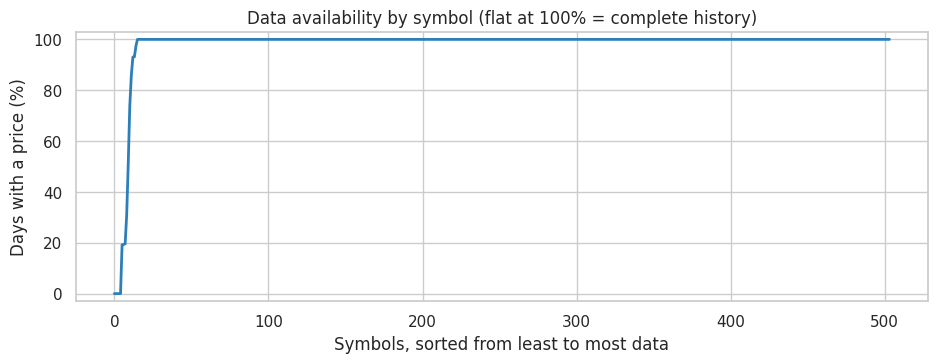

In [5]:

print("Period       :", adj_all.index.min().date(), "to", adj_all.index.max().date())
print("Trading days :", len(adj_all), "(a real 2021-2024 download has about 1005)")
print("Symbols      :", adj_all.shape[1], "(shares + the index)")

# First date with a price, for every symbol (empty columns give nothing)
first_price = adj_all.apply(lambda col: col.first_valid_index())
no_price = [s for s in adj_all.columns if adj_all[s].isna().all()]                         # nothing at all
late_start = first_price.dropna()[first_price.dropna() > adj_all.index[0]]                 # history starts late
gaps = [s for s in adj_all.columns if s not in no_price and s not in late_start.index
        and adj_all[s].isna().any()]                                                       # holes inside a full history
zero_vol = (vol_all <= 0).sum()
zero_vol = zero_vol[zero_vol > 0]

print()
print("Symbols with no prices at all     :", len(no_price), no_price)
print("Symbols whose history starts late :", len(late_start))
print("Symbols with gaps inside history  :", len(gaps), gaps[:10])
print("Symbols with zero-volume days     :", zero_vol.to_dict())
print("Benchmark present with full history:", INDEX_TICKER in adj_all.columns and adj_all[INDEX_TICKER].notna().all())

# Picture: share of trading days that have a price, for every symbol (sorted)
availability = adj_all.notna().mean().sort_values()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(range(len(availability)), availability.values * 100, color="#2c7fb8", lw=2)
ax.set_xlabel("Symbols, sorted from least to most data")
ax.set_ylabel("Days with a price (%)")
ax.set_title("Data availability by symbol (flat at 100% = complete history)")
ax.set_ylim(-3, 103)
plt.savefig(FIG_DIR + "/data_availability.png", dpi=150, bbox_inches="tight")
plt.show()

1.2 Data validation and alignment



In [6]:
#  1.2a  DATE CHECKS AND COMMON CALENDAR
# Look for duplicate dates and dates outside the study period, in each of the three tables
for name, tbl in [("adj", adj_all), ("close", close_all), ("volume", vol_all)]:
    outside = (tbl.index < pd.Timestamp(STUDY_START)) | (tbl.index >= pd.Timestamp(STUDY_END))
    print(name.ljust(6), "| duplicate dates:", int(tbl.index.duplicated().sum()),
          "| dates outside the study period:", int(outside.sum()))

# If a date appears twice, keep the first row
adj_all, close_all, vol_all = [t[~t.index.duplicated(keep="first")] for t in (adj_all, close_all, vol_all)]

# The benchmark's trading days become the common calendar for every share
bench_adj = adj_all[INDEX_TICKER]
trading_days = bench_adj.dropna().index
print("Benchmark trading days:", len(trading_days), "|", trading_days.min().date(), "to", trading_days.max().date())
print("Benchmark prices <= 0 :", int((bench_adj.dropna() <= 0).sum()))
print("Dates in the tables that are not benchmark trading days:", len(adj_all.index.difference(trading_days)))

# Put every share on the benchmark calendar. reindex() never fills anything:
# a missing price stays missing (NaN), exactly as the brief requires
adj = adj_all.reindex(index=trading_days, columns=share_list)
close = close_all.reindex(index=trading_days, columns=share_list)
volume = vol_all.reindex(index=trading_days, columns=share_list)
print("Aligned tables (days x shares):", adj.shape)

adj    | duplicate dates: 0 | dates outside the study period: 0
close  | duplicate dates: 0 | dates outside the study period: 0
volume | duplicate dates: 0 | dates outside the study period: 0
Benchmark trading days: 1005 | 2021-01-04 to 2024-12-31
Benchmark prices <= 0 : 0
Dates in the tables that are not benchmark trading days: 0
Aligned tables (days x shares): (1005, 503)


Shares listed  : 503
Shares dropped : 17
Shares kept    : 486

Failures by rule (a share can fail more than one):
rule
LATE_START    10
NO_DATA        5
BAD_VOLUME     2


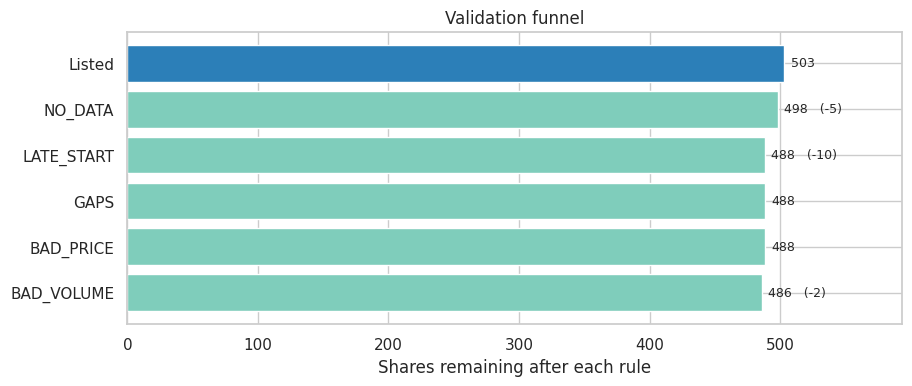

,ticker,rule,detail
0,FDXF,NO_DATA,No prices downloaded
1,HONA,NO_DATA,No prices downloaded
2,Q,NO_DATA,No prices downloaded
3,SNDK,NO_DATA,No prices downloaded
4,VYLR,NO_DATA,No prices downloaded
5,APP,LATE_START,First price on 2021-04-15 (benchmark starts 20...
6,CEG,LATE_START,First price on 2022-01-19 (benchmark starts 20...
7,COIN,LATE_START,First price on 2021-04-14 (benchmark starts 20...
8,EXE,LATE_START,First price on 2021-02-10 (benchmark starts 20...
9,GEHC,LATE_START,First price on 2022-12-15 (benchmark starts 20...


In [7]:
#  1.2b  VALIDATION RULES AND DROP LOG
# A share is kept only if it passes ALL five rules. Missing prices are never filled.
first_day = trading_days[0]
has_price = adj.notna()
first_price = has_price.idxmax()                         # first date with a price, for each share

flag = {}                                                # rule name -> set of shares that fail it
flag["NO_DATA"] = set(adj.columns[~has_price.any()])     # nothing was downloaded at all
flag["LATE_START"] = {t for t in adj.columns            # history starts after the first benchmark day
                      if t not in flag["NO_DATA"] and first_price[t] > first_day}
missing_cells = adj.isna().sum() + close.isna().sum() + volume.isna().sum()
flag["GAPS"] = {t for t in adj.columns                   # holes inside an otherwise full history
                if missing_cells[t] > 0 and t not in flag["NO_DATA"] and t not in flag["LATE_START"]}
flag["BAD_PRICE"] = set(adj.columns[((adj <= 0) | (close <= 0)).any()])    # price of zero or below
flag["BAD_VOLUME"] = set(adj.columns[(volume <= 0).any()])                  # volume of zero or below

# Write one log row for every rule a share fails, with the evidence
log_rows = []
for rule in ["NO_DATA", "LATE_START", "GAPS", "BAD_PRICE", "BAD_VOLUME"]:
    for t in sorted(flag[rule]):
        if rule == "NO_DATA":
            detail = "No prices downloaded"
        elif rule == "LATE_START":
            detail = "First price on " + str(first_price[t].date()) + " (benchmark starts " + str(first_day.date()) + ")"
        elif rule == "GAPS":
            detail = str(int(missing_cells[t])) + " missing cells in prices or volume"
        elif rule == "BAD_PRICE":
            detail = str(int(((adj[t] <= 0) | (close[t] <= 0)).sum())) + " day(s) with price <= 0"
        else:
            bad_days = volume.index[volume[t] <= 0]
            detail = str(len(bad_days)) + " day(s) with volume <= 0, first on " + str(bad_days[0].date())
        log_rows.append((t, rule, detail))
drop_log = pd.DataFrame(log_rows, columns=["ticker", "rule", "detail"])

dropped = set().union(*flag.values())
kept_shares = [t for t in share_list if t not in dropped]     # shares that passed every rule

print("Shares listed  :", len(share_list))
print("Shares dropped :", len(dropped))
print("Shares kept    :", len(kept_shares))
print()
print("Failures by rule (a share can fail more than one):")
print(drop_log["rule"].value_counts().to_string())

drop_log.to_csv(os.path.join(DATA_DIR, "drop_log.csv"), index=False)
pd.Series(kept_shares, name="ticker").to_csv(os.path.join(DATA_DIR, "kept_shares.csv"), index=False)

# Picture: how many shares are left after each rule is applied in turn
remaining = set(share_list)
labels, counts, removed_n = ["Listed"], [len(share_list)], [0]
for rule in ["NO_DATA", "LATE_START", "GAPS", "BAD_PRICE", "BAD_VOLUME"]:
    removed = remaining & flag[rule]
    remaining = remaining - removed
    labels.append(rule); counts.append(len(remaining)); removed_n.append(len(removed))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(range(len(labels)), counts, color=["#2c7fb8"] + ["#7fcdbb"] * (len(labels) - 1))
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels); ax.invert_yaxis()
for i, (c, r) in enumerate(zip(counts, removed_n)):
    ax.text(c + len(share_list) * 0.01, i, str(c) + ("   (-" + str(r) + ")" if r else ""), va="center", fontsize=9)
ax.set_xlim(0, len(share_list) * 1.18)
ax.set_xlabel("Shares remaining after each rule")
ax.set_title("Validation funnel")
plt.savefig(os.path.join(FIG_DIR, "validation_funnel.png"), dpi=150, bbox_inches="tight")
plt.show()
drop_log

In [8]:
#  1.2c  CORPORATE ACTIONS: DIVIDENDS AND BIG PRICE JUMPS
adj_k, close_k, vol_k = adj[kept_shares], close[kept_shares], volume[kept_shares]   # kept shares only

# (i) Dividends: Adj Close should be BELOW Close at the start if dividends were paid since
ratio_first = adj_k.iloc[0] / close_k.iloc[0]
print("Shares where Adj Close < Close on the first day (dividends adjusted):", int((ratio_first < 0.9999).sum()), "of", len(kept_shares))
print("Shares where Adj Close > Close on the first day (unexpected)        :", int((ratio_first > 1.0001).sum()))

# (ii) Splits: an unadjusted split shows up as one very large daily move in Close.
# 30% is used (not more) so that a 3-for-2 split, which is a 33% fall, would still be caught.
BIG_MOVE = 0.30
close_ret = close_k.pct_change(fill_method=None)
adj_ret = adj_k.pct_change(fill_method=None)
row_i, col_i = np.where(close_ret.abs().values > BIG_MOVE)        # positions of every big move
big_moves = pd.DataFrame({"date": close_ret.index[row_i], "ticker": close_ret.columns[col_i],
                          "close_return": close_ret.values[row_i, col_i],
                          "adj_close_return": adj_ret.values[row_i, col_i]})
big_moves = big_moves.sort_values(["ticker", "date"]).reset_index(drop=True)
print("Days with a one-day Close move above", int(BIG_MOVE * 100), "%:", len(big_moves), "across", big_moves["ticker"].nunique(), "shares")
big_moves

Shares where Adj Close < Close on the first day (dividends adjusted): 398 of 486
Shares where Adj Close > Close on the first day (unexpected)        : 0
Days with a one-day Close move above 30 %: 33 across 17 shares


,date,ticker,close_return,adj_close_return
0,2021-10-25,BE,0.3715,0.3715
1,2024-11-15,BE,0.5919,0.5919
2,2021-06-07,BIIB,0.3834,0.3834
3,2022-09-28,BIIB,0.3985,0.3985
4,2022-08-05,CVNA,0.4007,0.4007
5,2022-11-04,CVNA,-0.3895,-0.3895
6,2022-11-10,CVNA,0.3162,0.3162
7,2022-12-07,CVNA,-0.4292,-0.4292
8,2023-01-12,CVNA,0.4600,0.4600
9,2023-02-01,CVNA,0.3333,0.3333


In [9]:
# 1.2d  CORPORATE ACTIONS: ADJUSTMENT-FACTOR CHECK
adj_ratio = adj_k / close_k                                  # adjustment factor: Adj Close divided by Close, every share, every day
ratio_change = adj_ratio.pct_change(fill_method=None)        # one-day % change in that factor

changes = ratio_change.stack()                               # flatten to one row per (date, share); empty values are skipped
changes = changes[changes.abs() > 0.01]                      # keep only changes bigger than 1% (ordinary dividends and above)
adjustments = changes.reset_index()                          # turn the result into a normal table
adjustments.columns = ["date", "ticker", "ratio_pct_change"] # give the three columns clear names

adjustments["type"] = np.where(                              # label each event
    adjustments["ratio_pct_change"] < 0, "CHECK: factor fell",            # a dividend can never make the factor fall
    np.where(adjustments["ratio_pct_change"] > 0.05, "CHECK: jump above 5%",   # too big for a normal dividend
             "Dividend-sized step"))                         # everything else looks like an ordinary dividend

print("Adjustment events above 1%:", len(adjustments), "across", adjustments["ticker"].nunique(), "shares")
print(adjustments["type"].value_counts().to_string())        # how many events of each type
display(adjustments[adjustments["type"].str.startswith("CHECK")])   # show only events that need a manual look

# --- Verdict for every big Close move found in 1.2c ---
big_moves["verdict"] = np.where(                             # if the adjusted return is also large...
    big_moves["adj_close_return"].abs() > BIG_MOVE / 2,      # ...both price columns agree
    "Real price move", "CHECK: columns disagree")            # so label it real, or flag it
print(big_moves["verdict"].value_counts().to_string())       # how many of each verdict

adjustments.to_csv(os.path.join(DATA_DIR, "adjustment_events.csv"), index=False)   # save evidence for GitHub
big_moves.to_csv(os.path.join(DATA_DIR, "big_moves.csv"), index=False)             # save this too
big_moves                                                    # show the big moves with the verdict column

Adjustment events above 1%: 805 across 118 shares
type
Dividend-sized step     801
CHECK: jump above 5%      4


,date,ticker,ratio_pct_change,type
186,2022-06-03,LYB,0.0587,CHECK: jump above 5%
335,2023-02-10,F,0.0630,CHECK: jump above 5%
760,2024-10-04,TDG,0.0558,CHECK: jump above 5%
777,2024-11-18,ACGL,0.0516,CHECK: jump above 5%


verdict
Real price move    33


,date,ticker,close_return,adj_close_return,verdict
0,2021-10-25,BE,0.3715,0.3715,Real price move
1,2024-11-15,BE,0.5919,0.5919,Real price move
2,2021-06-07,BIIB,0.3834,0.3834,Real price move
3,2022-09-28,BIIB,0.3985,0.3985,Real price move
4,2022-08-05,CVNA,0.4007,0.4007,Real price move
5,2022-11-04,CVNA,-0.3895,-0.3895,Real price move
6,2022-11-10,CVNA,0.3162,0.3162,Real price move
7,2022-12-07,CVNA,-0.4292,-0.4292,Real price move
8,2023-01-12,CVNA,0.4600,0.4600,Real price move
9,2023-02-01,CVNA,0.3333,0.3333,Real price move


In [10]:
# ===================== 1.2d (continued)  SPLIT-LIKE MOVES AND RFM HISTORY CHECK =====================
price_ratio = close_k / close_k.shift(1)                       # today's Close divided by yesterday's Close, every share
split_sizes = [1/2, 1/3, 1/4, 1/5, 1/10, 1/20, 2, 3, 4, 5, 10, 20]   # common split sizes (below 1 = split, above 1 = reverse split)
split_like = pd.DataFrame(False, index=price_ratio.index, columns=price_ratio.columns)   # start with "no match" everywhere
for size in split_sizes:                                       # try each common split size in turn
    split_like |= (price_ratio / size - 1).abs() < 0.03        # mark days where the price ratio is within 3% of that size

split_flags = price_ratio.where(split_like).stack().reset_index()   # keep only the matching days, one row each
split_flags.columns = ["date", "ticker", "price_ratio"]        # clear column names
print("Days where a price move looks like a split:", len(split_flags), "across", split_flags["ticker"].nunique(), "shares")
display(split_flags)                                           # empty table = no split-like moves

# --- Is there enough history for the RFM windows? (20-session baseline + 60-session activity window) ---
need = BASELINE_DAYS + ACTIVITY_DAYS                           # 80 sessions in total
print("Sessions available:", len(close_k), "| needed:", need)  # how much history we have versus need
for name, table in [("Close", close_k), ("Volume", vol_k)]:    # check the two tables that RFM uses
    missing_recent = int(table.iloc[-need:].isna().any().sum())   # shares with any gap in the latest 80 sessions
    print(name, "- shares with a gap in the latest", need, "sessions:", missing_recent)   # should be 0
assert len(close_k) >= need                                    # stop with an error if history is too short

Days where a price move looks like a split: 0 across 0 shares


,date,ticker,price_ratio


Sessions available: 1005 | needed: 80
Close - shares with a gap in the latest 80 sessions: 0
Volume - shares with a gap in the latest 80 sessions: 0


In [11]:
# 1.2e  WEEKLY PRICES (FRIDAY-ENDING)
bench_k = adj_all[INDEX_TICKER].reindex(trading_days)        # benchmark adjusted prices on the common calendar
adj_week = adj_k.resample("W-FRI").last()                    # last trading price of each Friday-ending week, every kept share
bench_week = bench_k.resample("W-FRI").last()                # same for the S&P 500 benchmark
days_in_week = bench_k.resample("W-FRI").count()             # how many trading days each week had (4 = holiday week)

week_monday = adj_week.index - pd.Timedelta(days=4)          # the Monday of every week label (Friday minus 4 days)
complete = (week_monday >= pd.Timestamp(STUDY_START)) & (adj_week.index < pd.Timestamp(STUDY_END))   # True only for complete weeks
print("Week labels dropped as incomplete:", [d.date() for d in adj_week.index[~complete]])   # show exactly which weeks are removed

adj_week = adj_week.loc[complete]                            # keep complete weeks only (shares)
bench_week = bench_week.loc[complete]                        # keep the same weeks (benchmark)
days_in_week = days_in_week.loc[complete]                    # keep the same weeks (day counts)

print("Weekly price points :", len(adj_week), "| first:", adj_week.index[0].date(), "| last:", adj_week.index[-1].date())
print("Holiday-shortened weeks kept (fewer than 5 trading days):", int((days_in_week < 5).sum()))

Week labels dropped as incomplete: [datetime.date(2025, 1, 3)]
Weekly price points : 208 | first: 2021-01-08 | last: 2024-12-27
Holiday-shortened weeks kept (fewer than 5 trading days): 37


Aligned weekly return observations: 207
First return week: 2021-01-15 | last: 2024-12-27
Shares with weekly returns: 486
All checks passed: identical labels, no gaps, no fills, no non-positive prices


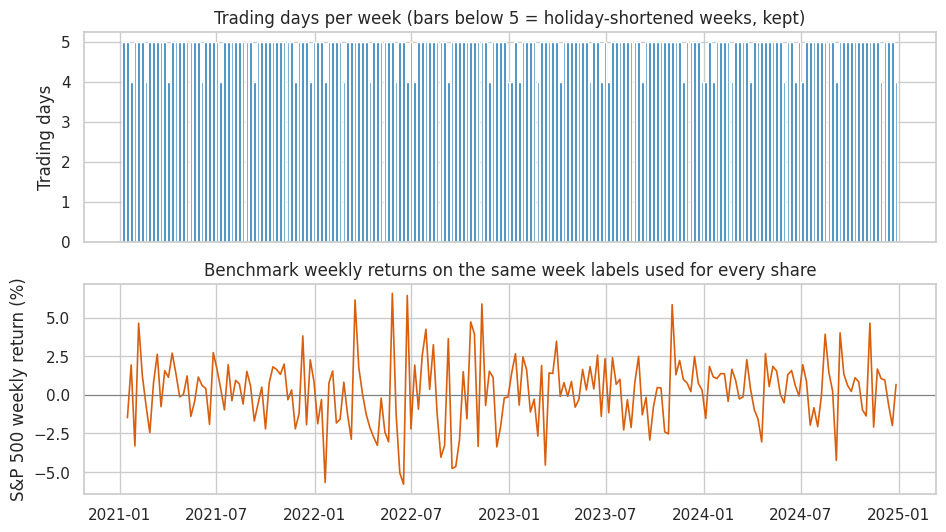

In [12]:
#  1.2f  WEEKLY RETURNS AND ALIGNMENT CHECKS
ret_week = adj_week.pct_change(fill_method=None).iloc[1:]         # share weekly returns; drop the first row (no earlier week to compare to)
bench_ret_week = bench_week.pct_change(fill_method=None).iloc[1:] # benchmark weekly returns, same method

# --- Checks (each stops the code with an error if it fails) ---
assert ret_week.index.equals(bench_ret_week.index), "Week labels differ between shares and benchmark"   # identical week labels
assert ret_week.notna().all().all(), "A share has a missing weekly return"                              # nothing silently filled
gaps_between_weeks = ret_week.index.to_series().diff().dropna().dt.days                                 # days between consecutive week labels
assert (gaps_between_weeks == 7).all(), "A return spans more than one week"                             # every return is a 1-week return
assert (adj_week > 0).all().all(), "A weekly price is zero or negative"                                 # no non-positive prices

N_WEEKS = len(ret_week)                                           # number of aligned weekly observations (report this number)
print("Aligned weekly return observations:", N_WEEKS)
print("First return week:", ret_week.index[0].date(), "| last:", ret_week.index[-1].date())
print("Shares with weekly returns:", ret_week.shape[1])
print("All checks passed: identical labels, no gaps, no fills, no non-positive prices")

# --- Save the weekly tables (evidence for GitHub) ---
adj_week.to_csv(os.path.join(DATA_DIR, "weekly_adj_close.csv"))               # weekly prices
ret_week.to_csv(os.path.join(DATA_DIR, "weekly_returns_shares.csv"))          # weekly share returns
bench_ret_week.to_csv(os.path.join(DATA_DIR, "weekly_returns_benchmark.csv")) # weekly benchmark returns

# --- Chart: trading days per week, and the benchmark's weekly return ---
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)      # two stacked panels sharing the date axis
axes[0].bar(days_in_week.index, days_in_week.values, width=5, color="#2c7fb8")   # bars = trading days in each week
axes[0].set_ylabel("Trading days")                                # y label for the top panel
axes[0].set_title("Trading days per week (bars below 5 = holiday-shortened weeks, kept)")   # explains what to look for
axes[1].plot(bench_ret_week.index, bench_ret_week.values * 100, color="#d95f0e", lw=1.2)   # benchmark weekly return in %
axes[1].axhline(0, color="grey", lw=0.8)                          # zero line for reference
axes[1].set_ylabel("S&P 500 weekly return (%)")                   # y label for the bottom panel
axes[1].set_title("Benchmark weekly returns on the same week labels used for every share")
plt.savefig(os.path.join(FIG_DIR, "weekly_alignment.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                        # display it

1.3  Weekly return and weekly beta

In [13]:
#  1.3a  MEAN WEEKLY RETURN AND WEEKLY BETA
assert ret_week.index.equals(bench_ret_week.index)                # share and benchmark use identical week labels
assert ret_week.notna().all().all() and bench_ret_week.notna().all()   # no missing weekly returns anywhere (nothing filled)

# --- Price basis check for the benchmark ---
basis_gap = (adj_all[INDEX_TICKER] - close_all[INDEX_TICKER]).abs().max()   # biggest difference between Adj Close and Close
print("Benchmark: max |Adj Close - Close| =", round(float(basis_gap), 6))   # 0 means the index has no dividend adjustment (price-return index)

# --- 1.3.1 Mean weekly return ---
mean_ret = ret_week.mean()                                        # arithmetic mean of each share's weekly returns
n_obs = ret_week.count()                                          # number of weekly returns used for each share

# --- 1.3.2 Weekly beta ---
bench_var = bench_ret_week.var()                                  # variance of the benchmark's weekly returns
beta = ret_week.apply(lambda col: col.cov(bench_ret_week)) / bench_var   # covariance with the benchmark divided by its variance

# --- Sanity checks ---
assert np.isclose(bench_ret_week.cov(bench_ret_week) / bench_var, 1.0)   # the benchmark's own beta must be exactly 1
assert (n_obs == N_WEEKS).all()                                   # every share uses the same 207 aligned weeks

# --- Feature table: one row per included share ---
risk_return = pd.DataFrame({"mean_weekly_return": mean_ret, "weekly_beta": beta, "n_weeks": n_obs})   # combine the columns
risk_return.index.name = "ticker"                                 # name the index so it merges cleanly later
risk_return.to_csv(os.path.join(DATA_DIR, "risk_return_features.csv"))   # save for GitHub

print("Shares:", len(risk_return), "| aligned weekly observations per share:", N_WEEKS)
display(risk_return.describe().T)                                 # summary of each feature
display(risk_return.sort_values("weekly_beta").head(5))           # 5 lowest-beta shares
display(risk_return.sort_values("weekly_beta").tail(5))           # 5 highest-beta shares

Benchmark: max |Adj Close - Close| = 0.0
Shares: 486 | aligned weekly observations per share: 207


,count,mean,std,min,25%,50%,75%,max
mean_weekly_return,486.0000,0.0029,0.0027,-0.0045,0.0012,0.0026,0.0042,0.0178
weekly_beta,486.0000,0.9737,0.4073,0.0555,0.6666,0.9506,1.1795,3.7786
n_weeks,486.0000,207.0000,0.0000,207.0000,207.0000,207.0000,207.0000,207.0000


,mean_weekly_return,weekly_beta,n_weeks
ticker,,,
GIS,0.0015,0.0555,207
SJM,0.0008,0.1756,207
MRK,0.0021,0.1983,207
BMY,0.0008,0.2250,207
KHC,0.0009,0.2272,207


,mean_weekly_return,weekly_beta,n_weeks
ticker,,,
TWLO,-0.0022,2.0734,207
NVDA,0.0136,2.1260,207
COHR,0.0039,2.1393,207
XYZ,-0.0016,2.5045,207
CVNA,0.0110,3.7786,207


In [14]:
#  1.3b  WORKED EXAMPLE FOR ONE SHARE
from scipy import stats                                           # for a regression-based second method

ex = "AAPL" if "AAPL" in ret_week.columns else ret_week.columns[0]   # Apple if available, otherwise the first share
p = adj_week[ex]                                                  # the example share's Friday adjusted prices
manual_ret = p.iloc[1:].values / p.iloc[:-1].values - 1           # recompute returns by hand: this week / last week - 1
x = bench_ret_week.values                                         # benchmark weekly returns as an array
y = ret_week[ex].values                                           # the pipeline's returns for the example share

beta_manual = np.cov(y, x, ddof=1)[0, 1] / np.var(x, ddof=1)      # method 1: covariance divided by variance (numpy)
beta_regress = stats.linregress(x, y).slope                       # method 2: regression slope (must give the same answer)

assert np.allclose(manual_ret, y)                                 # hand-calculated returns match the pipeline
assert np.isclose(mean_ret[ex], manual_ret.mean())                # mean return matches
assert np.isclose(beta[ex], beta_manual) and np.isclose(beta[ex], beta_regress)   # all beta methods agree

print("Example share:", ex, "| weeks used:", len(y))
print("Mean weekly return:", round(float(mean_ret[ex]), 6))
print("Beta (pipeline / numpy / regression):", round(float(beta[ex]), 4), round(float(beta_manual), 4), round(float(beta_regress), 4))
display(pd.DataFrame({                                            # first weeks laid out so a marker can follow the arithmetic
    "week_end": p.index[:4], "adj_close": p.values[:4],
    "weekly_return": [np.nan, *manual_ret[:3]],
    "benchmark_return": [np.nan, *x[:3]]}))

Example share: AAPL | weeks used: 207
Mean weekly return: 0.00393
Beta (pipeline / numpy / regression): 1.1748 1.1748 1.1748


,week_end,adj_close,weekly_return,benchmark_return
0,2021-01-08,128.0981,NaN,NaN
1,2021-01-15,123.3351,-0.0372,-0.0148
2,2021-01-22,134.9080,0.0938,0.0194
3,2021-01-29,128.0108,-0.0511,-0.0331


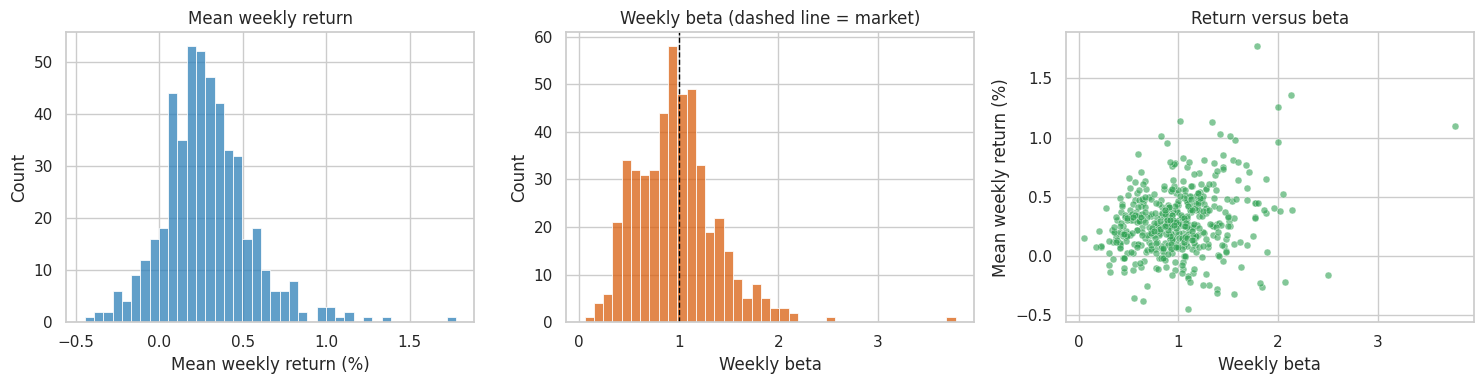

In [15]:
# 1.3b  FEATURE DISTRIBUTION CHARTS
fig, axes = plt.subplots(1, 3, figsize=(15, 4))                   # three charts side by side
sns.histplot(risk_return["mean_weekly_return"] * 100, bins=40, ax=axes[0], color="#2c7fb8")   # distribution of mean return (%)
axes[0].set_xlabel("Mean weekly return (%)"); axes[0].set_title("Mean weekly return")         # label and title
sns.histplot(risk_return["weekly_beta"], bins=40, ax=axes[1], color="#d95f0e")                # distribution of beta
axes[1].axvline(1, color="black", ls="--", lw=1)                  # beta = 1 means "moves with the market"
axes[1].set_xlabel("Weekly beta"); axes[1].set_title("Weekly beta (dashed line = market)")    # label and title
sns.scatterplot(x=risk_return["weekly_beta"], y=risk_return["mean_weekly_return"] * 100, s=25, alpha=0.6, color="#31a354", ax=axes[2])   # return vs beta
axes[2].set_xlabel("Weekly beta"); axes[2].set_ylabel("Mean weekly return (%)"); axes[2].set_title("Return versus beta")   # labels
plt.tight_layout()                                                # prevent overlapping labels between panels
plt.savefig(os.path.join(FIG_DIR, "risk_return_features.png"), dpi=150, bbox_inches="tight")  # save for the report
plt.show()                                                        # display the figure

1.4 Adapted RFM Calculations

In [16]:
# 1.4.0  SETUP AND HIGH-VOLUME EVENT FLAGS
import matplotlib.dates as mdates                                  # needed for date formatting on the charts

OBS_DATE = trading_days[-1]                                        # observation date = last common trading day (31 Dec 2024)
need = BASELINE_DAYS + ACTIVITY_DAYS                               # 20 baseline + 60 activity sessions = 80 in total
window = vol_k.index[-ACTIVITY_DAYS:]                              # the latest 60 trading sessions ending on the observation date
assert len(vol_k) >= need                                          # stop if there is not enough history
assert len(window) == ACTIVITY_DAYS                                # the window must hold exactly 60 sessions
assert close_k.loc[window].notna().all().all() and vol_k.loc[window].notna().all().all()   # no gaps in the window
print("Observation date:", OBS_DATE.date())
print("Latest", ACTIVITY_DAYS, "sessions:", window[0].date(), "to", window[-1].date())

# --- Rolling threshold, separately for every share and day ---
baseline = vol_k.shift(1).rolling(BASELINE_DAYS, min_periods=BASELINE_DAYS).mean()   # mean of the PREVIOUS 20 sessions (shift(1) leaves out the tested day)
threshold = SPIKE_FACTOR * baseline                                # twice that mean is the threshold
event = vol_k > threshold                                          # True on a high-volume day; no baseline means False
print("Total high-volume share-days flagged:", int(event.sum().sum()), "across", event.shape[1], "shares")

# --- Checks: alignment and no look-ahead ---
assert not event.iloc[:BASELINE_DAYS].any().any()                  # the first 20 sessions have no baseline, so no events there
assert baseline.loc[window].notna().all().all()                    # every day in the window has a full 20-session baseline
rng = np.random.default_rng(42)                                    # fixed seed so the same shares are checked each run
for t in rng.choice(event.columns, 3, replace=False):              # check 3 random shares with a plain loop
    v = vol_k[t].to_numpy(dtype=float)                             # that share's volume as an array
    naive = np.zeros(len(v), dtype=bool)                           # start with "no event" on every day
    for i in range(BASELINE_DAYS, len(v)):                         # first day with a full baseline is session 21
        naive[i] = v[i] > SPIKE_FACTOR * v[i - BASELINE_DAYS:i].mean()   # today against 2 x mean of the previous 20 days
    assert np.array_equal(naive, event[t].to_numpy()), "Mismatch for " + t   # the loop must match the pipeline exactly
print("Manual rolling-threshold checks passed: previous 20 sessions only, no look-ahead")

Observation date: 2024-12-31
Latest 60 sessions: 2024-10-07 to 2024-12-31
Total high-volume share-days flagged: 18280 across 486 shares
Manual rolling-threshold checks passed: previous 20 sessions only, no look-ahead


Shares with no event (Recency missing): 0
Shares with an event on the observation date (R = 0): 0


,Recency
count,486.0000
mean,20.4074
std,21.3424
min,4.0000
25%,11.0000
50%,11.0000
75%,14.7500
max,222.0000


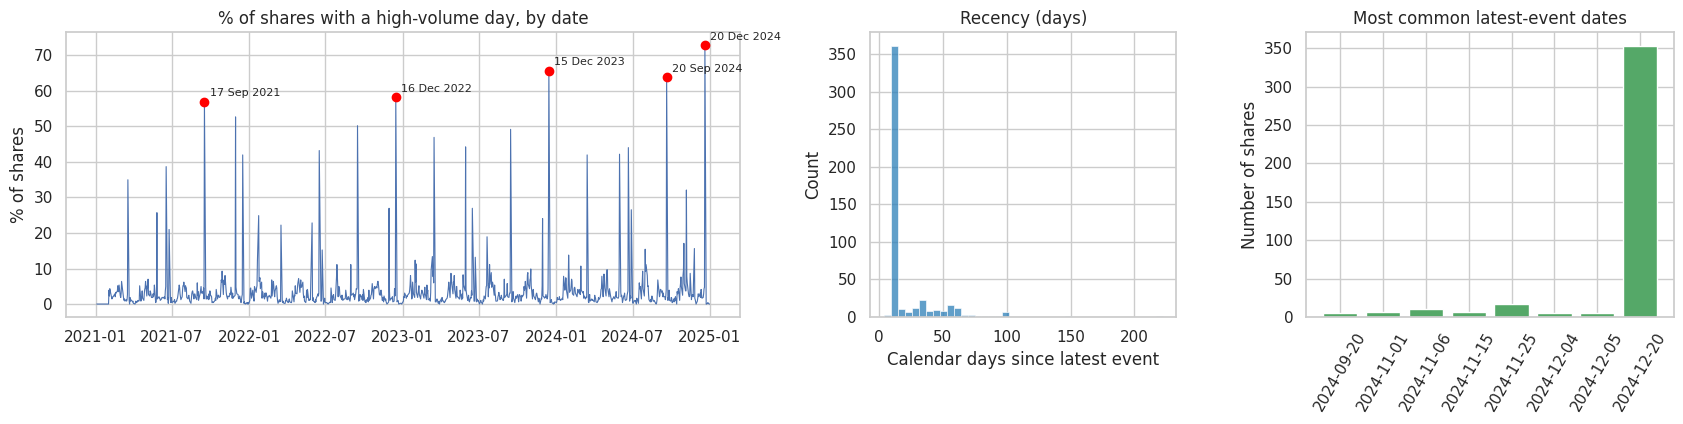

In [17]:
# 1.4.1  RECENCY
last_event_date = pd.to_datetime(pd.Series({                       # latest event date for each share
    t: (event.index[event[t].to_numpy()].max() if event[t].any() else pd.NaT)   # latest event day, or NaT if the share never had one
    for t in event.columns}))
recency = (OBS_DATE - last_event_date).dt.days                     # calendar days (weekends and holidays included); NaT becomes NaN, never 0

print("Shares with no event (Recency missing):", int(recency.isna().sum()))
print("Shares with an event on the observation date (R = 0):", int((recency == 0).sum()))
display(recency.describe().to_frame("Recency"))                    # count, mean, quartiles, min, max

# --- Charts: market-wide spike days, Recency distribution, most common "latest event" dates ---
breadth = event.mean(axis=1) * 100                                 # % of shares with a high-volume day on each date
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={"width_ratios": [2.2, 1, 1.2]})   # three panels side by side
axes[0].plot(breadth.index, breadth.values, lw=0.8, color="#4C72B0")   # line of breadth through time
for day, val in breadth.nlargest(5).items():                       # mark the five busiest days
    axes[0].scatter(day, val, color="red", zorder=3)               # red dot on the day
    axes[0].annotate(day.strftime("%d %b %Y"), (day, val), textcoords="offset points", xytext=(4, 4), fontsize=8)   # date label
axes[0].set_title("% of shares with a high-volume day, by date")   # left panel title
axes[0].set_ylabel("% of shares")                                  # left panel y label
sns.histplot(recency.dropna(), bins=40, ax=axes[1], color="#2c7fb8")   # distribution of Recency
axes[1].set_title("Recency (days)")                                # middle panel title
axes[1].set_xlabel("Calendar days since latest event")             # middle panel x label
common_last = last_event_date.dropna().dt.strftime("%Y-%m-%d").value_counts().head(8).sort_index()   # 8 most common latest-event dates
axes[2].bar(common_last.index, common_last.values, color="#55A868")   # bar chart of those dates
axes[2].set_title("Most common latest-event dates")                # right panel title
axes[2].set_ylabel("Number of shares")                             # right panel y label
axes[2].tick_params(axis="x", rotation=60)                         # tilt the date labels so they fit
plt.tight_layout()                                                 # stop the panels overlapping
plt.savefig(os.path.join(FIG_DIR, "recency.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                         # display

,Frequency
count,486.0000
mean,2.9897
std,1.3308
min,0.0000
25%,2.0000
50%,3.0000
75%,4.0000
max,8.0000


Shares with F = 0: 10


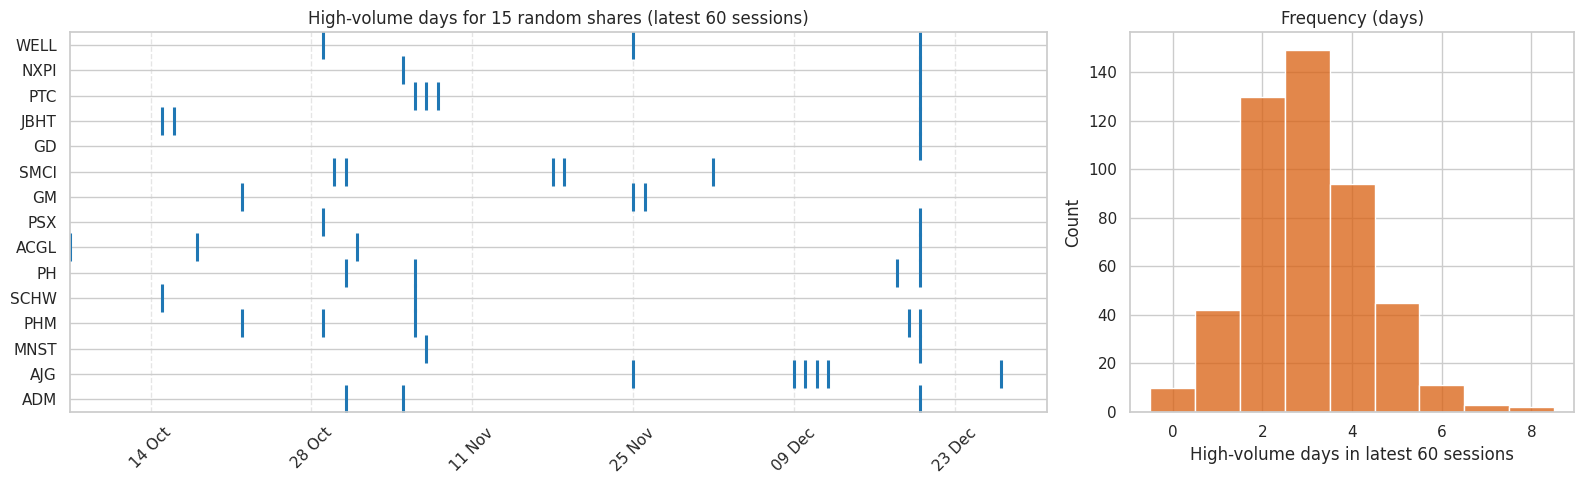

In [18]:
# 1.4.2  FREQUENCY
frequency = event.loc[window].sum()                                # high-volume days inside the latest 60 sessions, per share
display(frequency.describe().to_frame("Frequency"))                # count, mean, quartiles, min, max
print("Shares with F = 0:", int((frequency == 0).sum()))           # shares with no event in the window (valid, not an error)

# --- Charts: event timelines for 15 random shares, and the Frequency distribution ---
event_window = event.loc[window]                                   # events restricted to the 60-session window
rng = np.random.default_rng(42)                                    # fixed seed so the same sample is drawn each run
sample_shares = rng.choice(event_window.columns, min(15, event_window.shape[1]), replace=False)   # 15 random shares
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [2.2, 1]})   # two panels side by side
for i, share in enumerate(sample_shares):                          # one row per sampled share
    days_hit = event_window.index[event_window[share].to_numpy()]  # dates when that share had an event
    axes[0].scatter(days_hit, [i] * len(days_hit), marker="|", s=400, color="#1f77b4", linewidth=2.2)   # a tick mark on each event day
axes[0].set_yticks(range(len(sample_shares)))                      # one y position per share
axes[0].set_yticklabels(sample_shares)                             # label each row with its ticker
axes[0].set_ylim(-0.5, len(sample_shares) - 0.5)                   # tidy vertical limits
axes[0].set_xlim(window[0], window[-1])                            # x axis covers exactly the 60-session window
axes[0].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO, interval=2))   # a tick every second Monday
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))   # show dates as "05 Nov"
axes[0].tick_params(axis="x", rotation=45)                         # tilt the date labels
axes[0].set_title("High-volume days for 15 random shares (latest 60 sessions)")   # left panel title
axes[0].grid(True, axis="x", linestyle="--", alpha=0.5)            # light vertical grid lines
sns.histplot(frequency, discrete=True, ax=axes[1], color="#d95f0e")   # distribution of Frequency
axes[1].set_title("Frequency (days)")                              # right panel title
axes[1].set_xlabel("High-volume days in latest 60 sessions")       # right panel x label
plt.tight_layout()                                                 # stop the panels overlapping
plt.savefig(os.path.join(FIG_DIR, "frequency.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                         # display

,Monetary (USD)
count,486.0000
mean,"39,404,191,889.2078"
std,"129,138,833,232.9717"
min,"1,297,482,617.0479"
25%,"10,195,173,392.2705"
50%,"16,683,821,504.6230"
75%,"32,276,893,043.8724"
max,"1,847,697,379,221.8428"


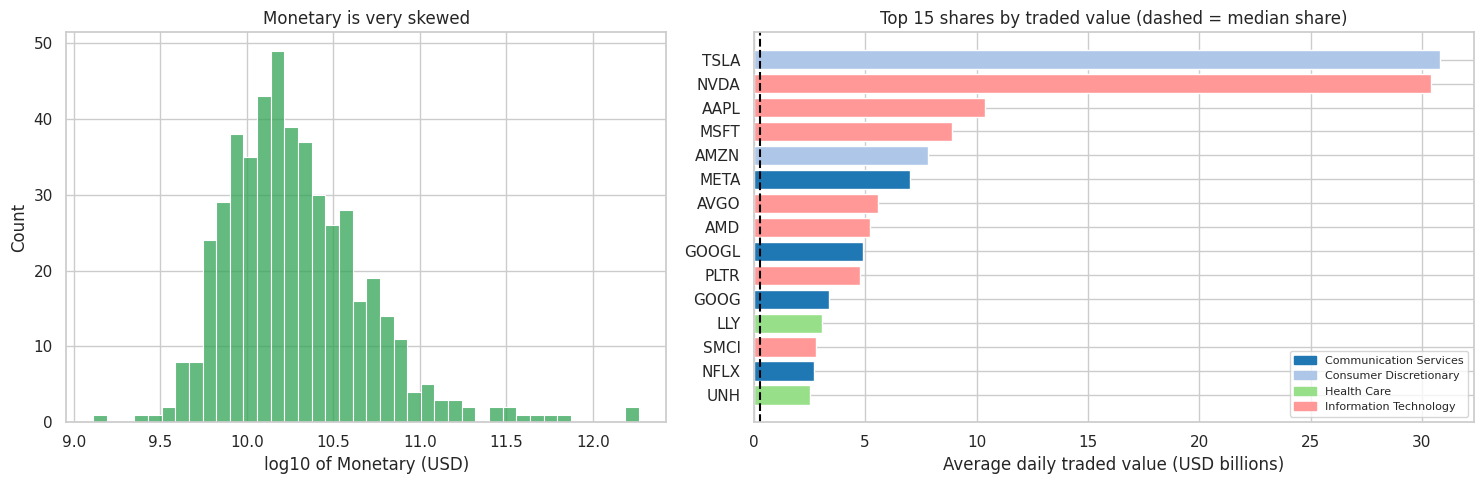

In [19]:
# 1.4.3  MONETARY
daily_traded_value = close_k.loc[window] * vol_k.loc[window]       # approximate USD traded each day (Close x Volume), per share
monetary = daily_traded_value.sum()                                # add the 60 daily values to get M in USD
display(monetary.describe().to_frame("Monetary (USD)"))           # count, mean, quartiles, min, max

# --- Charts: skewness, and the most liquid shares coloured by sector ---
sector_of = sp500_list.set_index("ticker")["gics_sector"]           # sector for each ticker (using 'gics_sector' from the loaded workbook)
palette = dict(zip(sorted(sector_of.unique()), sns.color_palette("tab20", sector_of.nunique())))
top15 = (monetary / ACTIVITY_DAYS / 1e9).nlargest(15).iloc[::-1]   # 15 largest by average daily traded value, in USD billions
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.2]})
sns.histplot(np.log10(monetary), bins=40, ax=axes[0], color="#31a354")   # M on a log10 scale
axes[0].set_xlabel("log10 of Monetary (USD)")
axes[0].set_title("Monetary is very skewed")
axes[1].barh(top15.index, top15.values, color=[palette[sector_of[t]] for t in top15.index])
axes[1].axvline(monetary.median() / ACTIVITY_DAYS / 1e9, color="black", ls="--")
axes[1].set_xlabel("Average daily traded value (USD billions)")
axes[1].set_title("Top 15 shares by traded value (dashed = median share)")
used = sorted({sector_of[t] for t in top15.index})
axes[1].legend([plt.Rectangle((0, 0), 1, 1, color=palette[s]) for s in used], used, fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "monetary.png"), dpi=150, bbox_inches="tight")
plt.show()

In [20]:
#  1.4.4  FEATURE TABLE FOR THE COMMON SHARE SET
rfm_cols = pd.DataFrame({"R_days": recency, "F_days": frequency, "M_usd": monetary, "last_high_volume_date": last_event_date})   # the RFM features

# Map correct columns from sp500_list ('security' -> 'company', 'gics_sector' -> 'sector') to avoid KeyError
metadata_df = sp500_list.set_index("ticker")[["security", "gics_sector"]].rename(columns={"security": "company", "gics_sector": "sector"})

features = risk_return.join(rfm_cols).join(metadata_df)   # add return, beta and company details
core = ["mean_weekly_return", "weekly_beta", "R_days", "F_days", "M_usd"]   # the five features used for clustering
features_final = features.dropna(subset=core).copy()               # keep only shares that have all five features
features_final["R_days"] = features_final["R_days"].astype(int)    # Recency as whole days
features_final["F_days"] = features_final["F_days"].astype(int)    # Frequency as whole days
features_final = features_final[["company", "sector"] + [c for c in features_final.columns if c not in ("company", "sector")]]   # company and sector first
common_shares = features_final.index.tolist()                      # the common valid share set for every clustering comparison

# --- Log extra exclusions caused by a missing Recency (no event ever) ---
extra_excluded = features.index.difference(features_final.index)   # shares dropped at this stage
rfm_exclusions = pd.DataFrame({"ticker": extra_excluded, "rule": "NO_EVENT",
                               "detail": "No qualifying high-volume event in valid history (Recency missing)"})   # one log row each
drop_log_full = pd.concat([drop_log, rfm_exclusions], ignore_index=True)   # join to the 1.2b exclusion log
drop_log_full.to_csv(os.path.join(DATA_DIR, "drop_log_full.csv"), index=False)   # save the complete inclusion/exclusion log
features_final.to_csv(os.path.join(DATA_DIR, "features_table.csv"))   # save the feature table (CSV)
features_final.to_excel(os.path.join(DATA_DIR, "features_table.xlsx"))   # and as Excel
display(features_final.head())								   # preview
print("Final common share set:", len(features_final), "| extra exclusions (no event):", len(extra_excluded))

,company,sector,mean_weekly_return,weekly_beta,n_weeks,R_days,F_days,M_usd,last_high_volume_date
ticker,,,,,,,,,
MMM,3M,Industrials,0.0011,0.8691,207,11,4,"25,991,458,733.3420",2024-12-20
AOS,A. O. Smith,Industrials,0.0020,1.0428,207,11,2,"4,748,980,279.6021",2024-12-20
ABT,Abbott Laboratories,Health Care,0.0010,0.5835,207,11,1,"35,230,272,606.2744",2024-12-20
ABBV,AbbVie,Health Care,0.0037,0.4254,207,11,3,"68,370,537,641.6611",2024-12-20
ACN,Accenture,Information Technology,0.0024,1.1433,207,11,2,"51,994,299,403.1158",2024-12-20


Final common share set: 486 | extra exclusions (no event): 0


Example share: AAPL | observation date: 2024-12-31
R = 11 | latest event: 2024-12-20
F = 2 high-volume days in the latest 60 sessions
M = $623,303,377,707 approximate traded value over 60 sessions


,date,volume,mean_previous_20,threshold_2x
0,2024-11-25,90152800,"43,820,740.0000","87,641,480.0000"
1,2024-12-20,147495300,"45,004,605.0000","90,009,210.0000"


Days that would change if the tested day were in its own baseline: 3


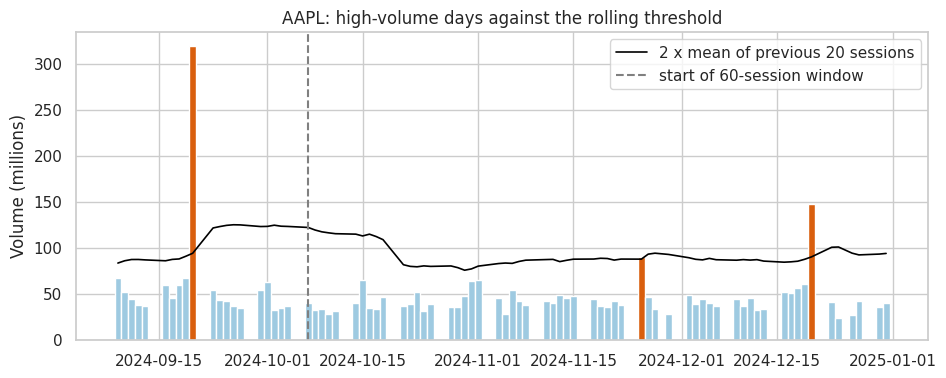

In [21]:
#  1.4.5  WORKED EXAMPLE FOR ONE SHARE
ex = "AAPL" if "AAPL" in common_shares else common_shares[0]       # Apple if it is in the final set, otherwise the first share
v = vol_k[ex].values; c = close_k[ex].values; d = vol_k.index; n = len(v)   # volume, close and dates as plain arrays
flags = np.zeros(n, dtype=bool)                                    # one True/False per day, all False to start
for i in range(BASELINE_DAYS, n):                                  # first day with a full 20-day baseline is session 21
    flags[i] = v[i] > SPIKE_FACTOR * v[i - BASELINE_DAYS:i].mean() # today against 2 x mean of the previous 20 days (today excluded)
event_days = np.where(flags)[0]                                    # positions of all events

R_manual = (OBS_DATE - d[event_days[-1]]).days                     # days from the latest event to the observation date
F_manual = int(flags[n - ACTIVITY_DAYS:].sum())                    # events inside the latest 60 sessions
M_manual = float((c[n - ACTIVITY_DAYS:] * v[n - ACTIVITY_DAYS:]).sum())   # sum of Close x Volume over the latest 60 sessions
assert R_manual == features_final.loc[ex, "R_days"] and F_manual == features_final.loc[ex, "F_days"]   # loop and pipeline agree on R and F
assert np.isclose(M_manual, features_final.loc[ex, "M_usd"])       # and on M
print("Example share:", ex, "| observation date:", OBS_DATE.date())
print("R =", R_manual, "| latest event:", d[event_days[-1]].date())
print("F =", F_manual, "high-volume days in the latest 60 sessions")
print("M = $" + format(M_manual, ",.0f"), "approximate traded value over 60 sessions")

in_win = [i for i in event_days if i >= n - ACTIVITY_DAYS]         # events inside the 60-session window
display(pd.DataFrame({"date": d[in_win], "volume": v[in_win],      # each event with its own threshold, so the rule is visible
    "mean_previous_20": [v[i - BASELINE_DAYS:i].mean() for i in in_win],
    "threshold_2x": [SPIKE_FACTOR * v[i - BASELINE_DAYS:i].mean() for i in in_win]}))
wrong = vol_k[ex] > SPIKE_FACTOR * vol_k[ex].rolling(BASELINE_DAYS).mean()   # the WRONG method: tested day included in its own baseline
print("Days that would change if the tested day were in its own baseline:", int((wrong.values != event[ex].values).sum()))

sl = slice(n - need, n)                                            # last 80 sessions (20 baseline + 60 window)
fig, ax = plt.subplots(figsize=(11, 4))                            # one wide chart
ax.bar(d[sl], v[sl] / 1e6, color=np.where(flags[sl], "#d95f0e", "#9ecae1"), width=1.0)   # orange bars = high-volume days
ax.plot(d[sl], threshold[ex].values[sl] / 1e6, color="black", lw=1.2, label="2 x mean of previous 20 sessions")   # rolling threshold
ax.axvline(d[n - ACTIVITY_DAYS], color="grey", ls="--", label="start of 60-session window")   # where F and M begin
ax.set_ylabel("Volume (millions)"); ax.set_title(ex + ": high-volume days against the rolling threshold"); ax.legend()   # labels
plt.savefig(os.path.join(FIG_DIR, "rfm_worked_example.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                         # display

1.5 Metric interpretation and supporting evidence

,rule,what it checks,fails when,shares failing
0,NO_DATA,No prices downloaded,no price at all,5
1,LATE_START,History starts after the first benchmark day,first price later than first benchmark day,10
2,GAPS,Missing prices or volume inside the history,"any missing Adj Close, Close or Volume",0
3,BAD_PRICE,Non-positive price,Adj Close or Close <= 0,0
4,BAD_VOLUME,Volume error,Volume <= 0,2
5,NO_EVENT,No high-volume event in the whole history (Rec...,no day above 2 x previous 20-session mean,0


Listed: 503 | excluded (unique shares): 17 | final common share set: 486


,ticker,company,sector,included,exclusion_reason
40,APP,AppLovin,Communication Services,False,LATE_START
116,COIN,Coinbase,Financials,False,LATE_START
123,CEG,Constellation Energy,Utilities,False,LATE_START
181,EXE,Expand Energy,Energy,False,LATE_START
192,FDXF,FedEx Freight,Industrials,False,NO_DATA
193,FERG,Ferguson Enterprises,Industrials,False,BAD_VOLUME
210,GEHC,GE HealthCare,Health Care,False,LATE_START
211,GEV,GE Vernova,Industrials,False,LATE_START
233,HONA,Honeywell Aerospace,Industrials,False,NO_DATA
379,Q,Qnity Electronics,Information Technology,False,NO_DATA


,included,total,excluded
sector,,,
Communication Services,20,22,2
Consumer Discretionary,47,47,0
Consumer Staples,32,33,1
Energy,20,21,1
Financials,74,76,2
Health Care,58,60,2
Industrials,78,83,5
Information Technology,74,76,2
Materials,23,24,1


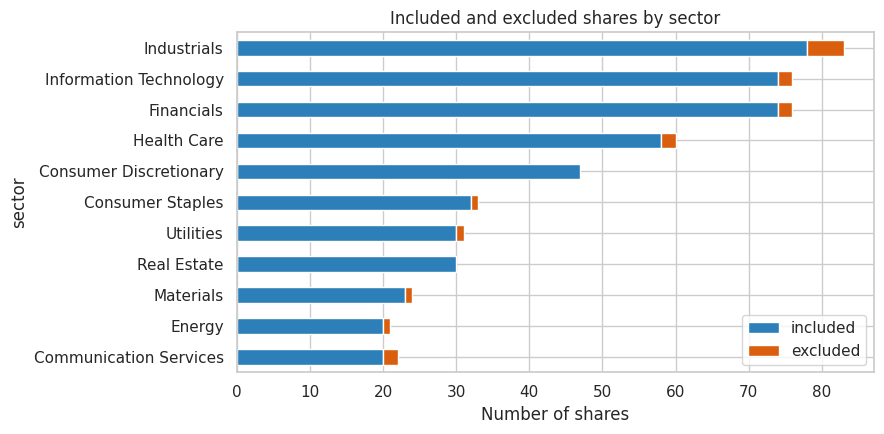

In [22]:
# 1.5.1  VALIDATION RULES AND INCLUSION / EXCLUSION LOG
rule_info = pd.DataFrame([                                         # one row per rule: name, meaning, what makes a share fail
    ("NO_DATA", "No prices downloaded", "no price at all"),
    ("LATE_START", "History starts after the first benchmark day", "first price later than first benchmark day"),
    ("GAPS", "Missing prices or volume inside the history", "any missing Adj Close, Close or Volume"),
    ("BAD_PRICE", "Non-positive price", "Adj Close or Close <= 0"),
    ("BAD_VOLUME", "Volume error", "Volume <= 0"),
    ("NO_EVENT", "No high-volume event in the whole history (Recency missing)", "no day above 2 x previous 20-session mean"),
], columns=["rule", "what it checks", "fails when"])               # column names
rule_info["shares failing"] = rule_info["rule"].map(drop_log_full["rule"].value_counts()).fillna(0).astype(int)   # count shares failing each rule (0 if none)
display(rule_info)                                                 # show the rules table
rule_info.to_csv(os.path.join(DATA_DIR, "validation_rules.csv"), index=False)   # save for GitHub

# --- Reconcile the counts: listed - excluded = final ---
n_listed = len(share_list)                                         # shares on the Wikipedia list
n_excluded = drop_log_full["ticker"].nunique()                     # unique shares excluded (a share can fail more than one rule)
n_final = len(features_final)                                      # shares in the common valid set
print("Listed:", n_listed, "| excluded (unique shares):", n_excluded, "| final common share set:", n_final)
assert n_listed - n_excluded == n_final                            # the numbers must add up exactly

# --- Full inclusion/exclusion log: one row per listed share ---
# Fetch correct 'security' and 'gics_sector' columns and rename them to 'company' and 'sector'
inclusion_log = sp500_list[["ticker", "security", "gics_sector"]].copy().rename(columns={"security": "company", "gics_sector": "sector"})
reasons = drop_log_full.groupby("ticker")["rule"].apply(lambda s: "; ".join(sorted(set(s))))   # all rules each share failed, joined as text
inclusion_log["included"] = ~inclusion_log["ticker"].isin(drop_log_full["ticker"])   # True if the share was never excluded
inclusion_log["exclusion_reason"] = inclusion_log["ticker"].map(reasons).fillna("")  # reason text, blank if included
inclusion_log.to_csv(os.path.join(DATA_DIR, "inclusion_exclusion_log.csv"), index=False)   # save for GitHub
assert int(inclusion_log["included"].sum()) == n_final             # log and final set must agree
display(inclusion_log[~inclusion_log["included"]].head(20))        # preview of excluded shares

# --- Does exclusion hit some sectors harder? ---
by_sector = inclusion_log.groupby("sector")["included"].agg(included="sum", total="count")   # included and total per sector
by_sector["excluded"] = by_sector["total"] - by_sector["included"]  # excluded per sector
display(by_sector)                                                 # show the table
by_sector[["included", "excluded"]].sort_values("included").plot(kind="barh", stacked=True, figsize=(9, 4.5), color=["#2c7fb8", "#d95f0e"])
plt.xlabel("Number of shares"); plt.title("Included and excluded shares by sector")   # labels
plt.tight_layout()                                                 # tidy layout
plt.savefig(os.path.join(FIG_DIR, "inclusion_by_sector.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                         # display

In [23]:
# 1.5.2  FEATURE SUMMARIES
summary = features_final[core].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T   # one row per feature
summary["q25"] = features_final[core].quantile(0.25)               # lower quartile
summary["q75"] = features_final[core].quantile(0.75)               # upper quartile
summary = summary[["count", "mean", "std", "min", "q25", "median", "q75", "max", "skew"]]   # tidy column order
display(summary)                                                   # skew well above 1 means a long right tail (expect this for M, and probably R)
summary.to_csv(os.path.join(DATA_DIR, "feature_summary.csv"))

,count,mean,std,min,q25,median,q75,max,skew
mean_weekly_return,486.0000,0.0029,0.0027,-0.0045,0.0012,0.0026,0.0042,0.0178,0.8675
weekly_beta,486.0000,0.9737,0.4073,0.0555,0.6666,0.9506,1.1795,3.7786,1.1036
R_days,486.0000,20.4074,21.3424,4.0000,11.0000,11.0000,14.7500,222.0000,3.6458
F_days,486.0000,2.9897,1.3308,0.0000,2.0000,3.0000,4.0000,8.0000,0.4247
M_usd,486.0000,"39,404,191,889.2078","129,138,833,232.9717","1,297,482,617.0479","10,195,173,392.2705","16,683,821,504.6230","32,276,893,043.8724","1,847,697,379,221.8428",11.6838


In [24]:
# 1.5.3  VALIDATION CHECKS TABLE
common_cols = list(features_final.index)                           # the common valid share set
checks_rows = [                                                    # (check name, True/False result, evidence text)
    ("Observation date is the last common trading day", OBS_DATE == trading_days[-1] == window[-1], str(OBS_DATE.date())),
    ("Activity window holds exactly 60 sessions", len(window) == ACTIVITY_DAYS, str(len(window)) + " sessions"),
    ("No event can occur in the first 20 sessions", not event.iloc[:BASELINE_DAYS].any().any(), "no baseline before session 21"),
    ("Every day in the window has a full 20-session baseline", bool(baseline.loc[window].notna().all().all()), "baseline defined on all 60 days"),
    ("Tested day is excluded from its own baseline", bool(np.isclose(baseline.iloc[BASELINE_DAYS, 0], vol_k.iloc[:BASELINE_DAYS, 0].mean())), "first baseline = mean of sessions 1 to 20"),
    ("Sufficient history for 20 + 60 sessions", len(vol_k) >= need, str(len(vol_k)) + " sessions available, " + str(need) + " needed"),
    ("No gaps in the latest 80 sessions for included shares", int(close_k[common_cols].iloc[-need:].isna().sum().sum() + vol_k[common_cols].iloc[-need:].isna().sum().sum()) == 0, "0 missing Close or Volume cells"),
    ("No-event shares have missing R, never 0", bool(((features_final["R_days"] == 0) == (features_final["last_high_volume_date"] == OBS_DATE)).all()), str(len(extra_excluded)) + " shares excluded for no event"),
    ("All included shares have all five features", bool(features_final[core].notna().all().all()), str(n_final) + " shares"),
    ("Common set: unique tickers, same set for every analysis", features_final.index.is_unique and set(common_cols) <= set(ret_week.columns), "one list reused for all four clustering solutions"),
    ("Same number of weekly observations for every share", bool((features_final["n_weeks"] == N_WEEKS).all()), str(N_WEEKS) + " aligned weeks"),
    ("F within 0 to 60 and M positive", bool(features_final["F_days"].between(0, ACTIVITY_DAYS).all() and (features_final["M_usd"] > 0).all()), "range checks"),
]
checks_table = pd.DataFrame(checks_rows, columns=["check", "passed", "evidence"])   # build the table
checks_table["status"] = np.where(checks_table["passed"], "PASS", "FAIL")   # turn True/False into PASS/FAIL
display(checks_table[["check", "status", "evidence"]])             # show it
checks_table[["check", "status", "evidence"]].to_csv(os.path.join(DATA_DIR, "validation_checks.csv"), index=False)   # save for GitHub
assert checks_table["passed"].all(), "At least one validation check failed"   # stop with an error if any check fails
print("All", len(checks_table), "checks passed")

,check,status,evidence
0,Observation date is the last common trading day,PASS,2024-12-31
1,Activity window holds exactly 60 sessions,PASS,60 sessions
2,No event can occur in the first 20 sessions,PASS,no baseline before session 21
3,Every day in the window has a full 20-session ...,PASS,baseline defined on all 60 days
4,Tested day is excluded from its own baseline,PASS,first baseline = mean of sessions 1 to 20
5,Sufficient history for 20 + 60 sessions,PASS,"1005 sessions available, 80 needed"
6,No gaps in the latest 80 sessions for included...,PASS,0 missing Close or Volume cells
7,"No-event shares have missing R, never 0",PASS,0 shares excluded for no event
8,All included shares have all five features,PASS,486 shares
9,"Common set: unique tickers, same set for every...",PASS,one list reused for all four clustering solutions


All 12 checks passed


# Task 2 Stock Segmentation and Sensitivity Analysis

2.1a: Two separate matrices on the common share set

In [25]:
#  2.1a  TWO SEPARATE FEATURE MATRICES (BEFORE ANY TRANSFORMATION)
from sklearn.preprocessing import StandardScaler                   # standardises each column to mean 0 and standard deviation 1

assert features_final.index.is_unique                              # one row per share, no duplicate tickers
X_rr_raw = features_final[["mean_weekly_return", "weekly_beta"]].copy()   # matrix 1: risk and return features
X_act_raw = features_final[["R_days", "F_days", "M_usd"]].copy()   # matrix 2: trading-activity features (R, F, M)
assert X_rr_raw.index.equals(X_act_raw.index)                      # both matrices hold the same shares in the same order
print("Common share set:", len(X_rr_raw), "shares")
print("Risk-return matrix:", X_rr_raw.shape, "| Trading-activity matrix:", X_act_raw.shape)

Common share set: 486 shares
Risk-return matrix: (486, 2) | Trading-activity matrix: (486, 3)


2.1b: Inspect skew and outliers

,skew,min,max,outliers (1.5 x IQR rule),outliers (|z| > 3),log1p valid (never negative)
mean_weekly_return,0.8675,-0.0045,0.0178,15,6,False
weekly_beta,1.1036,0.0555,3.7786,10,2,True
R_days,3.6458,4.0000,222.0000,115,11,True
F_days,0.4247,0.0000,8.0000,2,5,True
M_usd,11.6838,"1,297,482,617.0479","1,847,697,379,221.8428",45,5,True


,mean_weekly_return,weekly_beta,R_days,F_days,M_usd
0,SMCI,CVNA,NVDA,CI,TSLA
1,NVDA,XYZ,WEC,HSY,NVDA
2,VRT,COHR,COR,FOXA,AAPL
3,VST,NVDA,CB,UNH,MSFT
4,FIX,TWLO,DUK,XEL,AMZN


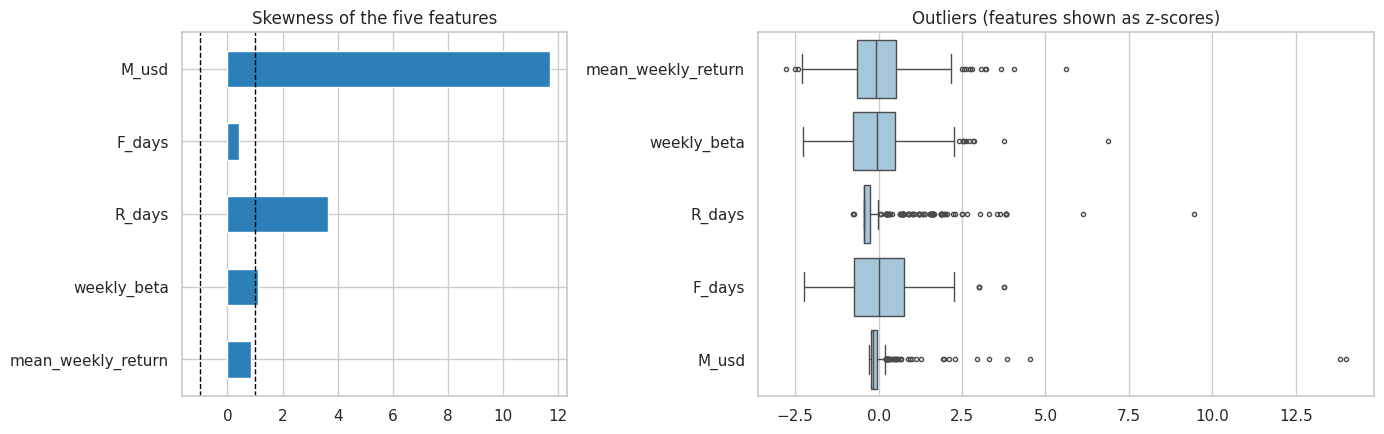

In [26]:
# 2.1b  SKEW AND OUTLIER DIAGNOSTICS
five = features_final[core]                                        # the five features in original units
z_raw = (five - five.mean()) / five.std()                          # z-scores, used to find and compare extremes
q1, q3 = five.quantile(0.25), five.quantile(0.75)                  # lower and upper quartiles
iqr = q3 - q1                                                      # interquartile range
diag = pd.DataFrame({                                              # one row per feature
    "skew": five.skew(),                                           # asymmetry: above 1 = long right tail, below -1 = long left tail
    "min": five.min(),                                             # smallest value
    "max": five.max(),                                             # largest value
    "outliers (1.5 x IQR rule)": ((five < q1 - 1.5 * iqr) | (five > q3 + 1.5 * iqr)).sum(),   # shares beyond the box-plot whiskers
    "outliers (|z| > 3)": (z_raw.abs() > 3).sum(),                 # shares more than 3 standard deviations from the mean
    "log1p valid (never negative)": five.min() >= 0,               # log1p only makes sense for features that are never negative
})
display(diag)                                                      # show the diagnostics table
extreme = pd.DataFrame({col: z_raw[col].abs().nlargest(5).index.tolist() for col in core})   # the 5 most extreme shares for each feature
display(extreme)                                                   # check whether they are real, well-known shares

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})   # two panels side by side
diag["skew"].plot(kind="barh", ax=axes[0], color="#2c7fb8")        # bar chart of skewness
axes[0].axvline(1, color="black", ls="--", lw=1)                   # +1 reference line
axes[0].axvline(-1, color="black", ls="--", lw=1)                  # -1 reference line
axes[0].set_title("Skewness of the five features")                 # left panel title
sns.boxplot(data=z_raw, orient="h", ax=axes[1], color="#9ecae1", fliersize=3)   # box plots on a common z-score scale
axes[1].set_title("Outliers (features shown as z-scores)")         # right panel title
plt.tight_layout()                                                 # stop the panels overlapping
plt.savefig(os.path.join(FIG_DIR, "skew_outliers.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                         # display

2.1c: Would a log transform help the other skewed variables?

In [27]:
# 2.1c  EVIDENCE FOR THE TREATMENT OF R, F AND M
trial = pd.DataFrame({                                             # skew before and after log1p for the three non-negative features
    "skew before": [features_final["R_days"].skew(), features_final["F_days"].skew(), features_final["M_usd"].skew()],
    "skew after log1p": [np.log1p(features_final["R_days"]).skew(), np.log1p(features_final["F_days"]).skew(), np.log1p(features_final["M_usd"]).skew()],
}, index=["R", "F", "M"])                                          # one row per feature
display(trial)                                                     # compare: a big drop means the transform really helps

,skew before,skew after log1p
R,3.6458,1.5832
F,0.4247,-0.9284
M,11.6838,1.0791


2.1d: Apply log1p to M, standardise each matrix, and prove it worked

risk-return matrix: mean 0 and standard deviation 1 on every column -> (486, 2)
trading-activity matrix: mean 0 and standard deviation 1 on every column -> (486, 3)


,"raw R, F, M","R, F, log1p(M)",standardised
R_days,0.0000,99.4000,33.3000
F_days,0.0000,0.4000,33.3000
M_usd,100.0000,0.2000,33.3000


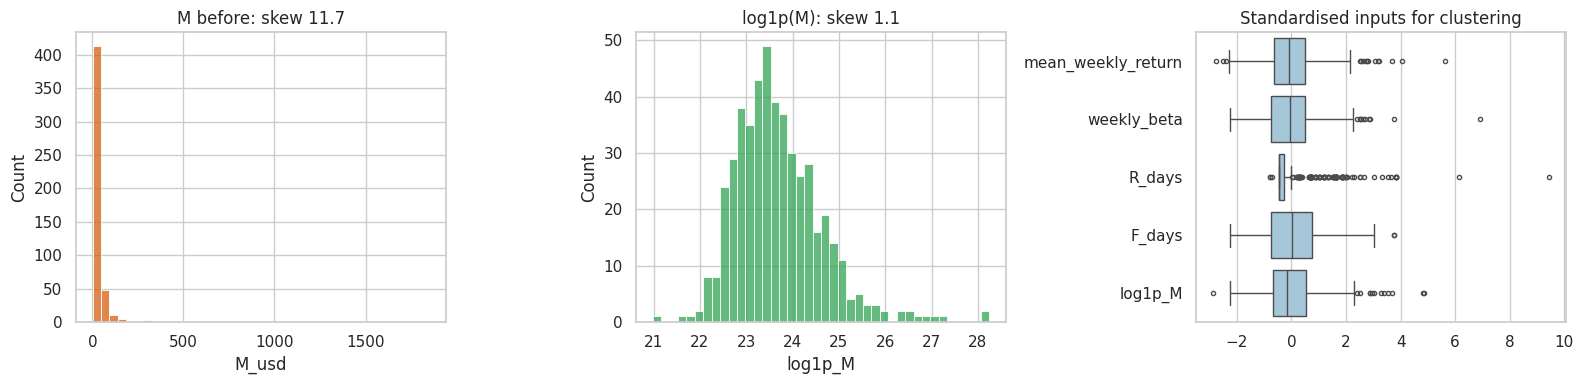

In [28]:
# 2.1d  LOG1P ON M, THEN STANDARDISE EACH MATRIX
X_act = X_act_raw.copy()                                           # start from the original activity matrix
X_act["log1p_M"] = np.log1p(X_act["M_usd"])                        # log(1 + M): compresses the huge range of traded value
X_act = X_act[["R_days", "F_days", "log1p_M"]]                     # keep R, F and log1p(M) only (raw M is dropped from the matrix)
X_rr = X_rr_raw.copy()                                             # the risk-return matrix needs no log transform

scaler_rr = StandardScaler()                                       # separate scaler for the risk-return matrix
scaler_act = StandardScaler()                                      # separate scaler for the trading-activity matrix
Z_rr = pd.DataFrame(scaler_rr.fit_transform(X_rr), index=X_rr.index, columns=X_rr.columns)        # standardised risk-return matrix
Z_act = pd.DataFrame(scaler_act.fit_transform(X_act), index=X_act.index, columns=X_act.columns)   # standardised trading-activity matrix

# --- Checks ---
for name, Z in [("risk-return", Z_rr), ("trading-activity", Z_act)]:   # test both matrices
    assert np.isfinite(Z.values).all()                             # no missing or infinite values
    assert np.allclose(Z.mean(), 0) and np.allclose(Z.std(ddof=0), 1)   # every column has mean 0 and standard deviation 1
    print(name, "matrix: mean 0 and standard deviation 1 on every column ->", Z.shape)
assert Z_rr.index.equals(Z_act.index)                              # same shares, same order, in both matrices

# --- How does each step change each feature's influence on Euclidean distance? ---
share_of_distance = pd.DataFrame({                                 # each feature's share of the total variance (variance drives distances)
    "raw R, F, M": X_act_raw.var() / X_act_raw.var().sum(),        # before any treatment
    "R, F, log1p(M)": X_act.var().set_axis(X_act_raw.columns) / X_act.var().sum(),   # after log1p(M) only
    "standardised": Z_act.var(ddof=0).set_axis(X_act_raw.columns) / Z_act.var(ddof=0).sum(),   # after standardising: equal shares
})
display((share_of_distance * 100).round(1))                        # percentages: shows why standardising is needed

fig, axes = plt.subplots(1, 3, figsize=(16, 4))                    # three panels side by side
sns.histplot(X_act_raw["M_usd"] / 1e9, bins=40, ax=axes[0], color="#d95f0e")   # M before the transform, in USD billions
axes[0].set_title("M before: skew " + format(X_act_raw["M_usd"].skew(), ".1f"))   # title with the skew value
sns.histplot(X_act["log1p_M"], bins=40, ax=axes[1], color="#31a354")   # M after log1p
axes[1].set_title("log1p(M): skew " + format(X_act["log1p_M"].skew(), ".1f"))     # title with the new skew
sns.boxplot(data=pd.concat([Z_rr, Z_act], axis=1), orient="h", ax=axes[2], color="#9ecae1", fliersize=3)   # all standardised columns together
axes[2].set_title("Standardised inputs for clustering")            # right panel title
plt.tight_layout()                                                 # stop the panels overlapping
plt.savefig(os.path.join(FIG_DIR, "feature_preparation.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                         # display

# --- Save the matrices (the brief asks for the feature tables) ---
Z_rr.to_csv(os.path.join(DATA_DIR, "matrix_risk_return_scaled.csv"))             # standardised risk-return matrix
Z_act.to_csv(os.path.join(DATA_DIR, "matrix_trading_activity_scaled.csv"))       # standardised trading-activity matrix
X_rr.to_csv(os.path.join(DATA_DIR, "matrix_risk_return_original.csv"))           # original-unit risk-return matrix
X_act.join(X_act_raw["M_usd"]).to_csv(os.path.join(DATA_DIR, "matrix_trading_activity_original.csv"))   # original units plus raw M

2.2a: Ward fits for k = 2 to 8 and the evidence table

risk_return


,silhouette,calinski_harabasz,smallest_cluster,smallest_pct,sizes
k,,,,,
2,0.3395,182.5364,92,18.9300,"394, 92"
3,0.2738,202.2069,92,18.9300,"230, 164, 92"
4,0.2821,204.1526,48,9.8765,"182, 164, 92, 48"
5,0.3041,215.7974,48,9.8765,"182, 98, 92, 66, 48"
6,0.3204,236.6382,5,1.0288,"182, 98, 87, 66, 48, 5"
7,0.3240,235.9518,5,1.0288,"160, 98, 87, 66, 48, 22, 5"
8,0.3208,245.9600,5,1.0288,"160, 98, 66, 56, 48, 31, 22, 5"


trading_activity


,silhouette,calinski_harabasz,smallest_cluster,smallest_pct,sizes
k,,,,,
2,0.3680,156.7031,82,16.8724,"404, 82"
3,0.3040,179.0577,82,16.8724,"250, 154, 82"
4,0.2888,168.4627,43,8.8477,"207, 154, 82, 43"
5,0.3050,173.4557,10,2.0576,"207, 154, 72, 43, 10"
6,0.3144,181.3138,10,2.0576,"207, 136, 72, 43, 18, 10"
7,0.2917,184.1288,10,2.0576,"141, 136, 72, 66, 43, 18, 10"
8,0.3021,190.0115,10,2.0576,"141, 79, 72, 66, 57, 43, 18, 10"


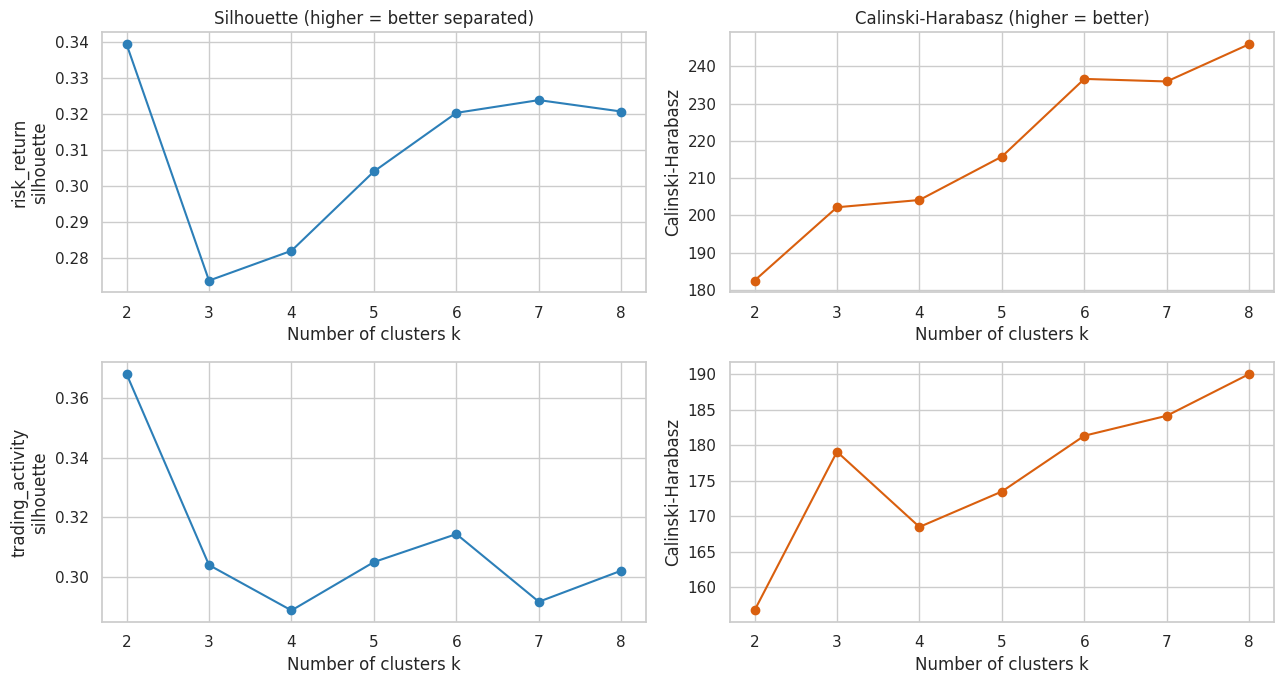

In [29]:
# 2.2a  WARD CLUSTERING FOR k = 2 TO 8
from sklearn.cluster import AgglomerativeClustering                # agglomerative (bottom-up) clustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, adjusted_rand_score   # cluster quality scores
from sklearn.preprocessing import StandardScaler

# Ensure standardized matrices are available in the local state
scaler_rr = StandardScaler()
scaler_act = StandardScaler()
X_rr = features_final[["mean_weekly_return", "weekly_beta"]].copy()
X_act = features_final[["R_days", "F_days", "M_usd"]].copy()
X_act["log1p_M"] = np.log1p(X_act["M_usd"])
X_act = X_act[["R_days", "F_days", "log1p_M"]]

Z_rr = pd.DataFrame(scaler_rr.fit_transform(X_rr), index=X_rr.index, columns=X_rr.columns)
Z_act = pd.DataFrame(scaler_act.fit_transform(X_act), index=X_act.index, columns=X_act.columns)

matrices = {"risk_return": Z_rr, "trading_activity": Z_act}        # the two standardised matrices from 2.1
K_RANGE = range(2, 9)                                              # feasible cluster counts: 2 to 8
ward_labels = {}                                                   # will hold the cluster labels for every (matrix, k)
rows = []                                                          # will hold one row of scores per (matrix, k)
for name, Z in matrices.items():                                   # loop over the two matrices
    for k in K_RANGE:                                              # loop over k = 2 ... 8
        labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z.values)   # Ward linkage (Euclidean distance is built in)
        ward_labels[(name, k)] = labels                            # keep the labels for later use
        sizes = np.sort(np.bincount(labels))[::-1]                 # cluster sizes, largest first
        rows.append({"matrix": name, "k": k,
                     "silhouette": silhouette_score(Z.values, labels),                  # -1 to 1, higher = better separated
                     "calinski_harabasz": calinski_harabasz_score(Z.values, labels),    # higher = better
                     "smallest_cluster": int(sizes.min()),                              # size of the smallest cluster
                     "smallest_pct": 100 * sizes.min() / len(labels),                   # that size as a % of all shares
                     "sizes": ", ".join(map(str, sizes))})                              # all sizes as text
ward_diag = pd.DataFrame(rows)                                     # combine into one table
for name in matrices:
    print(name)
    display(ward_diag[ward_diag["matrix"] == name].drop(columns="matrix").set_index("k"))

fig, axes = plt.subplots(2, 2, figsize=(13, 7))                    # removed sharex=True to show x-ticks on both rows
for row, name in enumerate(matrices):                              # one row per matrix
    d = ward_diag[ward_diag["matrix"] == name]                     # that matrix's scores
    axes[row, 0].plot(d["k"], d["silhouette"], marker="o", color="#2c7fb8")           # silhouette against k
    axes[row, 0].set_ylabel(name + "\nsilhouette")                 # label with the matrix name
    axes[row, 0].set_xlabel("Number of clusters k")                # x-label for this row
    axes[row, 1].plot(d["k"], d["calinski_harabasz"], marker="o", color="#d95f0e")    # Calinski-Harabasz against k
    axes[row, 1].set_ylabel("Calinski-Harabasz")                   # y label
    axes[row, 1].set_xlabel("Number of clusters k")                # x-label for this row
axes[0, 0].set_title("Silhouette (higher = better separated)")     # column titles
axes[0, 1].set_title("Calinski-Harabasz (higher = better)")
plt.tight_layout()                                                 # stop the panels overlapping
plt.savefig(os.path.join(FIG_DIR, "ward_k_diagnostics.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                         # display
ward_diag.to_csv(os.path.join(DATA_DIR, "ward_k_diagnostics.csv"), index=False)   # save for GitHub

2.2b: One dendrogram per matrix

risk_return | cophenetic correlation: 0.479 | sklearn vs scipy agreement (ARI, 1 = identical): 1.0
trading_activity | cophenetic correlation: 0.508 | sklearn vs scipy agreement (ARI, 1 = identical): 1.0


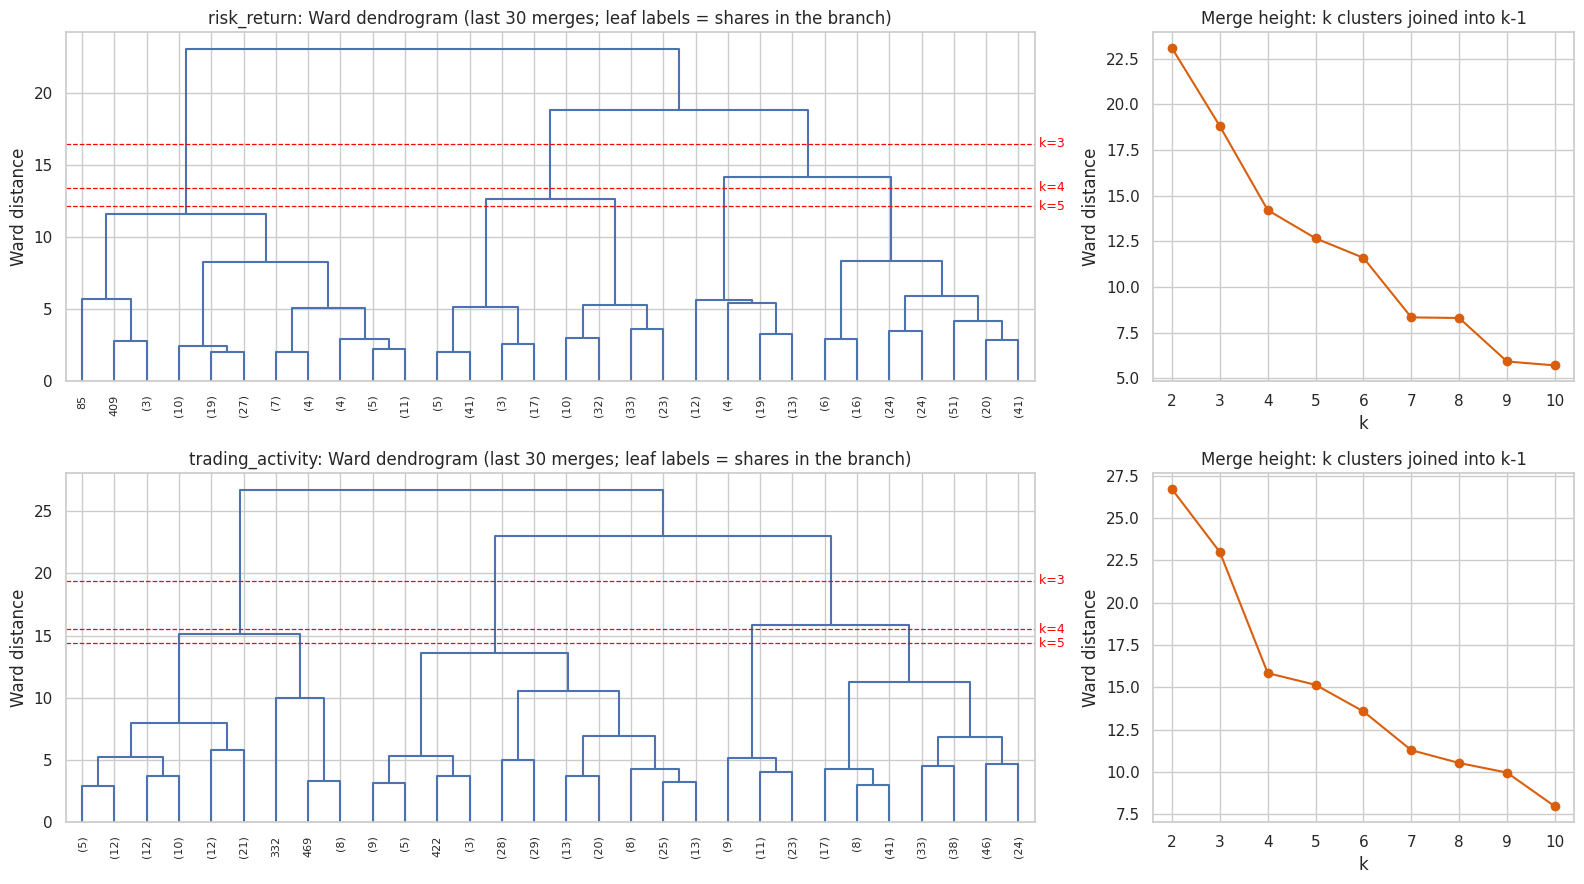

In [30]:
#2.2b  DENDROGRAMS (ONE PER MATRIX)
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet   # tools for the merge tree
from scipy.spatial.distance import pdist                           # pairwise distances between shares
from sklearn.preprocessing import StandardScaler

# Recreate the standardized matrices to ensure self-contained execution
scaler_rr = StandardScaler()
scaler_act = StandardScaler()
X_rr = features_final[["mean_weekly_return", "weekly_beta"]].copy()
X_act = features_final[["R_days", "F_days", "M_usd"]].copy()
X_act["log1p_M"] = np.log1p(X_act["M_usd"])
X_act = X_act[["R_days", "F_days", "log1p_M"]]

Z_rr = pd.DataFrame(scaler_rr.fit_transform(X_rr), index=X_rr.index, columns=X_rr.columns)
Z_act = pd.DataFrame(scaler_act.fit_transform(X_act), index=X_act.index, columns=X_act.columns)
matrices = {"risk_return": Z_rr, "trading_activity": Z_act}

linkages = {}                                                      # will hold each matrix's merge tree
for name, Z in matrices.items():                                   # loop over the two matrices
    Zl = linkage(Z.values, method="ward", metric="euclidean")      # Ward linkage on Euclidean distances (same method as 2.2a)
    linkages[name] = Zl                                            # keep the tree
    coph, _ = cophenet(Zl, pdist(Z.values))                        # cophenetic correlation: how faithfully the tree keeps the original distances
    agree = min(adjusted_rand_score(fcluster(Zl, k, "maxclust"), ward_labels[(name, k)]) for k in (3, 4, 5))   # do both libraries give the same clusters?
    print(name, "| cophenetic correlation:", round(float(coph), 3), "| sklearn vs scipy agreement (ARI, 1 = identical):", round(float(agree), 4))
    assert agree > 0.99                                            # stop if the two methods disagree

fig, axes = plt.subplots(2, 2, figsize=(16, 9), gridspec_kw={"width_ratios": [2.3, 1]})   # rows = matrices
for row, (name, Zl) in enumerate(linkages.items()):                # one row per matrix
    ax = axes[row, 0]                                              # left panel = dendrogram
    dendrogram(Zl, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=8,
               color_threshold=0, above_threshold_color="#4C72B0", ax=ax)   # show only the last 30 merges so 486 leaves stay readable
    for k in (3, 4, 5):                                            # mark where k = 3, 4, 5 would cut the tree
        h = (Zl[-(k - 1), 2] + Zl[-k, 2]) / 2                      # a height between the merges that make k and k+1 clusters
        ax.axhline(h, ls="--", lw=0.9, color="red")                # red dashed cut line (as requested)
        ax.text(ax.get_xlim()[1], h, " k=" + str(k), va="center", fontsize=9, color="red")   # label the line in red
    ax.set_title(name + ": Ward dendrogram (last 30 merges; leaf labels = shares in the branch)")
    ax.set_ylabel("Ward distance")
    ks = np.arange(2, 11)                                          # k = 2 ... 10
    axes[row, 1].plot(ks, [Zl[-(k - 1), 2] for k in ks], marker="o", color="#d95f0e")   # height of the merge that joins k clusters into k-1
    axes[row, 1].set_title("Merge height: k clusters joined into k-1")
    axes[row, 1].set_xlabel("k"); axes[row, 1].set_ylabel("Ward distance")
plt.tight_layout()                                                 # stop the panels overlapping
plt.savefig(os.path.join(FIG_DIR, "ward_dendrograms.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                         # display

In [31]:
# 2.2c  CANDIDATE PROFILES IN ORIGINAL UNITS
orig = {"risk_return": features_final[["mean_weekly_return", "weekly_beta"]],            # original-unit features for each matrix
        "trading_activity": features_final[["R_days", "F_days", "M_usd"]]}

def profile(name, k):                                              # build the profile table for one matrix and one k
    lab = pd.Series(ward_labels[(name, k)], index=matrices[name].index, name="cluster")   # cluster label for each share
    prof = orig[name].groupby(lab).agg(["mean", "median"])         # mean and median of each feature per cluster
    prof.columns = [a + "_" + b for a, b in prof.columns]          # flatten the column names
    if "M_usd_mean" in prof.columns:                               # show traded value in USD billions so it is readable
        prof["M_usd_mean"] = prof["M_usd_mean"] / 1e9
        prof["M_usd_median"] = prof["M_usd_median"] / 1e9
        prof = prof.rename(columns={"M_usd_mean": "M_mean_USDbn", "M_usd_median": "M_median_USDbn"})
    prof.insert(0, "n_shares", lab.value_counts().sort_index())    # number of shares in each cluster
    return prof

CANDIDATE_K = [3, 4, 5]                                            # candidate cluster counts to inspect
for name in matrices:                                              # loop over the two matrices
    for k in CANDIDATE_K:                                          # and the candidate k values
        print(name, "| Ward k =", k)
        display(profile(name, k).round(4))                         # show the profile table

risk_return | Ward k = 3


,n_shares,mean_weekly_return_mean,mean_weekly_return_median,weekly_beta_mean,weekly_beta_median
cluster,,,,,
0,230,0.0015,0.0017,1.1096,1.0384
1,92,0.0063,0.0055,1.2981,1.2177
2,164,0.0029,0.0033,0.6012,0.5777


risk_return | Ward k = 4


,n_shares,mean_weekly_return_mean,mean_weekly_return_median,weekly_beta_mean,weekly_beta_median
cluster,,,,,
0,164,0.0029,0.0033,0.6012,0.5777
1,92,0.0063,0.0055,1.2981,1.2177
2,182,0.0013,0.0017,0.9728,0.9644
3,48,0.0020,0.0025,1.6280,1.5138


risk_return | Ward k = 5


,n_shares,mean_weekly_return_mean,mean_weekly_return_median,weekly_beta_mean,weekly_beta_median
cluster,,,,,
0,92,0.0063,0.0055,1.2981,1.2177
1,48,0.0020,0.0025,1.6280,1.5138
2,182,0.0013,0.0017,0.9728,0.9644
3,98,0.0042,0.0039,0.7104,0.6663
4,66,0.0009,0.0011,0.4390,0.4485


... (2 outputs left out)

trading_activity | Ward k = 4


,n_shares,R_days_mean,R_days_median,F_days_mean,F_days_median,M_mean_USDbn,M_median_USDbn
cluster,,,,,,,
0,82,58.3049,54.5000,2.0976,2.0000,47.1590,17.8490
1,207,11.1401,11.0000,2.9420,3.0000,11.0998,10.7853
2,154,13.6818,11.0000,2.8636,3.0000,80.1452,39.6955
3,43,16.8372,11.0000,5.3721,5.0000,14.9622,14.4300


trading_activity | Ward k = 5


,n_shares,R_days_mean,R_days_median,F_days_mean,F_days_median,M_mean_USDbn,M_median_USDbn
cluster,,,,,,,
0,154,13.6818,11.0000,2.8636,3.0000,80.1452,39.6955
1,207,11.1401,11.0000,2.9420,3.0000,11.0998,10.7853
2,10,116.8000,102.0000,0.0000,0.0000,199.7420,23.7859
3,43,16.8372,11.0000,5.3721,5.0000,14.9622,14.4300
4,72,50.1806,53.0000,2.3889,2.0000,25.9669,17.6823


linkage             average  complete   ward
matrix           k                          
risk_return      2   0.6840    0.4130 0.3390
                 3   0.6450    0.3960 0.2740
                 4   0.4990    0.3530 0.2820
                 5   0.4080    0.3410 0.3040
                 6   0.4040    0.2620 0.3200
                 7   0.3670    0.2680 0.3240
                 8   0.2290    0.2580 0.3210
trading_activity 2   0.8050    0.6310 0.3680
                 3   0.5670    0.5840 0.3040
                 4   0.4410    0.3620 0.2890
                 5   0.4200    0.3100 0.3050
                 6   0.3290    0.2430 0.3140
                 7   0.3190    0.1960 0.2920
                 8   0.2160    0.1820 0.3020

matrix,risk_return,trading_activity
k,,
2,0.3940,0.8230
3,0.4130,0.5270
4,0.4650,0.5260
5,0.4510,0.4590
6,0.4790,0.5050
7,0.5230,0.5310
8,0.5350,0.5760


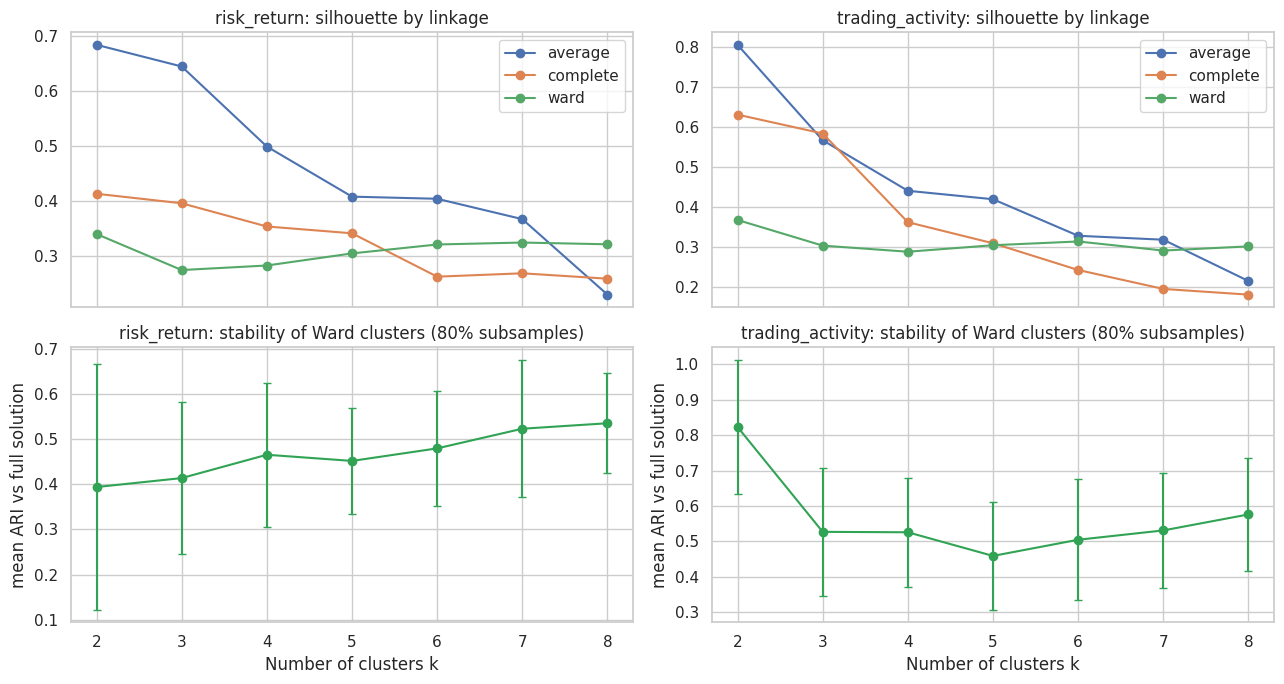

In [32]:
# 2.2d  EXPERIMENTS: LINKAGE COMPARISON AND STABILITY
exp_rows = []                                                      # rows for the linkage comparison
for name, Z in matrices.items():                                   # both matrices
    for method in ["ward", "average", "complete"]:                 # three linkage methods
        for k in K_RANGE:                                          # k = 2 ... 8
            lab = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(Z.values)   # fit with that linkage
            exp_rows.append({"matrix": name, "linkage": method, "k": k,
                             "silhouette": silhouette_score(Z.values, lab),         # separation score
                             "smallest_cluster": int(np.bincount(lab).min())})      # smallest cluster size
linkage_compare = pd.DataFrame(exp_rows)                           # combine into one table
display(linkage_compare.pivot_table(index=["matrix", "k"], columns="linkage", values="silhouette").round(3))   # silhouette by linkage

rng = np.random.default_rng(42)                                    # fixed seed so the experiment is reproducible
N_REPEATS = 30                                                     # number of random subsamples per k
stab_rows = []                                                     # rows for the stability results
for name, Z in matrices.items():                                   # both matrices
    X = Z.values; n = len(X)                                       # data as an array, and the number of shares
    for k in K_RANGE:                                              # k = 2 ... 8
        full = ward_labels[(name, k)]                              # the full-data Ward solution
        aris = []                                                  # ARI scores for this k
        for r in range(N_REPEATS):                                 # repeat on random subsamples
            idx = rng.choice(n, int(0.8 * n), replace=False)       # pick a random 80% of the shares
            sub = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X[idx])   # refit Ward on the subsample
            aris.append(adjusted_rand_score(full[idx], sub))       # compare with the full solution on the same shares
        stab_rows.append({"matrix": name, "k": k, "mean_ARI": np.mean(aris), "std_ARI": np.std(aris)})
stability = pd.DataFrame(stab_rows)                                # combine into one table
display(stability.pivot(index="k", columns="matrix", values="mean_ARI").round(3))   # mean ARI by k

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)       # top row = linkage comparison, bottom row = stability
for col, name in enumerate(matrices):                              # one column per matrix
    d = linkage_compare[linkage_compare["matrix"] == name]         # that matrix's linkage results
    for method, g in d.groupby("linkage"):                         # one line per linkage method
        axes[0, col].plot(g["k"], g["silhouette"], marker="o", label=method)
    axes[0, col].set_title(name + ": silhouette by linkage"); axes[0, col].legend()
    s = stability[stability["matrix"] == name]                     # that matrix's stability results
    axes[1, col].errorbar(s["k"], s["mean_ARI"], yerr=s["std_ARI"], marker="o", color="#31a354", capsize=3)   # mean ARI with spread
    axes[1, col].set_title(name + ": stability of Ward clusters (80% subsamples)")
    axes[1, col].set_xlabel("Number of clusters k"); axes[1, col].set_ylabel("mean ARI vs full solution")
plt.tight_layout()                                                 # stop the panels overlapping
plt.savefig(os.path.join(FIG_DIR, "ward_experiments.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                         # display
linkage_compare.to_csv(os.path.join(DATA_DIR, "ward_linkage_comparison.csv"), index=False)   # save for GitHub
stability.to_csv(os.path.join(DATA_DIR, "ward_stability.csv"), index=False)                  # save for GitHub

In [33]:
#  2.2e-1  SETTINGS, SELECTION RULE AND TABLE HELPERS
MIN_K = 3                                                          # a 2-cluster split usually just separates a few outliers, so require at least 3
MIN_CLUSTER_PCT = 5.0                                              # the smallest cluster must hold at least 5% of the shares
K_OVERRIDE_WARD = {}                                               # leave empty; fill (e.g. {"trading_activity": 4}) only with a written reason from the profiles
n_shares = len(features_final)                                     # number of shares in the common set

def choose_k(diag, name, override):                                # apply the written selection rule to one matrix
    d = diag[diag["matrix"] == name]                               # that matrix's diagnostics
    feasible = d[(d["k"] >= MIN_K) & (d["smallest_pct"] >= MIN_CLUSTER_PCT)]   # k values that pass the minimum-k and size rules
    rule = "highest silhouette among k >= " + str(MIN_K) + " with smallest cluster >= " + str(MIN_CLUSTER_PCT) + "%"
    if feasible.empty:                                             # if nothing passes, relax the size rule and say so
        feasible = d[d["k"] >= MIN_K]
        rule = "no k met the size rule, so it was relaxed: highest silhouette among k >= " + str(MIN_K)
    best = int(feasible.sort_values("silhouette", ascending=False).iloc[0]["k"])   # best silhouette among the feasible k
    if name in override:                                           # a manual choice replaces the rule
        return override[name], "manual override"
    return best, rule

def relabel_by_size(labels):                                       # cluster numbers are arbitrary, so number them by size (0 = largest)
    order = pd.Series(labels).value_counts().index                 # old cluster ids from largest to smallest
    mapping = {old: new for new, old in enumerate(order)}          # old id -> new id
    return np.array([mapping[l] for l in labels])                  # apply the mapping to every share

def show_diag(diag, name, k_sel=None):                             # one clean, formatted table per matrix (selected k highlighted)
    d = diag[diag["matrix"] == name].set_index("k").copy()         # that matrix's rows, indexed by k
    d["largest_pct"] = d["sizes"].str.split(", ").str[0].astype(int) / n_shares * 100   # biggest cluster as % of shares
    d["sizes"] = d["sizes"].str.replace(", ", " / ")               # cluster sizes written as 454 / 36
    d["feasible"] = (d.index >= MIN_K) & (d["smallest_pct"] >= MIN_CLUSTER_PCT)   # passes the written rule?
    order = ["inertia", "silhouette", "calinski_harabasz", "mean_ARI", "smallest_pct", "largest_pct", "sizes", "feasible"]
    cols = [c for c in order if c in d.columns]                    # keep only the columns this table has
    fmt = {"inertia": "{:,.1f}", "silhouette": "{:.3f}", "calinski_harabasz": "{:,.1f}",
           "mean_ARI": "{:.3f}", "smallest_pct": "{:.1f}", "largest_pct": "{:.1f}"}   # number formats
    sty = d[cols].style.format({c: f for c, f in fmt.items() if c in cols})   # apply the formats
    if k_sel is not None:                                          # highlight the chosen k
        sty = sty.apply(lambda r: ["background-color: #ffe699; color: black" if r.name == k_sel else "" for _ in r], axis=1)
    display(sty)

In [34]:
#2.2e-2  CHOOSE k FOR WARD AND SHOW THE EVIDENCE
K_WARD, K_WARD_RULE = {}, {}                                       # chosen k and the rule used, per matrix
evidence = ward_diag.merge(stability[["matrix", "k", "mean_ARI"]], on=["matrix", "k"])   # add the stability results from 2.2d
for name in matrices:                                              # both matrices
    K_WARD[name], K_WARD_RULE[name] = choose_k(ward_diag, name, K_OVERRIDE_WARD)   # apply the written rule
    print("Ward,", name, "-> k =", K_WARD[name], "|", K_WARD_RULE[name])
    show_diag(evidence, name, K_WARD[name])                        # formatted evidence table, chosen k highlighted
    e = evidence[(evidence["matrix"] == name) & (evidence["k"] >= MIN_K) & (evidence["smallest_pct"] >= MIN_CLUSTER_PCT)]   # feasible rows
    if len(e):                                                     # cross-check: do the other indices agree?
        print("  Feasible k: best by Calinski-Harabasz =", int(e.loc[e["calinski_harabasz"].idxmax(), "k"]),
              "| best by subsample stability =", int(e.loc[e["mean_ARI"].idxmax(), "k"]))
evidence.to_csv(os.path.join(DATA_DIR, "ward_k_selection_evidence.csv"), index=False)   # save for GitHub

Ward, risk_return -> k = 5 | highest silhouette among k >= 3 with smallest cluster >= 5.0%


,silhouette,calinski_harabasz,mean_ARI,smallest_pct,largest_pct,sizes,feasible
k,,,,,,,
2,0.339,182.5,0.394,18.9,81.1,394 / 92,False
3,0.274,202.2,0.413,18.9,47.3,230 / 164 / 92,True
4,0.282,204.2,0.465,9.9,37.4,182 / 164 / 92 / 48,True
5,0.304,215.8,0.451,9.9,37.4,182 / 98 / 92 / 66 / 48,True
6,0.320,236.6,0.479,1.0,37.4,182 / 98 / 87 / 66 / 48 / 5,False
7,0.324,236.0,0.523,1.0,32.9,160 / 98 / 87 / 66 / 48 / 22 / 5,False
8,0.321,246.0,0.535,1.0,32.9,160 / 98 / 66 / 56 / 48 / 31 / 22 / 5,False


  Feasible k: best by Calinski-Harabasz = 5 | best by subsample stability = 4
Ward, trading_activity -> k = 3 | highest silhouette among k >= 3 with smallest cluster >= 5.0%


,silhouette,calinski_harabasz,mean_ARI,smallest_pct,largest_pct,sizes,feasible
k,,,,,,,
2,0.368,156.7,0.823,16.9,83.1,404 / 82,False
3,0.304,179.1,0.527,16.9,51.4,250 / 154 / 82,True
4,0.289,168.5,0.526,8.8,42.6,207 / 154 / 82 / 43,True
5,0.305,173.5,0.459,2.1,42.6,207 / 154 / 72 / 43 / 10,False
6,0.314,181.3,0.505,2.1,42.6,207 / 136 / 72 / 43 / 18 / 10,False
7,0.292,184.1,0.531,2.1,29.0,141 / 136 / 72 / 66 / 43 / 18 / 10,False
8,0.302,190.0,0.576,2.1,29.0,141 / 79 / 72 / 66 / 57 / 43 / 18 / 10,False


  Feasible k: best by Calinski-Harabasz = 3 | best by subsample stability = 3


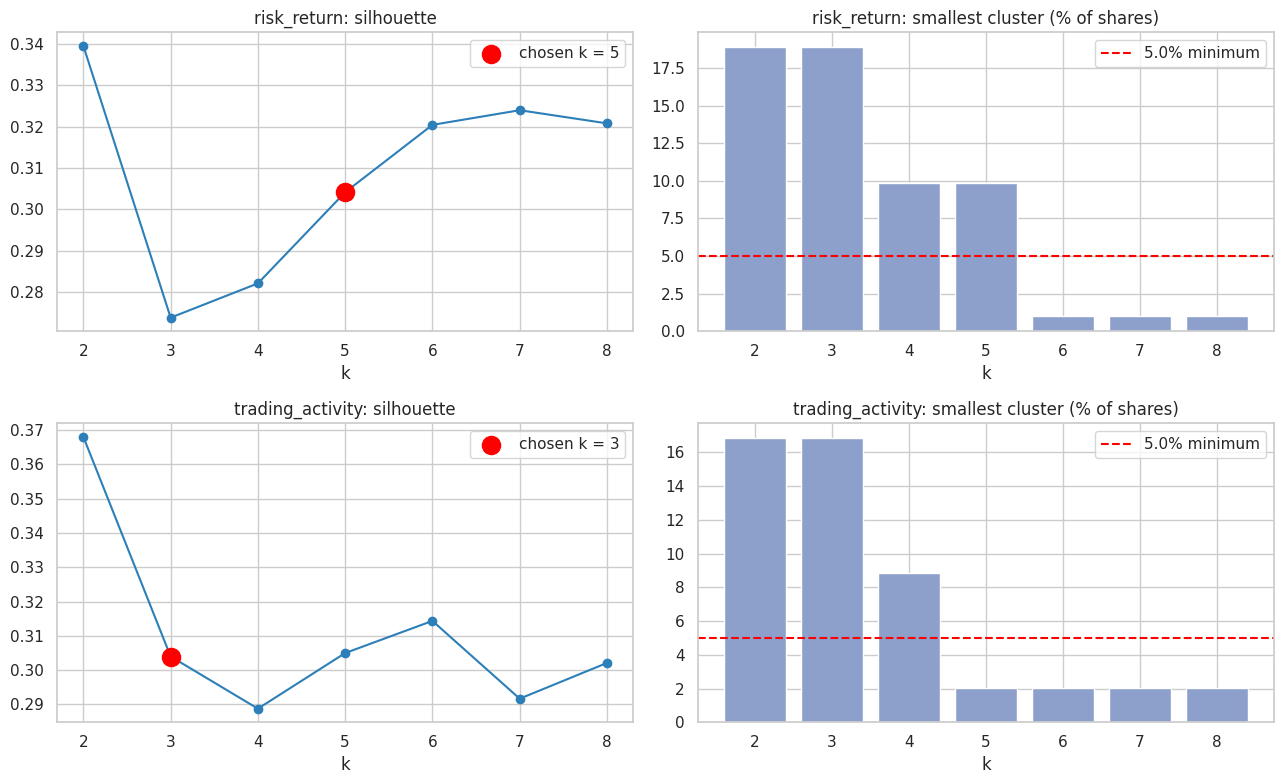

In [35]:
# 2.2e-3  SELECTION CHARTS (SILHOUETTE AND CLUSTER SIZE)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))                    # rows = matrices, columns = silhouette and sizes
for row, name in enumerate(matrices):                              # one row per matrix
    d = ward_diag[ward_diag["matrix"] == name]                     # that matrix's diagnostics
    axes[row, 0].plot(d["k"], d["silhouette"], marker="o", color="#2c7fb8")   # silhouette against k
    axes[row, 0].scatter([K_WARD[name]], d.loc[d["k"] == K_WARD[name], "silhouette"], s=170, color="red", zorder=3, label="chosen k = " + str(K_WARD[name]))   # chosen k in red
    axes[row, 0].set_title(name + ": silhouette"); axes[row, 0].set_xlabel("k"); axes[row, 0].legend()
    axes[row, 1].bar(d["k"], d["smallest_pct"], color="#8da0cb")   # smallest cluster as % of shares
    axes[row, 1].axhline(MIN_CLUSTER_PCT, color="red", ls="--", label=str(MIN_CLUSTER_PCT) + "% minimum")   # the size rule
    axes[row, 1].set_title(name + ": smallest cluster (% of shares)"); axes[row, 1].set_xlabel("k"); axes[row, 1].legend()
plt.tight_layout()                                                 # stop the panels overlapping
plt.savefig(os.path.join(FIG_DIR, "ward_selected_k.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                         # display

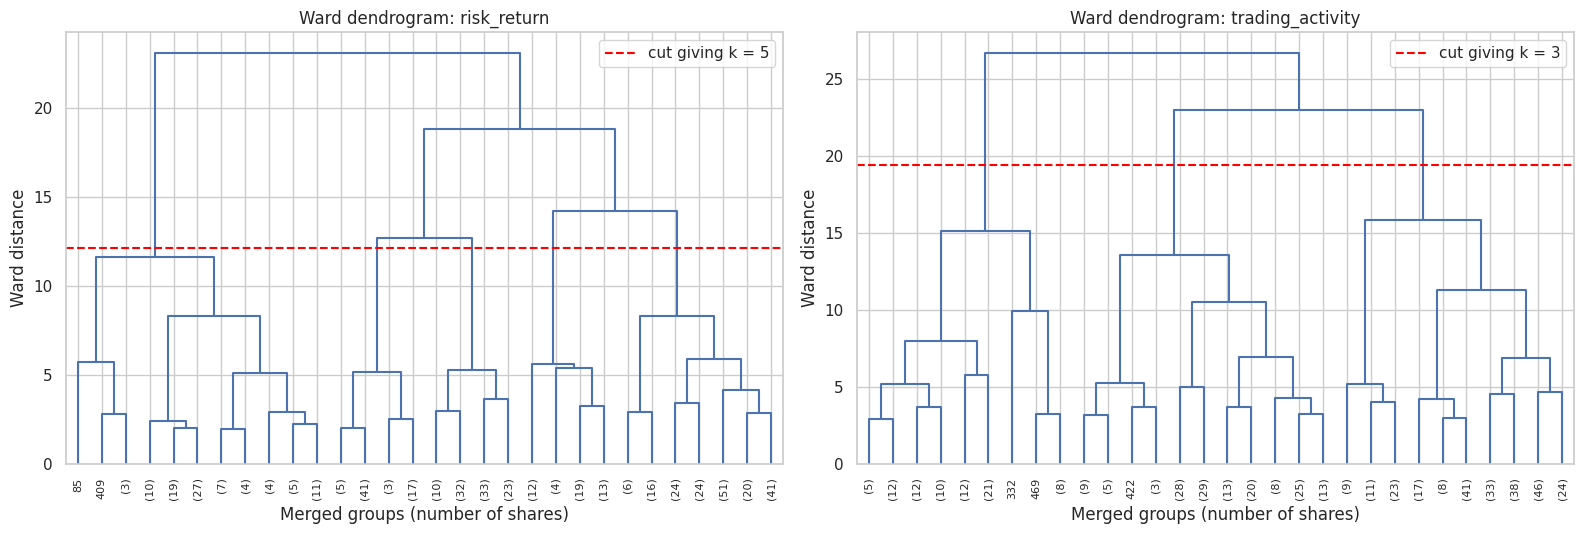

In [36]:
# 2.2e-4  DENDROGRAMS WITH THE CHOSEN CUT
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))                  # one dendrogram per matrix
for ax, name in zip(axes, matrices):
    Zl = linkages[name]; k = K_WARD[name]                          # this matrix's merge tree and chosen k
    dendrogram(Zl, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=8,
               color_threshold=0, above_threshold_color="#4C72B0", ax=ax)   # last 30 merges only, so it stays readable
    ax.axhline((Zl[-(k - 1), 2] + Zl[-k, 2]) / 2, color="red", ls="--", label="cut giving k = " + str(k))   # the chosen cut
    ax.set_title("Ward dendrogram: " + name); ax.set_xlabel("Merged groups (number of shares)"); ax.set_ylabel("Ward distance"); ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "ward_dendrograms_selected.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                         # display

In [37]:
#  2.2e-5  FINAL WARD SOLUTIONS
ward_final = {name: relabel_by_size(ward_labels[(name, K_WARD[name])]) for name in matrices}   # final labels, numbered by size
assignments = pd.DataFrame(index=features_final.index)             # one row per share in the common set
assignments["ward_risk_return"] = ward_final["risk_return"]        # Ward cluster on the risk-return matrix
assignments["ward_trading_activity"] = ward_final["trading_activity"]   # Ward cluster on the trading-activity matrix
for col in assignments.columns:                                    # quick check of the sizes
    print(col, "cluster sizes:", assignments[col].value_counts().sort_index().tolist())

ward_risk_return cluster sizes: [182, 98, 92, 66, 48]
ward_trading_activity cluster sizes: [250, 154, 82]


In [38]:
# 2.2e-6  PROFILES IN READABLE UNITS WITH AUTOMATIC SEGMENT NAMES
overall_med = features_final[core].median()                        # overall median of each feature
overall_iqr = features_final[core].quantile(0.75) - features_final[core].quantile(0.25)   # overall spread (interquartile range)
DISPLAY = {"mean_weekly_return": ("return (% per week)", 100), "weekly_beta": ("beta", 1),
           "R_days": ("Recency (days)", 1), "F_days": ("Frequency (days)", 1),
           "M_usd": ("traded value, 60 sessions (USD bn)", 1e-9)}   # readable label and unit scale for each feature

def level(value, col, words):                                      # describe a cluster median relative to the overall median
    spread = max(overall_iqr[col], 0.25 * features_final[col].std(), 1e-9)   # spread, with a floor so tied values do not blow it up
    z = (value - overall_med[col]) / spread                        # distance from the overall median in spread units
    if z > 1.5: return words[0]                                    # far above
    if z > 0.4: return words[1]                                    # above
    if z < -1.5: return words[4]                                   # far below
    if z < -0.4: return words[3]                                   # below
    return words[2]                                                # about typical

W = {"beta": ("very high beta", "higher beta", "market-like beta", "lower beta", "very low beta"),
     "ret": ("very high return", "higher return", "average return", "lower return", "very low return"),
     "R": ("much older spikes", "older spikes", "typical spike timing", "more recent spikes", "very recent spikes"),
     "F": ("very frequent spikes", "frequent spikes", "typical frequency", "rarer spikes", "very rare spikes"),
     "M": ("very high traded value", "high traded value", "mid traded value", "low traded value", "very low traded value")}   # words for each feature

def profile_final(name, labels):                                   # profile table for one solution, in readable units
    lab = pd.Series(labels, index=orig[name].index, name="cluster")   # cluster of each share
    med = orig[name].groupby(lab).median()                         # median of each original-unit feature (robust to skew)
    prof = pd.DataFrame({"shares": lab.value_counts().sort_index()})   # shares per cluster
    prof["% of shares"] = prof["shares"] / len(lab) * 100          # as a percentage
    for col in orig[name].columns:                                 # add each feature's median in readable units
        text, scale = DISPLAY[col]
        prof["median " + text] = med[col] * scale
    if name == "trading_activity":                                 # also show traded value per day, which is easier to picture
        prof["median traded value per day (USD m)"] = med["M_usd"] / ACTIVITY_DAYS / 1e6
    if name == "risk_return":                                      # automatic names (always numbered, so no two can look identical)
        words = {c: level(med.loc[c, "weekly_beta"], "weekly_beta", W["beta"]) + ", " + level(med.loc[c, "mean_weekly_return"], "mean_weekly_return", W["ret"]) for c in med.index}
    else:
        words = {c: level(med.loc[c, "R_days"], "R_days", W["R"]) + ", " + level(med.loc[c, "F_days"], "F_days", W["F"]) + ", " + level(med.loc[c, "M_usd"], "M_usd", W["M"]) for c in med.index}
    prof.insert(0, "segment", ["C" + str(c) + ": " + words[c] for c in prof.index])   # e.g. "C2: higher beta, average return"
    return prof

for name in matrices:                                              # show and save each Ward profile
    print("Ward profile:", name, "| k =", K_WARD[name])
    prof = profile_final(name, ward_final[name])
    display(prof.round(3))
    prof.to_csv(os.path.join(DATA_DIR, "profile_ward_" + name + ".csv"))

Ward profile: risk_return | k = 5


,segment,shares,% of shares,median return (% per week),median beta
cluster,,,,,
0,"C0: market-like beta, average return",182,37.4490,0.1660,0.9640
1,"C1: lower beta, higher return",98,20.1650,0.3920,0.6660
2,"C2: higher beta, higher return",92,18.9300,0.5500,1.2180
3,"C3: lower beta, lower return",66,13.5800,0.1130,0.4480
4,"C4: higher beta, average return",48,9.8770,0.2520,1.5140


Ward profile: trading_activity | k = 3


,segment,shares,% of shares,median Recency (days),median Frequency (days),"median traded value, 60 sessions (USD bn)",median traded value per day (USD m)
cluster,,,,,,,
0,"C0: typical spike timing, typical frequency, m...",250,51.4400,11.0000,3.0000,11.1780,186.2940
1,"C1: typical spike timing, typical frequency, h...",154,31.6870,11.0000,3.0000,39.6950,661.5910
2,"C2: much older spikes, rarer spikes, mid trade...",82,16.8720,54.5000,2.0000,17.8490,297.4840


K-Means variables not found. Running quick K-Means fallback matching Ward's selected k...


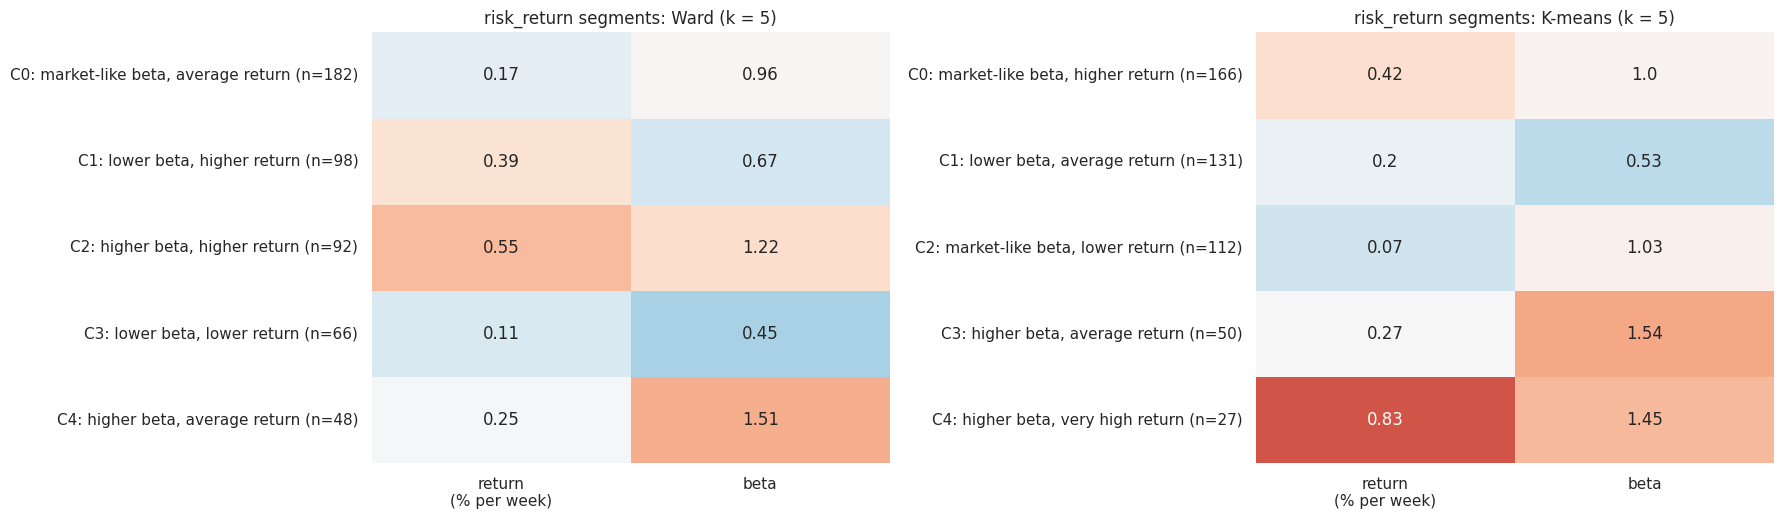

risk_return | agreement between Ward and K-means on the same shares (ARI): 0.318


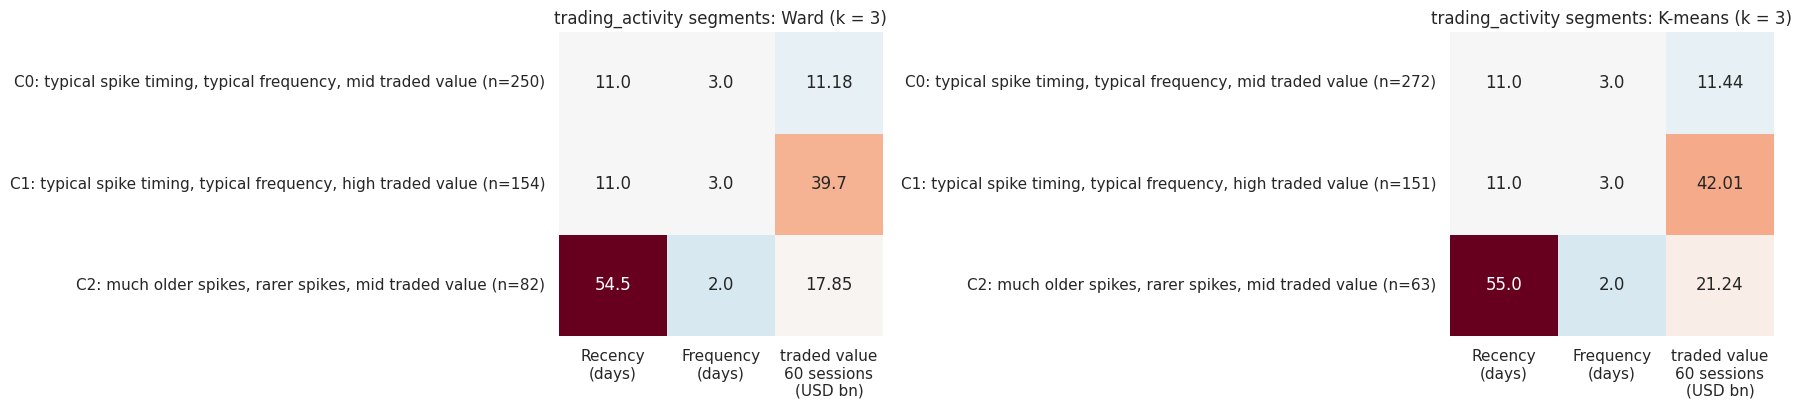

trading_activity | agreement between Ward and K-means on the same shares (ARI): 0.822


In [39]:
# WARD VS K-MEANS FINGERPRINT HEATMAP
from sklearn.cluster import KMeans

# Fallback: If K-Means has not been executed yet in this session, run it quickly to define variables
if 'K_KM' not in globals() or 'km_final' not in globals():
    print("K-Means variables not found. Running quick K-Means fallback matching Ward's selected k...")
    K_KM = {name: K_WARD[name] for name in matrices}
    km_final = {}
    for name, Z in matrices.items():
        kmeans_model = KMeans(n_clusters=K_KM[name], random_state=42, n_init=10)
        # Relabel by size to keep heatmap rows ordered from largest to smallest
        km_final[name] = relabel_by_size(kmeans_model.fit_predict(Z.values))

def fingerprint_named(ax, name, labels, title):                    # heatmap with the segment names on the rows
    cols = list(orig[name].columns)                                # the original feature names
    lab = pd.Series(labels, index=orig[name].index)                # cluster of each share
    med = orig[name].groupby(lab).median()                         # median of each feature per cluster
    rel = ((med - overall_med[cols]) / overall_iqr[cols].clip(lower=1e-9)).clip(-3, 3)   # colour = distance from the overall median (capped at +-3)
    shown = med.copy()                                             # numbers printed in the cells
    for c in cols:
        shown[c] = med[c] * DISPLAY[c][1]                          # convert to readable units
    heads = [DISPLAY[c][0].replace(", 60 sessions", "\n60 sessions").replace(" (", "\n(") for c in cols]   # readable column titles
    rel.columns = heads; shown.columns = heads
    segs = profile_final(name, labels)["segment"]                  # automatic segment names, e.g. "C2: higher beta, average return"
    rows = [segs[c] + " (n=" + str(int((lab == c).sum())) + ")" for c in rel.index]   # row labels with sizes
    rel.index = rows; shown.index = rows
    sns.heatmap(rel, annot=shown.round(2), fmt="", cmap="RdBu_r", center=0, vmin=-3, vmax=3, cbar=False, ax=ax)   # same colour scale on both panels
    ax.set_title(title); ax.set_ylabel("")

for name in matrices:                                              # one figure per matrix
    fig, axes = plt.subplots(1, 2, figsize=(18, 2.6 + 0.55 * max(K_WARD[name], K_KM[name])))   # Ward left, K-means right
    fingerprint_named(axes[0], name, ward_final[name], name + " segments: Ward (k = " + str(K_WARD[name]) + ")")
    fingerprint_named(axes[1], name, km_final[name], name + " segments: K-means (k = " + str(K_KM[name]) + ")")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "fingerprints_" + name + ".png"), dpi=150, bbox_inches="tight")   # save for the report
    plt.show()
    print(name, "| agreement between Ward and K-means on the same shares (ARI):", round(adjusted_rand_score(ward_final[name], km_final[name]), 3))

2.3 K means clustering

In [40]:
# 2.3 K-MEANS CLUSTERING & SENSITIVITY
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

rows_km = []
km_labels = {}

# Run K-means for k = 2 to 8 across both matrices
for name, Z in matrices.items():
    for k in K_RANGE:
        # n_init=10 to find stable global optima
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Z.values)
        labels = km.labels_
        km_labels[(name, k)] = labels
        sizes = np.sort(np.bincount(labels))[::-1]

        rows_km.append({
            "matrix": name,
            "k": k,
            "inertia": km.inertia_,
            "silhouette": silhouette_score(Z.values, labels),
            "calinski_harabasz": calinski_harabasz_score(Z.values, labels),
            "smallest_cluster": int(sizes.min()),
            "smallest_pct": 100 * sizes.min() / len(labels),
            "sizes": ", ".join(map(str, sizes))
        })

km_diag = pd.DataFrame(rows_km)

# Display the K-means diagnostics table for each matrix
for name in matrices:
    print(f"\nK-Means Diagnostics for {name}:")
    display(km_diag[km_diag["matrix"] == name].drop(columns="matrix").set_index("k"))

# Save K-means diagnostics
km_diag.to_csv(os.path.join(DATA_DIR, "kmeans_diagnostics.csv"), index=False)



K-Means Diagnostics for risk_return:


,inertia,silhouette,calinski_harabasz,smallest_cluster,smallest_pct,sizes
k,,,,,,
2,621.6344,0.3869,272.7921,143,29.4239,"343, 143"
3,461.1850,0.3286,267.4888,120,24.6914,"202, 164, 120"
4,371.5771,0.3270,259.6176,40,8.2305,"160, 154, 132, 40"
5,309.6130,0.3406,257.2632,27,5.5556,"166, 131, 112, 50, 27"
6,265.7072,0.3264,255.1836,20,4.1152,"134, 115, 85, 76, 56, 20"
7,227.4762,0.3315,261.2924,5,1.0288,"143, 85, 83, 74, 48, 48, 5"
8,195.9518,0.3527,270.4391,5,1.0288,"143, 82, 81, 77, 36, 34, 28, 5"



K-Means Diagnostics for trading_activity:


,inertia,silhouette,calinski_harabasz,smallest_cluster,smallest_pct,sizes
k,,,,,,
2,"1,066.8319",0.4231,177.4650,68,13.9918,"418, 68"
3,796.6737,0.3253,200.4985,63,12.9630,"272, 151, 63"
4,609.8338,0.3406,223.4576,61,12.5514,"211, 122, 92, 61"
5,514.7136,0.3578,220.3754,11,2.2634,"198, 122, 87, 68, 11"
6,437.4224,0.3455,223.9836,11,2.2634,"141, 120, 104, 69, 41, 11"
7,393.0068,0.3410,216.3371,11,2.2634,"147, 109, 88, 66, 48, 17, 11"
8,342.1749,0.3503,222.6783,1,0.2058,"140, 106, 83, 66, 64, 15, 11, 1"


In [41]:
# 2.3b-1  CHOOSE k FOR K-MEANS AND SHOW THE EVIDENCE
K_OVERRIDE_KM = {}                                                 # leave empty unless you have a written reason from the profiles
K_KM, K_KM_RULE = {}, {}                                           # chosen k and the rule used, per matrix
for name in matrices:                                              # both matrices
    K_KM[name], K_KM_RULE[name] = choose_k(km_diag, name, K_OVERRIDE_KM)   # same written rule as Ward
    print("K-means,", name, "-> k =", K_KM[name], "|", K_KM_RULE[name])
    show_diag(km_diag, name, K_KM[name])                           # formatted table, chosen k highlighted

K-means, risk_return -> k = 5 | highest silhouette among k >= 3 with smallest cluster >= 5.0%


,inertia,silhouette,calinski_harabasz,smallest_pct,largest_pct,sizes,feasible
k,,,,,,,
2,621.6,0.387,272.8,29.4,70.6,343 / 143,False
3,461.2,0.329,267.5,24.7,41.6,202 / 164 / 120,True
4,371.6,0.327,259.6,8.2,32.9,160 / 154 / 132 / 40,True
5,309.6,0.341,257.3,5.6,34.2,166 / 131 / 112 / 50 / 27,True
6,265.7,0.326,255.2,4.1,27.6,134 / 115 / 85 / 76 / 56 / 20,False
7,227.5,0.331,261.3,1.0,29.4,143 / 85 / 83 / 74 / 48 / 48 / 5,False
8,196.0,0.353,270.4,1.0,29.4,143 / 82 / 81 / 77 / 36 / 34 / 28 / 5,False


K-means, trading_activity -> k = 4 | highest silhouette among k >= 3 with smallest cluster >= 5.0%


,inertia,silhouette,calinski_harabasz,smallest_pct,largest_pct,sizes,feasible
k,,,,,,,
2,"1,066.8",0.423,177.5,14.0,86.0,418 / 68,False
3,796.7,0.325,200.5,13.0,56.0,272 / 151 / 63,True
4,609.8,0.341,223.5,12.6,43.4,211 / 122 / 92 / 61,True
5,514.7,0.358,220.4,2.3,40.7,198 / 122 / 87 / 68 / 11,False
6,437.4,0.346,224.0,2.3,29.0,141 / 120 / 104 / 69 / 41 / 11,False
7,393.0,0.341,216.3,2.3,30.2,147 / 109 / 88 / 66 / 48 / 17 / 11,False
8,342.2,0.350,222.7,0.2,28.8,140 / 106 / 83 / 66 / 64 / 15 / 11 / 1,False


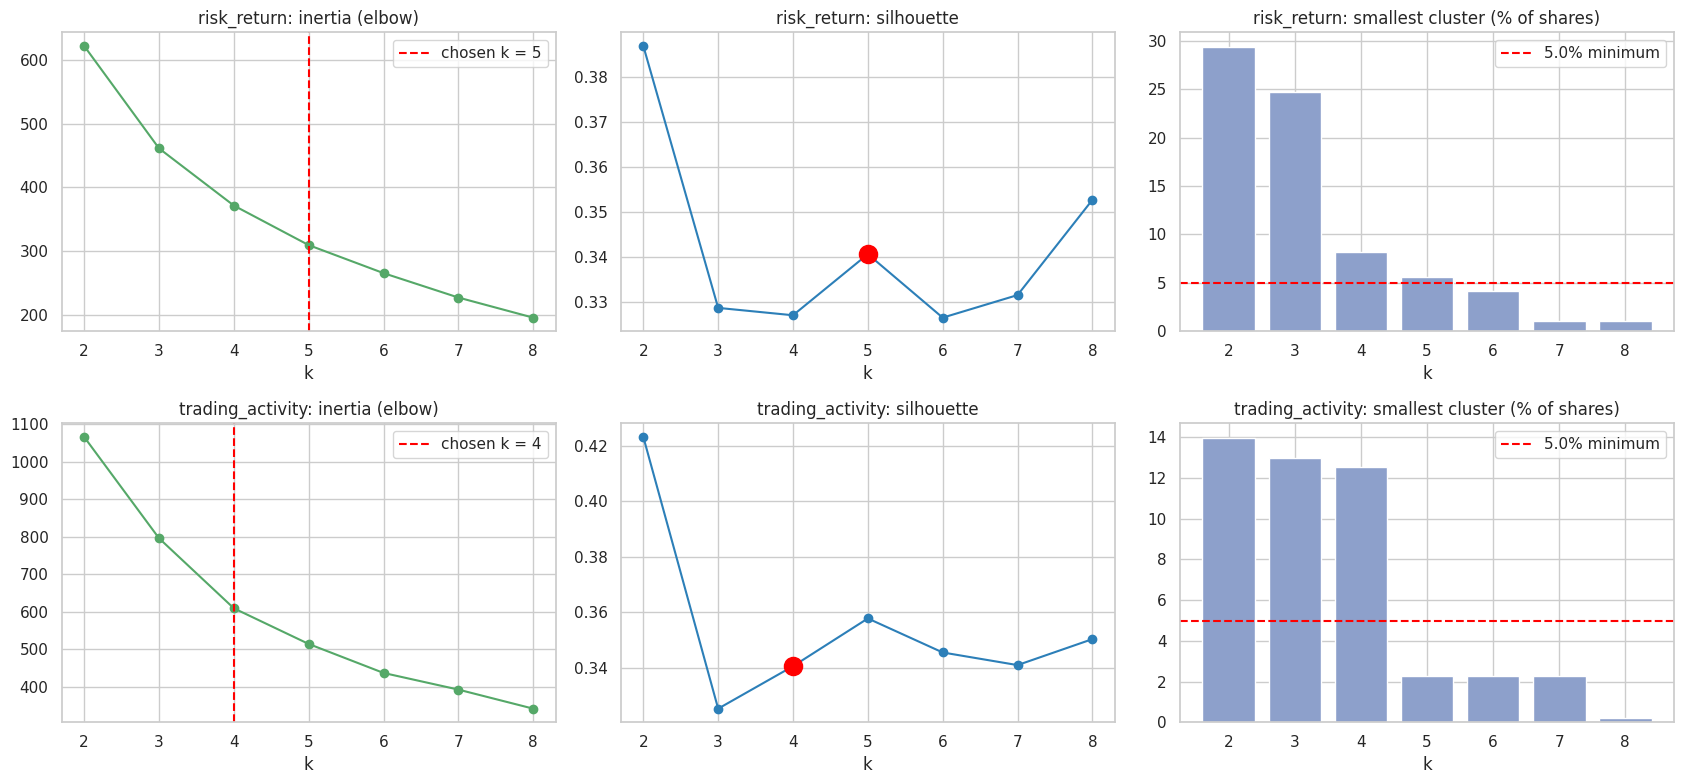

In [42]:
#  2.3b-2  K-MEANS CHARTS: ELBOW, SILHOUETTE, CLUSTER SIZE
fig, axes = plt.subplots(2, 3, figsize=(17, 8))                    # rows = matrices, columns = the three diagnostics
for row, name in enumerate(matrices):                              # one row per matrix
    d = km_diag[km_diag["matrix"] == name]                         # that matrix's diagnostics
    axes[row, 0].plot(d["k"], d["inertia"], marker="o", color="#55A868")   # elbow plot: inertia against k
    axes[row, 0].axvline(K_KM[name], color="red", ls="--", label="chosen k = " + str(K_KM[name]))   # chosen k
    axes[row, 0].set_title(name + ": inertia (elbow)"); axes[row, 0].set_xlabel("k"); axes[row, 0].legend()
    axes[row, 1].plot(d["k"], d["silhouette"], marker="o", color="#2c7fb8")   # silhouette against k
    axes[row, 1].scatter([K_KM[name]], d.loc[d["k"] == K_KM[name], "silhouette"], s=170, color="red", zorder=3)   # chosen k in red
    axes[row, 1].set_title(name + ": silhouette"); axes[row, 1].set_xlabel("k")
    axes[row, 2].bar(d["k"], d["smallest_pct"], color="#8da0cb")   # smallest cluster as a % of shares
    axes[row, 2].axhline(MIN_CLUSTER_PCT, color="red", ls="--", label=str(MIN_CLUSTER_PCT) + "% minimum")   # the size rule
    axes[row, 2].set_title(name + ": smallest cluster (% of shares)"); axes[row, 2].set_xlabel("k"); axes[row, 2].legend()
plt.tight_layout()                                                 # stop the panels overlapping
plt.savefig(os.path.join(FIG_DIR, "kmeans_k_selection.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                         # display

In [43]:
#  2.3b-3  FINAL K-MEANS SOLUTIONS
# Re-fit the final K-means models using the chosen k values (K_KM) to avoid missing references
km_final = {}
for name, Z in matrices.items():
    k_chosen = K_KM[name]
    # Fit K-means with the selected k and stable initialization settings
    km_model = KMeans(n_clusters=k_chosen, random_state=42, n_init=10).fit(Z.values)
    # Relabel the clusters by size (0 = largest) and save
    km_final[name] = relabel_by_size(km_model.labels_)

# Record the assignments into our consolidated table
assignments["kmeans_risk_return"] = km_final["risk_return"]
assignments["kmeans_trading_activity"] = km_final["trading_activity"]

# Display a quick verification of the resulting cluster sizes
for col in ["kmeans_risk_return", "kmeans_trading_activity"]:
    print(col, "cluster sizes:", assignments[col].value_counts().sort_index().tolist())

kmeans_risk_return cluster sizes: [166, 131, 112, 50, 27]
kmeans_trading_activity cluster sizes: [211, 122, 92, 61]


In [44]:
# 2.3b-4  WHY MULTIPLE INITIALISATIONS?
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

# Recreate the final baseline km_models dictionary since only labels were saved previously
km_models = {}
for name, Z in matrices.items():
    k = K_KM[name]
    km_models[(name, k)] = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Z.values)

init_rows = []                                                     # results table
for name in matrices:                                              # both matrices
    k = K_KM[name]; X = matrices[name].values; base = km_models[(name, k)]   # chosen k, data, and the final 10-start model
    aris, inertias = [], []                                        # scores from the single-start runs
    for s in range(20):                                            # 20 runs, each with ONE random start
        single = KMeans(n_clusters=k, init="random", n_init=1, random_state=s).fit(X)   # no smart start, no repeats
        aris.append(adjusted_rand_score(base.labels_, single.labels_))   # agreement with the final solution
        inertias.append(single.inertia_)                           # how tight that single start was
    init_rows.append({"matrix": name, "k": k, "final inertia (10 starts)": base.inertia_,
                      "single-start inertia: best": min(inertias), "single-start inertia: worst": max(inertias),
                      "ARI vs final: lowest": min(aris), "ARI vs final: average": float(np.mean(aris))})
init_table = pd.DataFrame(init_rows).set_index("matrix")           # combine
display(init_table.round(3))                                       # a worst-case inertia above the final one shows why many starts matter
init_table.to_csv(os.path.join(DATA_DIR, "kmeans_initialisation_check.csv"))   # save for GitHub

,k,final inertia (10 starts),single-start inertia: best,single-start inertia: worst,ARI vs final: lowest,ARI vs final: average
matrix,,,,,,
risk_return,5,309.6130,309.8350,333.0670,0.2940,0.7090
trading_activity,4,609.8340,609.8340,715.2610,0.4240,0.7220


In [45]:
# 2.3b-5  FINAL K-MEANS PROFILES (READABLE UNITS)
for name in matrices:                                              # show and save each K-means profile
    print("K-means profile:", name, "| k =", K_KM[name])
    prof = profile_final(name, km_final[name])                     # same readable-unit function as Ward
    display(prof.round(3))
    prof.to_csv(os.path.join(DATA_DIR, "profile_kmeans_" + name + ".csv"))

K-means profile: risk_return | k = 5


,segment,shares,% of shares,median return (% per week),median beta
cluster,,,,,
0,"C0: market-like beta, higher return",166,34.1560,0.4150,0.9960
1,"C1: lower beta, average return",131,26.9550,0.2030,0.5300
2,"C2: market-like beta, lower return",112,23.0450,0.0750,1.0320
3,"C3: higher beta, average return",50,10.2880,0.2670,1.5430
4,"C4: higher beta, very high return",27,5.5560,0.8310,1.4500


K-means profile: trading_activity | k = 4


,segment,shares,% of shares,median Recency (days),median Frequency (days),"median traded value, 60 sessions (USD bn)",median traded value per day (USD m)
cluster,,,,,,,
0,"C0: typical spike timing, rarer spikes, mid tr...",211,43.4160,11.0000,2.0000,13.3300,222.1610
1,"C1: typical spike timing, frequent spikes, mid...",122,25.1030,11.0000,4.0000,12.8260,213.7650
2,"C2: typical spike timing, typical frequency, h...",92,18.9300,11.0000,3.0000,58.7560,979.2690
3,"C3: much older spikes, rarer spikes, mid trade...",61,12.5510,55.0000,2.0000,21.2420,354.0350


In [46]:
# 2.3c  SAVE ALL FOUR BASELINE SOLUTIONS
assert assignments.notna().all().all() and assignments.index.equals(features_final.index)   # every share has a cluster in every solution
assert assignments.shape[1] == 4                                   # exactly four baseline solutions
assignments.to_csv(os.path.join(DATA_DIR, "cluster_assignments.csv"))   # the four baseline assignments
features_final.join(assignments).to_csv(os.path.join(DATA_DIR, "feature_table_with_clusters.csv"))   # feature table plus assignments
print("Saved", assignments.shape[1], "baseline solutions for", len(assignments), "shares")

Saved 4 baseline solutions for 486 shares


2.4 Cluster profiles and algorithm comparison

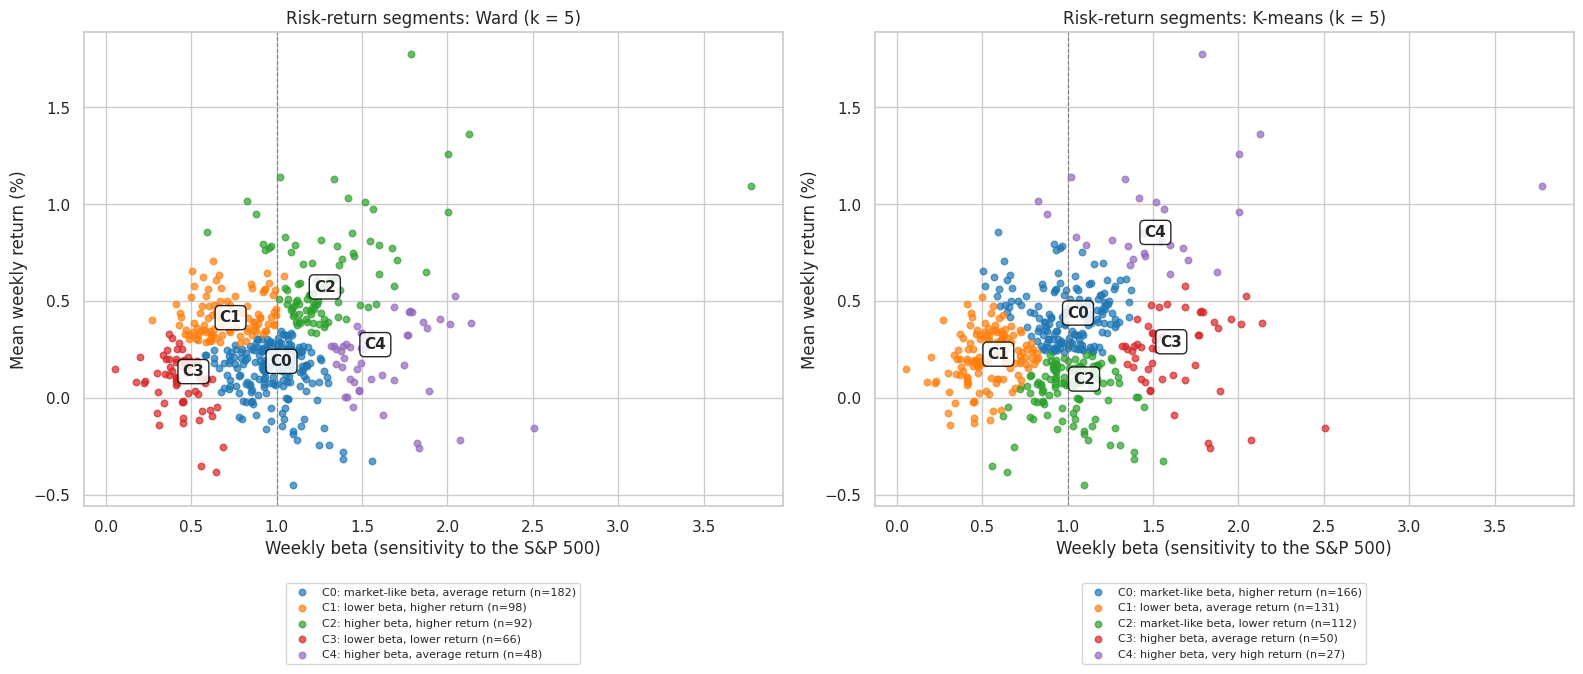

In [47]:
# 2.4a  RISK-RETURN CLUSTERS IN ORIGINAL UNITS (WARD AND K-MEANS)
def scatter_rr(ax, labels, title):
    lab = pd.Series(labels, index=features_final.index)            # cluster of each share
    segs = profile_final("risk_return", labels)["segment"]         # automatic segment names
    palette = sns.color_palette("tab10", lab.nunique())            # changed from Set2 to tab10 for higher contrast
    for c in sorted(lab.unique()):                                 # one cluster at a time
        m = lab == c                                               # shares in this cluster
        ax.scatter(features_final.loc[m, "weekly_beta"], features_final.loc[m, "mean_weekly_return"] * 100,
                   s=22, alpha=0.7, color=palette[c], label=segs[c] + " (n=" + str(int(m.sum())) + ")")   # the shares
        ax.annotate("C" + str(c), (features_final.loc[m, "weekly_beta"].median(), features_final.loc[m, "mean_weekly_return"].median() * 100),
                    fontsize=11, weight="bold", bbox=dict(boxstyle="round", fc="white", ec="black", alpha=0.85))   # label at the cluster's median
    ax.axvline(1, color="grey", ls="--", lw=0.8)                   # beta = 1 means "moves with the market"
    ax.set_xlabel("Weekly beta (sensitivity to the S&P 500)"); ax.set_ylabel("Mean weekly return (%)"); ax.set_title(title)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15))   # legend below the plot

fig, axes = plt.subplots(1, 2, figsize=(16, 7))                    # Ward left, K-means right
scatter_rr(axes[0], ward_final["risk_return"], "Risk-return segments: Ward (k = " + str(K_WARD["risk_return"]) + ")")
scatter_rr(axes[1], km_final["risk_return"], "Risk-return segments: K-means (k = " + str(K_KM["risk_return"]) + ")")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "risk_return_clusters_2d.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()                                                         # display

PC1 keeps 45.8 % and PC2 keeps 33.6 % of the variation; together 79.4 % ( 20.6 % is hidden in this view)


,PC1,PC2
R_days,0.7110,0.0230
F_days,-0.6500,0.4020
log1p_M,0.2680,0.9150


PC1 is driven mostly by R_days (loading 0.71 )
PC2 is driven mostly by log1p_M (loading 0.92 )


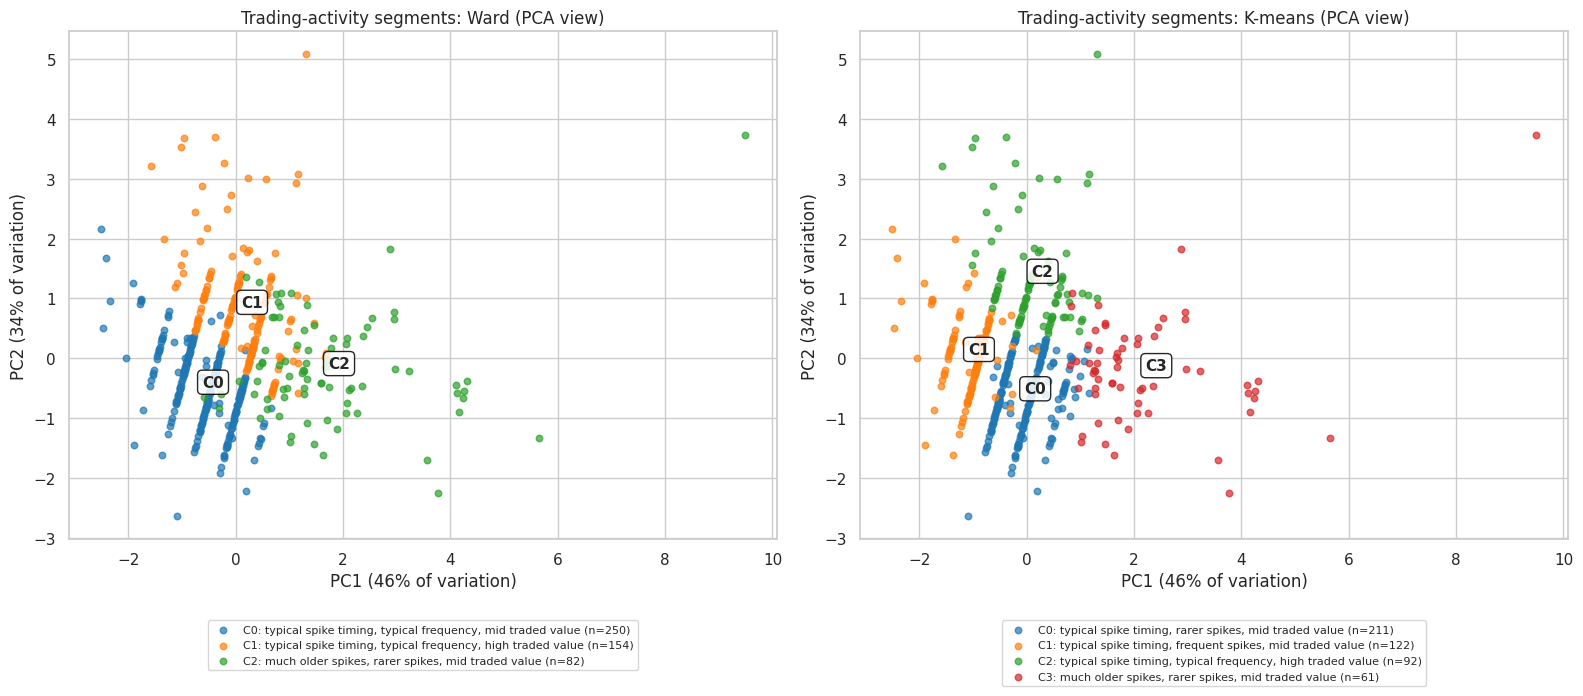

In [48]:
#2.4b  PCA: TRADING-ACTIVITY FEATURES IN TWO DIMENSIONS
from sklearn.decomposition import PCA                              # principal component analysis

pca = PCA(n_components=2, random_state=42).fit(Z_act)            # find the 2 directions that keep the most variation
coords = pca.transform(Z_act)                                      # every share's position on those 2 directions
explained = pca.explained_variance_ratio_                          # share of the total variation kept by PC1 and PC2
loadings = pd.DataFrame(pca.components_.T, index=Z_act.columns, columns=["PC1", "PC2"])   # how each feature feeds each component
print("PC1 keeps", round(100 * explained[0], 1), "% and PC2 keeps", round(100 * explained[1], 1), "% of the variation;",
      "together", round(100 * explained.sum(), 1), "% (", round(100 * (1 - explained.sum()), 1), "% is hidden in this view)")
display(loadings.round(3))
for pc in ["PC1", "PC2"]:
    top = loadings[pc].abs().idxmax()
    print(pc, "is driven mostly by", top, "(loading", round(float(loadings.loc[top, pc]), 2), ")")

def scatter_pca(ax, labels, title):                                # PCA scatter coloured by cluster
    lab = pd.Series(labels, index=features_final.index)            # cluster of each share
    segs = profile_final("trading_activity", labels)["segment"]    # automatic segment names
    palette = sns.color_palette("tab10", lab.nunique())             # one colour per cluster (changed to tab10 for higher contrast)
    for c in sorted(lab.unique()):
        m = (lab == c).values                                      # shares in this cluster
        ax.scatter(coords[m, 0], coords[m, 1], s=22, alpha=0.7, color=palette[c], label=segs[c] + " (n=" + str(int(m.sum())) + ")")
        ax.annotate("C" + str(c), (coords[m, 0].mean(), coords[m, 1].mean()), fontsize=11, weight="bold",
                    bbox=dict(boxstyle="round", fc="white", ec="black", alpha=0.85))   # label at the cluster's average position
    ax.set_xlabel("PC1 (" + format(100 * explained[0], ".0f") + "% of variation)")
    ax.set_ylabel("PC2 (" + format(100 * explained[1], ".0f") + "% of variation)"); ax.set_title(title)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15))

fig, axes = plt.subplots(1, 2, figsize=(16, 7.2))                  # Ward left, K-means right
scatter_pca(axes[0], ward_final["trading_activity"], "Trading-activity segments: Ward (PCA view)")
scatter_pca(axes[1], km_final["trading_activity"], "Trading-activity segments: K-means (PCA view)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "trading_activity_clusters_pca.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()

In [49]:
# 2.4c-2a  QUALITY OF THE FOUR SOLUTIONS ON THE SAME SHARES
from scipy.spatial.distance import pdist, squareform               # pairwise distances between shares
from sklearn.metrics import silhouette_samples                     # silhouette of every individual share

def within_ss(Z, labs):                                            # total squared distance from each share to its cluster centre
    return float(sum(((Z[labs == c] - Z[labs == c].mean(axis=0)) ** 2).sum() for c in np.unique(labs)))

def dunn_index(D, labs):                                           # Dunn index: smallest gap between clusters / largest cluster width
    same = labs[:, None] == labs[None, :]                          # True where two shares are in the same cluster
    return float(D[~same].min() / D[same].max())                   # higher = compact clusters that are clearly apart

rows = []
for name in matrices:                                              # both matrices
    Z = matrices[name].values                                      # the standardised data both algorithms used
    D = squareform(pdist(Z))                                       # distance between every pair of shares (computed once per matrix)
    for method, labs in [("Ward", ward_final[name]), ("K-means", km_final[name])]:
        sil = silhouette_samples(Z, labs)                          # silhouette of each share (negative = probably in the wrong cluster)
        rows.append({"matrix": name, "algorithm": method, "k": len(np.unique(labs)),
                     "silhouette": float(sil.mean()),                              # higher = better
                     "calinski_harabasz": calinski_harabasz_score(Z, labs),        # higher = better
                     "dunn": dunn_index(D, labs),                                  # higher = better
                     "within-cluster SS": within_ss(Z, labs),                      # lower = tighter
                     "share with negative silhouette %": 100 * float((sil < 0).mean()),   # lower = fewer doubtful assignments
                     "smallest cluster": int(np.bincount(labs).min())})
quality = pd.DataFrame(rows).set_index(["matrix", "algorithm"])    # combine
display(quality.round(3))
quality.to_csv(os.path.join(DATA_DIR, "algorithm_comparison_quality.csv"))   # save for GitHub
print("Calinski-Harabasz and within-cluster SS are only comparable between solutions with the SAME k. The Dunn index depends on the single closest pair and the single widest cluster, so outliers can make it small for every solution.")

# --- Which algorithm is better on each measure? ---
directions = [("silhouette", True), ("calinski_harabasz", True), ("dunn", True), ("within-cluster SS", False), ("share with negative silhouette %", False)]
verdict = []
for name in matrices:                                              # both matrices
    w, k = quality.loc[(name, "Ward")], quality.loc[(name, "K-means")]
    row = {"matrix": name, "k (Ward / K-means)": str(int(w["k"])) + " / " + str(int(k["k"]))}
    for metric, higher in directions:
        if w["k"] != k["k"] and metric in ["calinski_harabasz", "within-cluster SS"]:
            row[metric] = "n/a (different k)"                      # not comparable when k differs
        elif abs(w[metric] - k[metric]) < 1e-9 * max(1.0, abs(w[metric])):
            row[metric] = "tie"
        else:
            row[metric] = "Ward" if (w[metric] > k[metric]) == higher else "K-means"   # the algorithm with the better value
    verdict.append(row)
display(pd.DataFrame(verdict).set_index("matrix"))                 # a summary of who wins where

k  silhouette  calinski_harabasz   dunn  \
matrix           algorithm                                            
risk_return      Ward       5      0.3040           215.7970 0.0110   
                 K-means    5      0.3410           257.2630 0.0080   
trading_activity Ward       3      0.3040           179.0580 0.0080   
                 K-means    4      0.3410           223.4580 0.0030   

                            within-cluster SS  \
matrix           algorithm                      
risk_return      Ward                347.8170   
                 K-means             309.6130   
trading_activity Ward                837.2380   
                 K-means             609.8340   

                            share with negative silhouette %  smallest cluster  
matrix           algorithm                                                      
risk_return      Ward                                 7.8190                48  
                 K-means                              2.2630                27  
trading_activity Ward                                 6.7900                82  
                 K-means                              2.2630                61

Calinski-Harabasz and within-cluster SS are only comparable between solutions with the SAME k. The Dunn index depends on the single closest pair and the single widest cluster, so outliers can make it small for every solution.


,k (Ward / K-means),silhouette,calinski_harabasz,dunn,within-cluster SS,share with negative silhouette %
matrix,,,,,,
risk_return,5 / 5,K-means,K-means,Ward,K-means,K-means
trading_activity,3 / 4,K-means,n/a (different k),Ward,n/a (different k),K-means


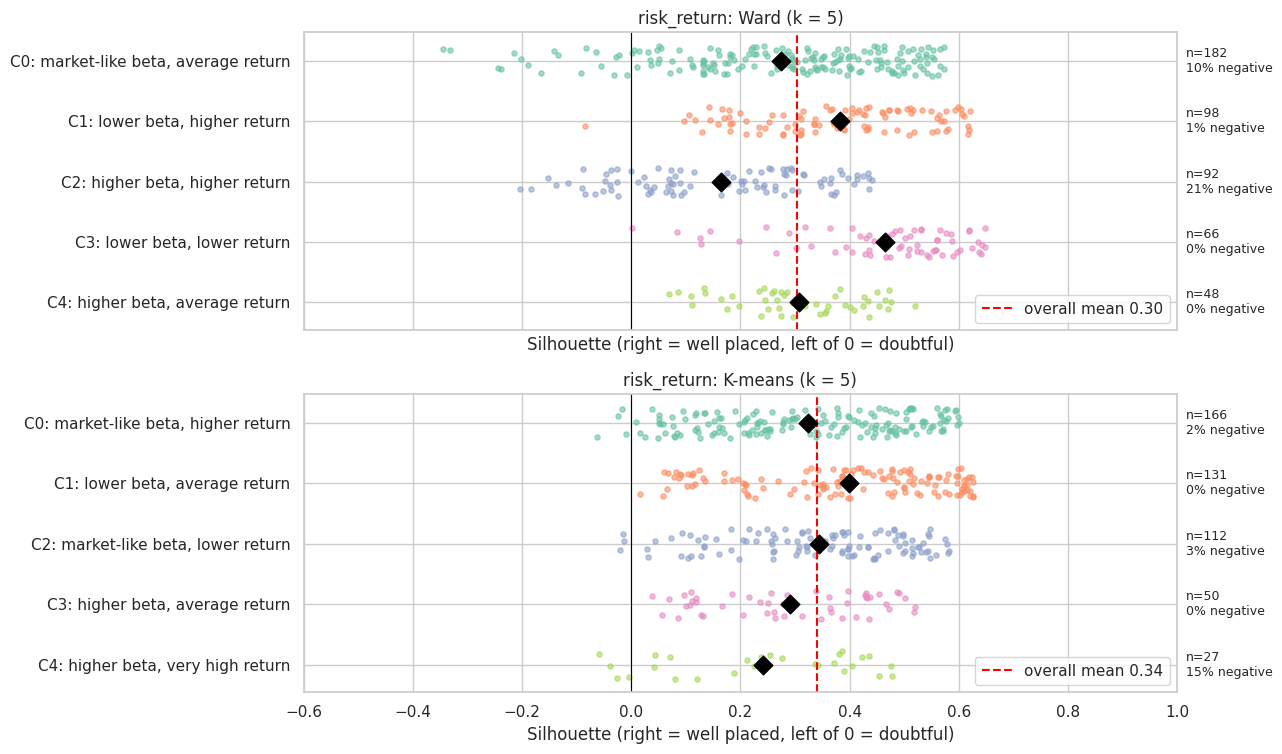

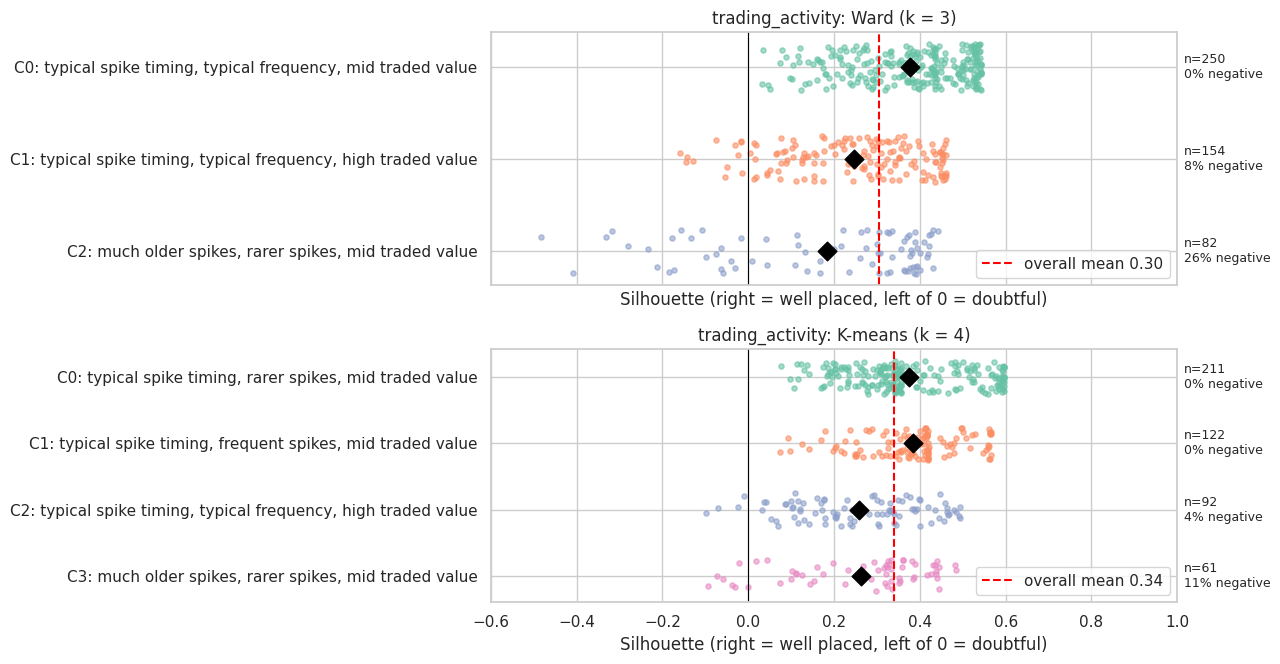

In [50]:
# 2.4c-2b  CLUSTER QUALITY DASHBOARD (ONE DOT PER SHARE)
SEED = 42                                                          # Define default SEED to fix NameError
rng_plot = np.random.default_rng(SEED)                             # fixed seed so the dot jitter is the same every run

def sil_dashboard(ax, name, labs, title):                          # one panel: every share's silhouette, grouped by segment
    sil = silhouette_samples(matrices[name].values, labs)          # silhouette of each share (-1 to 1; negative = probably misplaced)
    segs = profile_final(name, labs)["segment"]                    # readable segment names, e.g. "C2: higher beta, average return"
    order = sorted(np.unique(labs))                                # cluster numbers in order
    palette = sns.color_palette("Set2", len(order))                # one colour per cluster
    for i, c in enumerate(order):                                  # one horizontal lane per cluster
        v = sil[labs == c]                                         # silhouettes of this cluster's shares
        ax.scatter(v, i + rng_plot.uniform(-0.25, 0.25, len(v)), s=14, alpha=0.6, color=palette[c])   # one dot per share, jittered up and down so dots do not hide each other
        ax.scatter(v.mean(), i, marker="D", s=90, color="black", zorder=3)                           # black diamond = the segment's average
        ax.text(1.01, i, "n=" + str(len(v)) + "\n" + format(100 * (v < 0).mean(), ".0f") + "% negative", transform=ax.get_yaxis_transform(), va="center", fontsize=9)   # size and % doubtful, on the right
    ax.axvline(0, color="black", lw=0.8)                           # left of this line = closer to another cluster than its own
    ax.axvline(sil.mean(), color="red", ls="--", label="overall mean " + format(sil.mean(), ".2f"))   # overall average
    ax.set_yticks(range(len(order))); ax.set_yticklabels([segs[c] for c in order]); ax.invert_yaxis()   # segment names on the left
    ax.set_xlim(-0.6, 1.0); ax.set_xlabel("Silhouette (right = well placed, left of 0 = doubtful)"); ax.set_title(title); ax.legend(loc="lower right")

for name in matrices:                                              # one figure per matrix, Ward on top and K-means below
    kmax = max(len(np.unique(ward_final[name])), len(np.unique(km_final[name])))
    fig, axes = plt.subplots(2, 1, figsize=(13, 3.2 + 0.9 * kmax), sharex=True)
    sil_dashboard(axes[0], name, ward_final[name], name + ": Ward (k = " + str(len(np.unique(ward_final[name]))) + ")")
    sil_dashboard(axes[1], name, km_final[name], name + ": K-means (k = " + str(len(np.unique(km_final[name]))) + ")")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "silhouette_dashboard_" + name + ".png"), dpi=150, bbox_inches="tight")   # save for the report
    plt.show()

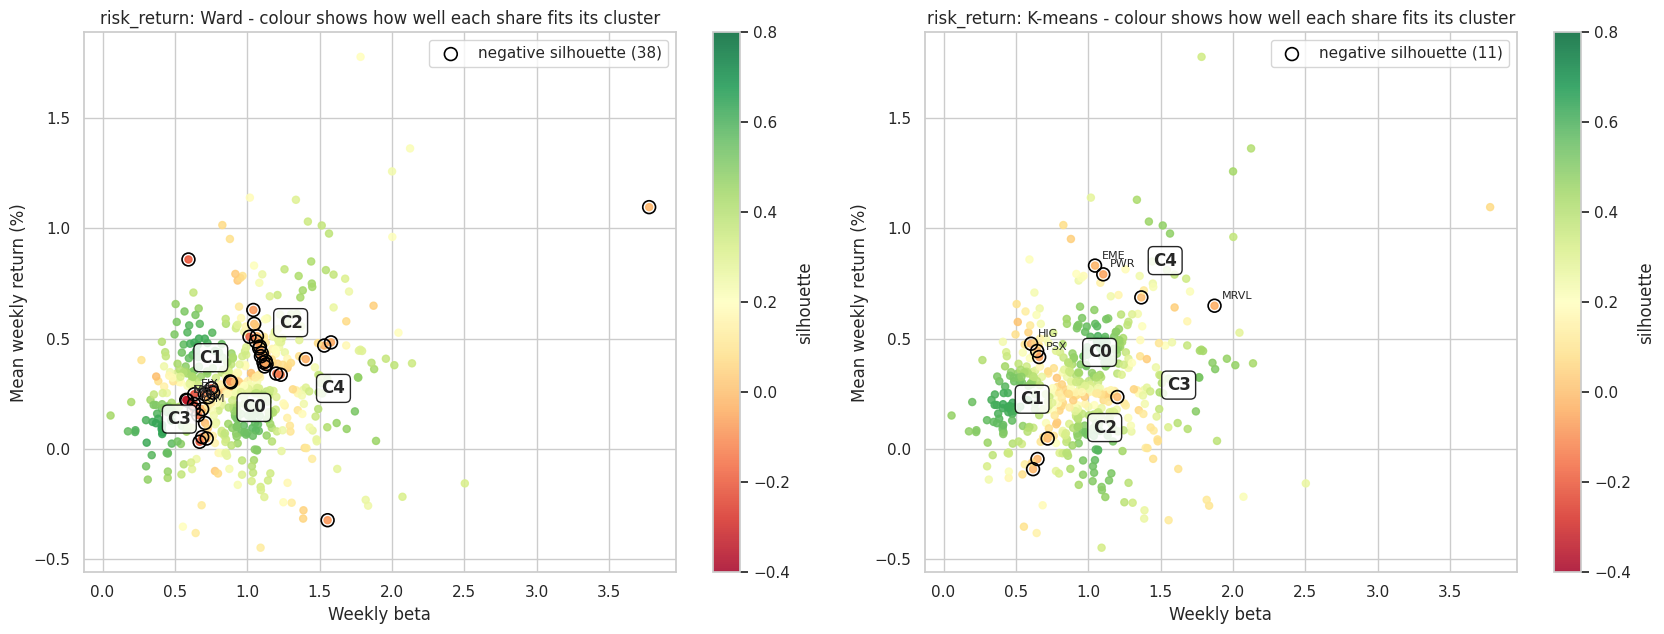

risk_return | Ward | the 8 most doubtful shares


,company,sector,cluster,closer to cluster,silhouette,return (% per week),weekly_beta
ticker,,,,,,,
MCD,McDonald's,Consumer Discretionary,0,3,-0.3450,0.2230,0.5790
EXC,Exelon,Utilities,0,3,-0.3320,0.2210,0.5850
YUM,Yum! Brands,Consumer Discretionary,0,3,-0.2440,0.1810,0.6310
EIX,Edison International,Utilities,0,1,-0.2390,0.2480,0.6340
GL,Globe Life,Financials,0,3,-0.2150,0.2050,0.6320
LLY,Lilly (Eli),Health Care,2,1,-0.2040,0.8590,0.5940
AMCR,Amcor,Materials,0,3,-0.2020,0.0330,0.6710
OMC,Omnicom Group,Communication Services,0,1,-0.1900,0.2760,0.7540


risk_return | K-means | the 8 most doubtful shares


,company,sector,cluster,closer to cluster,silhouette,return (% per week),weekly_beta
ticker,,,,,,,
PSX,Phillips 66,Energy,0,1,-0.0630,0.4170,0.6610
PWR,Quanta Services,Industrials,4,0,-0.0590,0.7920,1.1040
MRVL,Marvell Technology,Information Technology,4,3,-0.0390,0.6500,1.8730
EME,Emcor,Industrials,4,0,-0.0260,0.8310,1.0470
HIG,Hartford (The),Financials,0,1,-0.0240,0.4770,0.6050
CMCSA,Comcast,Communication Services,2,1,-0.0210,-0.0450,0.6490
CASY,Casey's,Consumer Staples,0,1,-0.0170,0.4450,0.6470
MDT,Medtronic,Health Care,2,1,-0.0150,-0.0910,0.6190


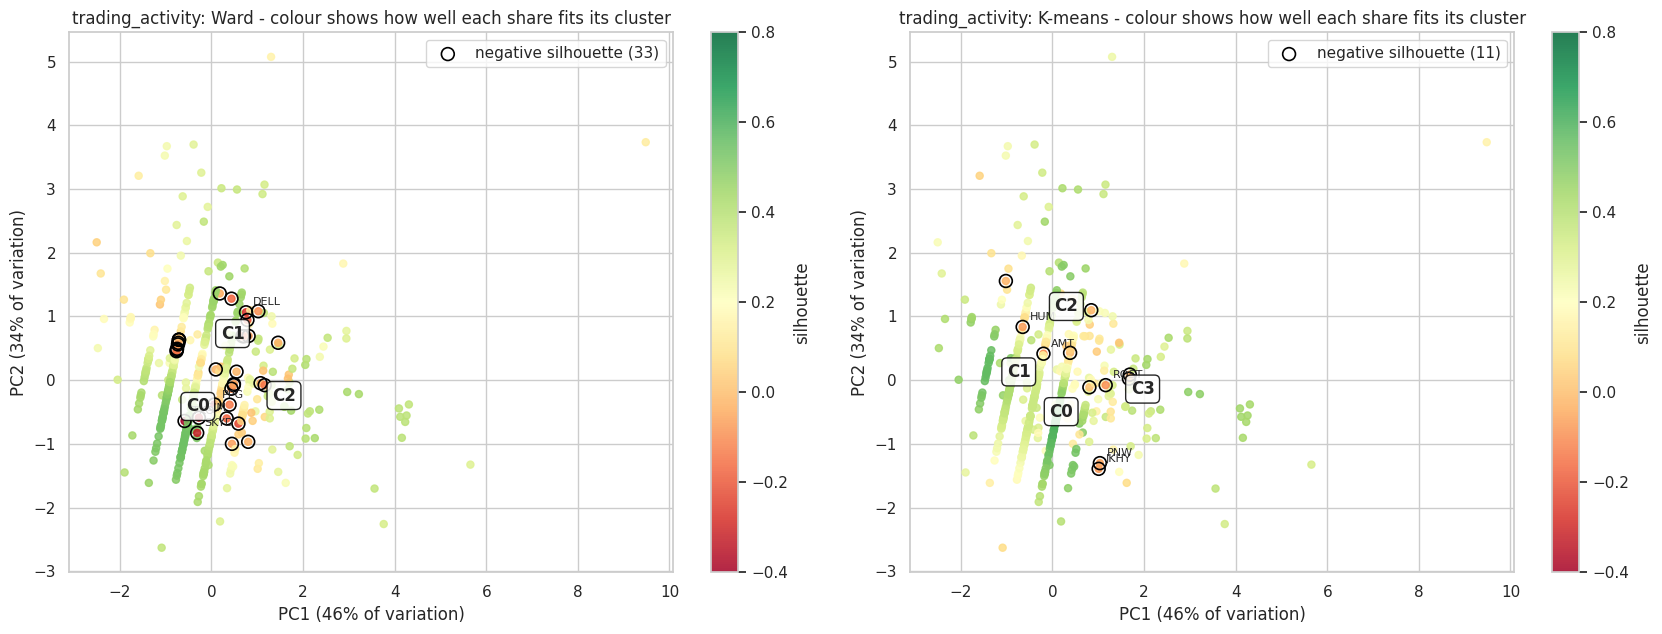

trading_activity | Ward | the 8 most doubtful shares


,company,sector,cluster,closer to cluster,silhouette,R_days,F_days,"M (USD bn, 60 sessions)"
ticker,,,,,,,,
TKO,TKO Group Holdings,Communication Services,2,0,-0.4830,26,4,7.2370
PPG,PPG Industries,Materials,2,0,-0.4080,26,3,12.8910
SJM,J.M. Smucker Company (The),Consumer Staples,2,0,-0.3310,35,4,7.5580
SKYD,Skydance,Communication Services,2,0,-0.3180,36,4,5.9040
DELL,Dell Technologies,Information Technology,2,1,-0.2810,34,3,56.6510
LYB,LyondellBasell,Materials,2,0,-0.2330,27,2,12.9090
GE,GE Aerospace,Industrials,2,1,-0.2140,36,3,49.9260
GM,General Motors,Consumer Discretionary,2,1,-0.1840,35,3,38.4950


trading_activity | K-means | the 8 most doubtful shares


,company,sector,cluster,closer to cluster,silhouette,R_days,F_days,"M (USD bn, 60 sessions)"
ticker,,,,,,,,
AMT,American Tower,Real Estate,2,0,-0.0980,11,3,29.7650
ROST,Ross Stores,Consumer Discretionary,3,0,-0.0930,39,2,23.7030
JKHY,Jack Henry & Associates,Financials,3,0,-0.0720,46,2,6.0910
HUM,Humana,Health Care,2,1,-0.0720,11,4,33.6050
PNW,Pinnacle West Capital,Utilities,3,0,-0.0590,46,2,6.6770
PGR,Progressive Corporation,Financials,3,0,-0.0380,36,1,36.0440
ADI,Analog Devices,Information Technology,3,0,-0.0300,36,1,38.4990
WDAY,"Workday, Inc.",Information Technology,2,1,-0.0250,11,5,51.7040


In [51]:
# 2.4c-2b-2  WHERE ARE THE DOUBTFUL SHARES?
from sklearn.decomposition import PCA                              # for the 2-D view of the trading-activity matrix
pca_view = PCA(n_components=2, random_state=SEED).fit(Z_act)       # same 2-D view as 2.4b
pc = pca_view.transform(Z_act); ev = pca_view.explained_variance_ratio_
views = {"risk_return": (features_final["weekly_beta"].values, features_final["mean_weekly_return"].values * 100, "Weekly beta", "Mean weekly return (%)"),
         "trading_activity": (pc[:, 0], pc[:, 1], "PC1 (" + format(100 * ev[0], ".0f") + "% of variation)", "PC2 (" + format(100 * ev[1], ".0f") + "% of variation)")}

def nearest_other(D, labs):                                        # for each share, the other cluster it is closest to on average
    cl = np.unique(labs)
    mean_d = np.column_stack([D[:, labs == c].mean(axis=1) for c in cl])   # average distance from every share to each cluster
    mean_d[np.arange(len(labs)), np.searchsorted(cl, labs)] = np.inf      # ignore the share's own cluster
    return cl[mean_d.argmin(axis=1)]

for name in matrices:                                              # both matrices
    Zv = matrices[name].values; D = squareform(pdist(Zv)); x, y, xl, yl = views[name]
    fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))              # Ward left, K-means right
    for ax, (method, labs) in zip(axes, [("Ward", ward_final[name]), ("K-means", km_final[name])]):
        sil = silhouette_samples(Zv, labs)                         # silhouette of every share
        sc = ax.scatter(x, y, c=sil, cmap="RdYlGn", vmin=-0.4, vmax=0.8, s=26, alpha=0.85)   # colour = how well placed (red = doubtful, green = well placed)
        neg = sil < 0
        ax.scatter(x[neg], y[neg], facecolors="none", edgecolors="black", s=85, linewidths=1.2, label="negative silhouette (" + str(int(neg.sum())) + ")")   # ring = closer to another cluster than its own
        for i in np.argsort(sil)[:5]:                              # label the 5 most doubtful shares
            ax.annotate(features_final.index[i], (x[i], y[i]), textcoords="offset points", xytext=(5, 5), fontsize=8)
        for c in np.unique(labs):                                  # label each cluster at its middle
            ax.annotate("C" + str(c), (np.median(x[labs == c]), np.median(y[labs == c])), fontsize=12, weight="bold", bbox=dict(boxstyle="round", fc="white", ec="black", alpha=0.85))
        plt.colorbar(sc, ax=ax, label="silhouette"); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(loc="best")
        ax.set_title(name + ": " + method + " - colour shows how well each share fits its cluster")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "doubtful_shares_map_" + name + ".png"), dpi=150, bbox_inches="tight")   # save for the report
    plt.show()
    for method, labs in [("Ward", ward_final[name]), ("K-means", km_final[name])]:   # the most doubtful shares, in a table
        sil = silhouette_samples(Zv, labs); idx = np.argsort(sil)[:8]; other = nearest_other(D, labs)
        t = features_final.iloc[idx][["company", "sector"] + list(orig[name].columns)].copy()
        t.insert(2, "cluster", labs[idx]); t.insert(3, "closer to cluster", other[idx]); t.insert(4, "silhouette", sil[idx])
        if "M_usd" in t.columns: t["M_usd"] = t["M_usd"] / 1e9; t = t.rename(columns={"M_usd": "M (USD bn, 60 sessions)"})   # traded value in USD billions
        if "mean_weekly_return" in t.columns: t["mean_weekly_return"] = t["mean_weekly_return"] * 100; t = t.rename(columns={"mean_weekly_return": "return (% per week)"})   # return in % per week
        print(name, "|", method, "| the 8 most doubtful shares")
        display(t.round(3))

2.5 RFM sensitivity and correlated inputs

Pearson correlations (R, F, log1p(M)):


,R_days,F_days,log1p_M
R_days,1.0000,-0.3460,0.1520
F_days,-0.3460,1.0000,0.0130
log1p_M,0.1520,0.0130,1.0000


Spearman correlations:


,R_days,F_days,log1p_M
R_days,1.0000,-0.1960,0.1370
F_days,-0.1960,1.0000,-0.0480
log1p_M,0.1370,-0.0480,1.0000


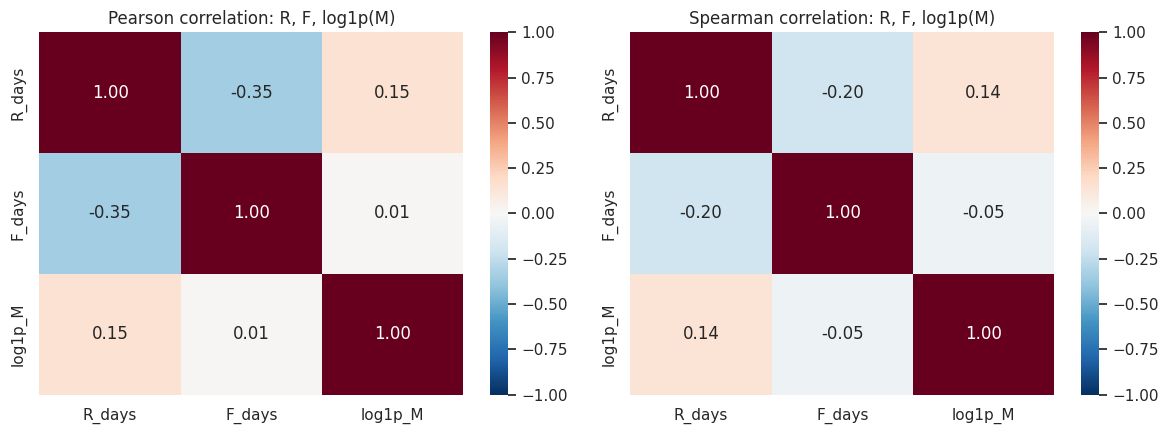

Share of the total variation on the strongest shared direction (PC1): 45.8 % | it would be 33.3% if the three features were completely unrelated
Effective number of independent dimensions: 2.74 of 3 (3.00 would mean no overlap; lower means overlapping features)


In [52]:
# 2.5.1a  CORRELATIONS AMONG R, F AND log1p(M)
corr_p = X_act.corr(method="pearson")                              # Pearson correlation (straight-line relationship)
corr_s = X_act.corr(method="spearman")                             # Spearman correlation (rank-based; safer for skewed or tied data such as R)
print("Pearson correlations (R, F, log1p(M)):")
display(corr_p.round(3))
print("Spearman correlations:")
display(corr_s.round(3))
corr_p.to_csv(os.path.join(DATA_DIR, "rfm_correlations_pearson.csv"))   # save for GitHub
corr_s.to_csv(os.path.join(DATA_DIR, "rfm_correlations_spearman.csv"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))                  # one heatmap per correlation type
for ax, c, t in zip(axes, [corr_p, corr_s], ["Pearson", "Spearman"]):
    sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax)   # red = positive, blue = negative
    ax.set_title(t + " correlation: R, F, log1p(M)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "rfm_correlations.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()

# --- How much extra weight does the shared information get in the distances? ---
eig = np.sort(np.linalg.eigvalsh(corr_p.values))[::-1]             # eigenvalues of the correlation matrix (they add up to 3)
print("Share of the total variation on the strongest shared direction (PC1):", round(100 * eig[0] / eig.sum(), 1), "%",
      "| it would be 33.3% if the three features were completely unrelated")
print("Effective number of independent dimensions:", round(float(eig.sum() ** 2 / (eig ** 2).sum()), 2), "of 3",
      "(3.00 would mean no overlap; lower means overlapping features)")

,eta-squared (variation explained by clusters),share of total separation
R_days,0.6420,0.5030
F_days,0.1190,0.0930
log1p_M,0.5160,0.4040


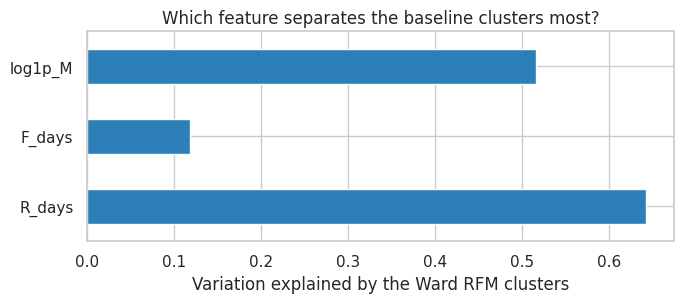

In [53]:
#  2.5.1b  DOES THE OVERLAP ACTUALLY DRIVE THE CLUSTERS?
base = ward_final["trading_activity"]                              # the selected Ward RFM solution
lab_base = pd.Series(base, index=Z_act.index)                      # cluster of each share

def eta_sq(x, lab):                                                # share of a feature's variation that is explained by cluster membership
    total = ((x - x.mean()) ** 2).sum()                            # total spread of the feature
    between = sum(len(g) * (g.mean() - x.mean()) ** 2 for _, g in x.groupby(lab))   # spread between the cluster averages
    return float(between / total)                                  # 0 = clusters ignore this feature, 1 = clusters are fully defined by it

sep = pd.DataFrame({"eta-squared (variation explained by clusters)": {c: eta_sq(Z_act[c], lab_base) for c in Z_act.columns}})   # one row per feature
sep["share of total separation"] = sep.iloc[:, 0] / sep.iloc[:, 0].sum()   # each feature's share of the separation across the three
display(sep.round(3))                                              # which feature separates the baseline clusters most?
sep.to_csv(os.path.join(DATA_DIR, "rfm_feature_separation.csv"))   # save for GitHub

fig, ax = plt.subplots(figsize=(7, 3.2))                           # small bar chart
sep.iloc[:, 0].plot(kind="barh", ax=ax, color="#2c7fb8")           # eta-squared for R, F, log1p(M)
ax.set_xlabel("Variation explained by the Ward RFM clusters"); ax.set_title("Which feature separates the baseline clusters most?")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "rfm_feature_separation.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()

k = 3 | shares: 486
Adjusted Rand index, baseline RFM Ward vs R-and-F-only Ward: 0.291 (1 = identical, 0 = no better than chance)
Cluster sizes: baseline [250, 154, 82] | R and F only [272, 125, 89]
Shares in matched clusters: 321 of 486 ( 66.0 % )


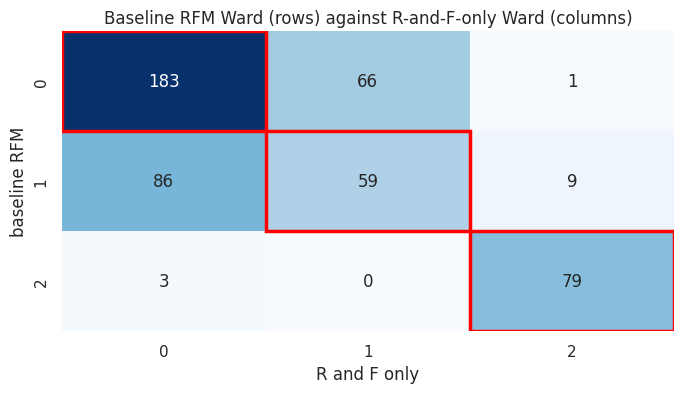

In [54]:
#2.5.2a  REPEAT WARD WITH R AND F ONLY
from scipy.optimize import linear_sum_assignment                   # best one-to-one matching of clusters

K_RFM = K_WARD["trading_activity"]                                 # SAME cluster count as the selected Ward RFM solution
X_rf = X_act[["R_days", "F_days"]].copy()                          # same shares, Monetary removed
Z_rf = pd.DataFrame(StandardScaler().fit_transform(X_rf), index=X_rf.index, columns=X_rf.columns)   # standardised afresh on R and F only
assert Z_rf.index.equals(Z_act.index)                              # the same shares in the same order
assert np.allclose(Z_rf.mean(), 0) and np.allclose(Z_rf.std(ddof=0), 1)   # check the fresh standardisation
ward_rf = relabel_by_size(AgglomerativeClustering(n_clusters=K_RFM, linkage="ward").fit_predict(Z_rf.values))   # Ward, Euclidean, same k

ari_rf = adjusted_rand_score(base, ward_rf)                        # agreement with the baseline (unaffected by cluster numbering)
print("k =", K_RFM, "| shares:", len(ward_rf))
print("Adjusted Rand index, baseline RFM Ward vs R-and-F-only Ward:", round(ari_rf, 3), "(1 = identical, 0 = no better than chance)")
print("Cluster sizes: baseline", np.bincount(base).tolist(), "| R and F only", np.bincount(ward_rf).tolist())

table = pd.crosstab(pd.Series(base, name="baseline RFM"), pd.Series(ward_rf, name="R and F only"))   # counts of shares in each pair
r, c = linear_sum_assignment(-table.values)                        # best matching of clusters
print("Shares in matched clusters:", int(table.values[r, c].sum()), "of", len(base), "(", round(100 * table.values[r, c].sum() / len(base), 1), "% )")
fig, ax = plt.subplots(figsize=(7, 2.6 + 0.5 * len(table)))        # crosstab heatmap
sns.heatmap(table, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
for rr, cc in zip(r, c):
    ax.add_patch(plt.Rectangle((cc, rr), 1, 1, fill=False, edgecolor="red", lw=2.5))   # red box = matched pair
ax.set_title("Baseline RFM Ward (rows) against R-and-F-only Ward (columns)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "monetary_removal_crosstab.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()
pd.DataFrame({"baseline_RFM_ward": base, "R_F_only_ward": ward_rf}, index=Z_act.index).to_csv(os.path.join(DATA_DIR, "monetary_removal_assignments.csv"))   # save both solutions

Baseline RFM Ward profile:


,segment,shares,% of shares,median Recency (days),median Frequency (days),"median traded value, 60 sessions (USD bn)",median traded value per day (USD m)
cluster,,,,,,,
0,"C0: typical spike timing, typical frequency, m...",250,51.4400,11.0000,3.0000,11.1780,186.2940
1,"C1: typical spike timing, typical frequency, h...",154,31.6870,11.0000,3.0000,39.6950,661.5910
2,"C2: much older spikes, rarer spikes, mid trade...",82,16.8720,54.5000,2.0000,17.8490,297.4840


R-and-F-only Ward profile (traded value is NOT used to form these clusters):


,segment,shares,% of shares,median Recency (days),median Frequency (days),"median traded value, 60 sessions (USD bn)",median traded value per day (USD m)
cluster,,,,,,,
0,"C0: typical spike timing, frequent spikes, mid...",272,55.9670,11.0000,4.0000,14.8550,247.5890
1,"C1: typical spike timing, rarer spikes, mid tr...",125,25.7200,11.0000,2.0000,17.6990,294.9830
2,"C2: much older spikes, rarer spikes, mid trade...",89,18.3130,54.0000,2.0000,20.8480,347.4640


,baseline RFM,R and F only
R_days,0.6420,0.6460
F_days,0.1190,0.5430
log1p_M,0.5160,0.0040


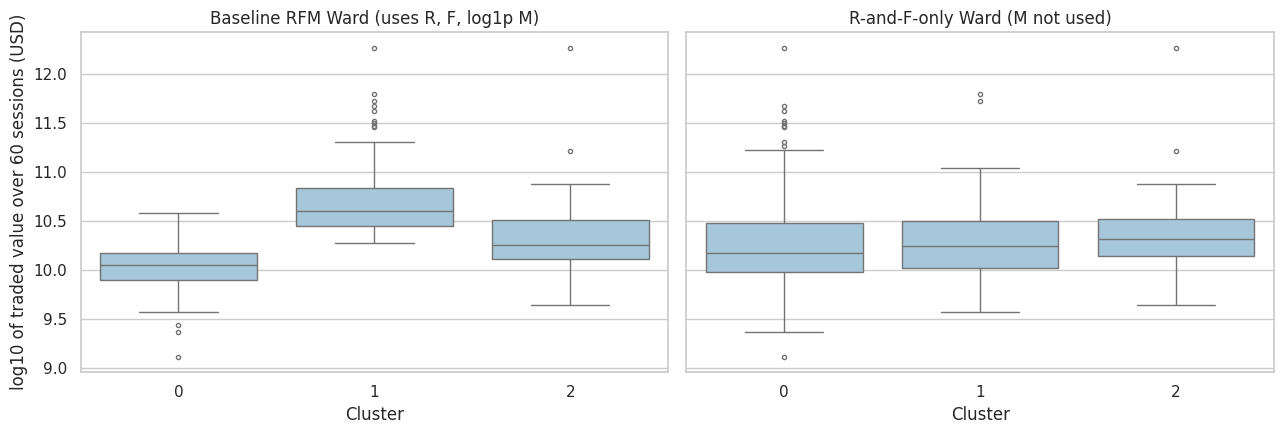

In [55]:
#2.5.2b  DOES MONETARY SEPARATE ACTIVITY OR LIQUIDITY LEVELS?
print("Baseline RFM Ward profile:")
display(profile_final("trading_activity", base).round(3))          # medians in readable units, including traded value
print("R-and-F-only Ward profile (traded value is NOT used to form these clusters):")
display(profile_final("trading_activity", ward_rf).round(3))

lab_rf = pd.Series(ward_rf, index=Z_act.index)                     # cluster of each share in the R-and-F-only solution
cmp_rows = {}                                                      # variation explained by clusters, for each feature and solution
for col in Z_act.columns:
    cmp_rows[col] = {"baseline RFM": eta_sq(Z_act[col], lab_base), "R and F only": eta_sq(Z_act[col], lab_rf)}
cmp_eta = pd.DataFrame(cmp_rows).T                                 # one row per feature
display(cmp_eta.round(3))                                          # does log1p(M) still differ between clusters when it was not used?
cmp_eta.to_csv(os.path.join(DATA_DIR, "monetary_removal_feature_separation.csv"))

logM10 = np.log10(features_final["M_usd"])                         # traded value on a log10 scale (USD)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)     # same y axis so the panels are comparable
for ax, labs, t in zip(axes, [base, ward_rf], ["Baseline RFM Ward (uses R, F, log1p M)", "R-and-F-only Ward (M not used)"]):
    sns.boxplot(x=np.array(labs), y=logM10.values, ax=ax, color="#9ecae1", fliersize=3)   # traded value spread within each cluster
    ax.set_xlabel("Cluster"); ax.set_title(t)
axes[0].set_ylabel("log10 of traded value over 60 sessions (USD)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "monetary_removal_traded_value.png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()

In [56]:
yard = stability.loc[(stability["matrix"] == "trading_activity") & (stability["k"] == K_RFM), "mean_ARI"]   # subsample stability from 2.2d
print("Yardstick (subsample stability of the baseline at this k):", round(float(yard.iloc[0]), 3))

Yardstick (subsample stability of the baseline at this k): 0.527


In [57]:
#  2.5.2d  OPTIONAL EXTENSION: REMOVE EACH FEATURE IN TURN
rows = []                                                          # results table
for drop in X_act.columns:                                         # remove one feature at a time
    keep = [c for c in X_act.columns if c != drop]                 # the two features that remain
    Zk = StandardScaler().fit_transform(X_act[keep])               # standardise the reduced matrix afresh
    labs = AgglomerativeClustering(n_clusters=K_RFM, linkage="ward").fit_predict(Zk)   # Ward, same k
    Zs = StandardScaler().fit_transform(X_act[[drop]])             # the removed feature on its own
    labs1 = AgglomerativeClustering(n_clusters=K_RFM, linkage="ward").fit_predict(Zs)  # Ward using ONLY that feature
    rows.append({"feature removed": drop, "ARI vs baseline when removed": adjusted_rand_score(base, labs),
                 "ARI vs baseline using only this feature": adjusted_rand_score(base, labs1)})
display(pd.DataFrame(rows).set_index("feature removed").round(3))  # lower ARI when removed = the baseline relied more on that feature

,ARI vs baseline when removed,ARI vs baseline using only this feature
feature removed,,
R_days,0.1790,0.3350
F_days,0.7980,0.0220
log1p_M,0.2910,0.1300


# Task 3 Business Intelligence and Critical Review

In [58]:
import sqlite3
import pandas as pd
import os

# Database File definition
DB_FILE = "sp500_data_mart.db"
conn = sqlite3.connect(DB_FILE)


try:
    # Check if dim_share is in python namespace
    if "dim_share" not in locals() and "dim_share" not in globals():
        # Check if table exists in SQLite
        existing_tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table'", conn)["name"].tolist()
        if "dim_share" in existing_tables:
            dim_share = pd.read_sql("SELECT * FROM dim_share", conn)
            print("Successfully recovered 'dim_share' from SQLite database.")
        else:
            # Table is missing in SQLite; recreate it dynamically from active variables
            print("'dim_share' table not found in SQLite database. Recreating dynamically from active variables...")
            dim_share = sp500_list[["ticker", "security", "gics_sector"]].copy().rename(columns={"security": "company", "gics_sector": "sector"})
            dim_share["in_common_set"] = dim_share["ticker"].isin(common_shares).astype(int)
            # Save it back to SQL so the schema is completed
            dim_share.to_sql("dim_share", conn, index=False, if_exists="replace")
            print("Recreated 'dim_share' and successfully written to SQLite.")
except Exception as e:
    print("Could not recover dim_share. Ensure preceding cells in Task 1 and 2 were run.")
    raise e

# ===================== 3.1c  COMPLETE THE STAR SCHEMA: SECTOR DIMENSION AND BENCHMARK FACT =====================
dim_sector = (dim_share.groupby("sector").agg(shares_listed=("ticker", "count"), shares_in_common_set=("in_common_set", "sum"))
              .reset_index())
dim_sector["shares_in_common_set"] = dim_sector["shares_in_common_set"].astype(int)
z
fact_benchmark = pd.DataFrame({"date": trading_days.strftime("%Y-%m-%d"), "benchmark_ticker": INDEX_TICKER,
                               "close": close_all[INDEX_TICKER].reindex(trading_days).values,
                               "adj_close": adj_all[INDEX_TICKER].reindex(trading_days).values})
fact_benchmark["daily_return"] = fact_benchmark["adj_close"].pct_change()

assert not fact_benchmark.duplicated(["date", "benchmark_ticker"]).any()
assert set(dim_share["sector"]) == set(dim_sector["sector"])

# Add the completed dimensions and facts to our data mart
dim_sector.to_sql("dim_sector", conn, index=False, if_exists="replace")
fact_benchmark.to_sql("fact_benchmark_day", conn, index=False, if_exists="replace")

tables_now = pd.read_sql("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", conn)["name"].tolist()
print("Tables in the data mart now:", tables_now)
conn.close()
print("dim_sector:", len(dim_sector), "rows | fact_benchmark_day:", len(fact_benchmark), "rows")

'dim_share' table not found in SQLite database. Recreating dynamically from active variables...
Recreated 'dim_share' and successfully written to SQLite.


NameError: name 'z' is not defined

In [ ]:
# TASK 3.1: ONE CELL THAT CHECKS FIRST, THEN BUILDS THE DATA MART, DIAGRAM AND MANIFEST
import os, glob, json, sqlite3                                     # standard tools for files, JSON and the SQLite database
from matplotlib.patches import FancyBboxPatch                      # rounded boxes for the diagram

# Quick patch for variables not set explicitly in previous blocks
N_INIT = 10

# ---------- STEP 1 of 5: BACKGROUND CHECK (stops here if anything is missing) ----------
needs = {
    "trading_days": ("1.2a", "re-run 1.2a"), "OBS_DATE": ("1.4.0", "OBS_DATE = trading_days[-1]  (or re-run 1.4.0)"),
    "sp500_list": ("1.1", "re-run the 1.1 data cell"), "kept_shares": ("1.2b", "re-run 1.2b"),
    "features_final": ("1.4.4", "re-run 1.4.4"), "drop_log_full": ("1.4.4", "re-run 1.4.4"),
    "snapshot_notes": ("1.1", "re-run the 1.1 data cell"), "SNAPSHOT_FILE": ("settings cell", "re-run the settings cell"),
    "file_fingerprint": ("settings cell", "re-run the settings cell"), "sl_now": ("settings cell", "re-run the settings cell"),
    "STUDY_START": ("settings cell", "re-run the settings cell"), "STUDY_END": ("settings cell", "re-run the settings cell"),
    "INDEX_TICKER": ("settings cell", "re-run the settings cell"), "BASELINE_DAYS": ("settings cell", "re-run the settings cell"),
    "ACTIVITY_DAYS": ("settings cell", "re-run the settings cell"), "SPIKE_FACTOR": ("settings cell", "re-run the settings cell"),
    "DATA_DIR": ("settings cell", "re-run the settings cell"), "FIG_DIR": ("settings cell", "re-run the settings cell"),
    "PKG_VERSIONS": ("settings cell", "re-run the settings cell"), "share_list": ("1.1", "re-run the 1.1 data cell"),
    "SEED": ("2.3a", "re-run 2.3a"), "MIN_K": ("2.2e-1", "re-run 2.2e-1"), "MIN_CLUSTER_PCT": ("2.2e-1", "re-run 2.2e-1"),
    "basis_gap": ("1.3a", "basis_gap = (adj_all[INDEX_TICKER] - close_all[INDEX_TICKER]).abs().max()"), "N_WEEKS": ("1.2f", "N_WEEKS = len(ret_week)"),
    "adj_k": ("1.2c", "re-run 1.2c"), "close_k": ("1.2c", "re-run 1.2c"), "vol_k": ("1.2c", "re-run 1.2c"),
    "event": ("1.4.0", "re-run 1.4.0"), "assignments": ("2.2e-5 and 2.3b-3", "re-run 2.2e-5, then 2.3b-3"),
    "K_WARD": ("2.2e-2", "re-run 2.2e-2"), "K_KM": ("2.3b-1", "re-run 2.3b-1"),
    "close_all": ("1.1", "re-run the 1.1 data cell"), "adj_all": ("1.1", "re-run the 1.1 data cell")}

rows = [{"Needed": v, "Created by": s, "If missing": fix} for v, (s, fix) in needs.items() if v not in globals()]

# Adjust checks to match actual column names inside sp500_list in memory
col_needs = {"sp500_list": ["ticker", "security", "gics_sector", "gics_sub_industry"],
             "features_final": ["mean_weekly_return", "weekly_beta", "n_weeks", "R_days", "F_days", "M_usd", "last_high_volume_date", "company", "sector"],
             "drop_log_full": ["ticker", "rule"]}

for var, cols in col_needs.items():
    if var in globals():
        absent = [c for c in cols if c not in globals()[var].columns]
        if absent:
            rows.append({"Needed": var + " columns", "Created by": "-", "If missing": "columns not found: " + str(absent)})

if "assignments" in globals() and globals()["assignments"].shape[1] != 4:
    rows.append({"Needed": "assignments (4 solutions)", "Created by": "2.3b-3", "If missing": "found columns " + str(list(globals()["assignments"].columns))})

if rows:
    display(pd.DataFrame(rows).set_index("Needed"))
    raise RuntimeError("STOPPED BEFORE BUILDING ANYTHING: " + str(len(rows)) + " item(s) are missing (see the table above). Fix them, then run this cell again.")
print("Step 1 of 5 passed: everything needed is in memory")

# ---------- STEP 2 of 5: BUILD THE DATA MART (DIMENSIONS AND FACTS) ----------
CALC_VERSION = "v1"
RUN_ID = "run_" + OBS_DATE.strftime("%Y%m%d") + "_" + CALC_VERSION
INCLUDE_DAILY_FACT = True

dim_date = pd.DataFrame({"date": trading_days})
dim_date["week_ending_friday"] = trading_days.to_period("W-FRI").end_time.normalize()
dim_date["trading_days_in_week"] = pd.Series(1, index=trading_days).groupby(dim_date["week_ending_friday"].values).transform("sum").values
dim_date["year"] = trading_days.year; dim_date["month"] = trading_days.month
dim_date["is_observation_date"] = trading_days == OBS_DATE
dim_date["date"] = dim_date["date"].dt.strftime("%Y-%m-%d"); dim_date["week_ending_friday"] = dim_date["week_ending_friday"].dt.strftime("%Y-%m-%d")

# Rename on the fly to fit expected schema columns
dim_share = sp500_list[["ticker", "security", "gics_sector", "gics_sub_industry"]].copy().rename(columns={"security": "company", "gics_sector": "sector", "gics_sub_industry": "sub_industry"})
dim_share["in_validated_set"] = dim_share["ticker"].isin(kept_shares)
dim_share["in_common_set"] = dim_share["ticker"].isin(features_final.index)
reasons = drop_log_full.groupby("ticker")["rule"].apply(lambda s: "; ".join(sorted(set(s))))
dim_share["exclusion_reason"] = dim_share["ticker"].map(reasons).fillna("")
dim_share["list_retrieved"] = snapshot_notes.get("list_retrieved")

dim_sector = (dim_share.groupby("sector").agg(shares_listed=("ticker", "count"), shares_in_common_set=("in_common_set", "sum")).reset_index())
dim_sector["shares_in_common_set"] = dim_sector["shares_in_common_set"].astype(int)

dim_benchmark = pd.DataFrame([{"benchmark_ticker": INDEX_TICKER, "description": "S&P 500 index (Yahoo Finance)",
                               "max_abs_adjclose_minus_close": float(basis_gap)}])

dim_run = pd.DataFrame([{"run_id": RUN_ID, "calculation_version": CALC_VERSION, "observation_date": str(OBS_DATE.date()),
                         "study_start": STUDY_START, "study_end_exclusive": STUDY_END,
                         "baseline_sessions": BASELINE_DAYS, "activity_sessions": ACTIVITY_DAYS, "high_volume_multiplier": SPIKE_FACTOR,
                         "random_seed": SEED, "kmeans_initialisations": N_INIT,
                         "snapshot_fingerprint": file_fingerprint(SNAPSHOT_FILE), "created": sl_now()}])

def long(df, name):
    return df.rename_axis("Date").reset_index().melt(id_vars="Date", var_name="ticker", value_name=name)
fact_daily = long(adj_k, "adj_close").merge(long(close_k, "close"), on=["Date", "ticker"]).merge(long(vol_k, "volume"), on=["Date", "ticker"])
fact_daily = fact_daily.merge(long(event.astype(int), "high_volume_flag"), on=["Date", "ticker"])
fact_daily["traded_value_usd"] = fact_daily["close"] * fact_daily["volume"]
fact_daily["Date"] = fact_daily["Date"].dt.strftime("%Y-%m-%d"); fact_daily = fact_daily.rename(columns={"Date": "date"})

fact_benchmark = pd.DataFrame({"date": trading_days.strftime("%Y-%m-%d"), "benchmark_ticker": INDEX_TICKER,
                               "close": close_all[INDEX_TICKER].reindex(trading_days).values,
                               "adj_close": adj_all[INDEX_TICKER].reindex(trading_days).values})
fact_benchmark["daily_return"] = fact_benchmark["adj_close"].pct_change()

fact_features = features_final.reset_index().rename(columns={"index": "ticker"})
fact_features = fact_features[["ticker", "mean_weekly_return", "weekly_beta", "n_weeks", "R_days", "F_days", "M_usd", "last_high_volume_date"]].copy()
fact_features.insert(0, "run_id", RUN_ID)

fact_cluster = assignments.reset_index().rename(columns={"index": "ticker"}).melt(id_vars="ticker", var_name="solution", value_name="cluster_id")
fact_cluster["algorithm"] = fact_cluster["solution"].str.split("_").str[0]
fact_cluster["feature_set"] = fact_cluster["solution"].str.replace(r"^(ward|kmeans)_", "", regex=True)
fact_cluster["k"] = [(K_WARD if a == "ward" else K_KM)[f] for a, f in zip(fact_cluster["algorithm"], fact_cluster["feature_set"])]
fact_cluster.insert(0, "run_id", RUN_ID)

assert not fact_daily.duplicated(["date", "ticker"]).any()
assert not fact_benchmark.duplicated(["date", "benchmark_ticker"]).any()
assert not fact_features.duplicated(["run_id", "ticker"]).any()
assert not fact_cluster.duplicated(["run_id", "ticker", "solution"]).any()
assert set(dim_share["sector"]) == set(dim_sector["sector"])

DB_FILE = os.path.join(DATA_DIR, "sp500_datamart.db")
if os.path.exists(DB_FILE): os.remove(DB_FILE)
conn = sqlite3.connect(DB_FILE)
tables = {"dim_date": dim_date, "dim_share": dim_share, "dim_sector": dim_sector, "dim_benchmark": dim_benchmark, "dim_run": dim_run,
          "fact_daily_price": fact_daily, "fact_benchmark_day": fact_benchmark, "fact_features": fact_features, "fact_cluster_assignment": fact_cluster}
for tname, df_t in tables.items():
    df_t.to_sql(tname, conn, index=False)
conn.close()
print("Step 2 of 5 passed: data mart built and saved to", DB_FILE, "(" + str(round(os.path.getsize(DB_FILE) / 1e6, 1)) + " MB)")

# ---------- STEP 3 of 5: CROSS-CHECK THE TABLES AGAINST EACH OTHER AND THE DATABASE ----------
expected_rows = {"dim_date": len(trading_days), "dim_share": len(sp500_list), "dim_sector": dim_share["sector"].nunique(), "dim_benchmark": 1, "dim_run": 1,
                 "fact_daily_price": len(kept_shares) * len(trading_days), "fact_benchmark_day": len(trading_days),
                 "fact_features": len(features_final), "fact_cluster_assignment": len(assignments) * assignments.shape[1]}
conn = sqlite3.connect(DB_FILE)
check_rows = []
for tname, exp_n in expected_rows.items():
    n_db = conn.execute("SELECT COUNT(*) FROM " + tname).fetchone()[0]
    check_rows.append({"table": tname, "grain": {"dim_date": "one trading day", "dim_share": "one listed share", "dim_sector": "one sector", "dim_benchmark": "one benchmark", "dim_run": "one run",
                       "fact_daily_price": "share x day", "fact_benchmark_day": "benchmark x day", "fact_features": "share x run", "fact_cluster_assignment": "share x run x solution"}[tname],
                       "expected rows": exp_n, "rows in database": n_db, "status": "OK" if (n_db == exp_n and n_db > 0) else "PROBLEM"})
conn.close()
checks = pd.DataFrame(check_rows).set_index("table")
display(checks)
checks.to_csv(os.path.join(DATA_DIR, "datamart_table_summary.csv"))
assert (checks["status"] == "OK").all(), "A table does not have the expected number of rows (see the table above)."
print("Step 3 of 5 passed: every table has the expected number of rows")

# ---------- STEP 4 of 5: THE STAR-SCHEMA DIAGRAM (DRAWN FROM THE DATABASE FILE) ----------
FACT_COLOUR, DIM_COLOUR = "#cfe3f7", "#dff0d8"
spec = {
    "dim_sector": ("one sector", [(["sector"], "PK"), (["shares_listed"], ""), (["shares_in_common_set"], "")]),
    "dim_date": ("one trading day", [(["date"], "PK"), (["week_ending_friday"], ""), (["trading_days_in_week"], ""), (["year", "month"], ""), (["is_observation_date"], "")]),
    "dim_benchmark": ("one benchmark index", [(["benchmark_ticker"], "PK"), (["description"], ""), (["max_abs_adjclose_minus_close"], "")]),
    "dim_share": ("one listed share", [(["ticker"], "PK"), (["company", "sub_industry"], ""), (["sector"], "FK"), (["in_validated_set", "in_common_set"], ""), (["exclusion_reason"], ""), (["list_retrieved"], "")]),
    "dim_run": ("one calculation run", [(["run_id"], "PK"), (["calculation_version"], ""), (["observation_date"], ""), (["baseline_sessions", "activity_sessions"], ""), (["high_volume_multiplier"], ""), (["random_seed", "kmeans_initialisations"], ""), (["snapshot_fingerprint"], "")]),
    "fact_daily_price": ("one share on one trading day", [(["date"], "FK"), (["ticker"], "FK"), (["adj_close", "close", "volume"], ""), (["traded_value_usd"], ""), (["high_volume_flag"], "")]),
    "fact_benchmark_day": ("one benchmark on one trading day", [(["date"], "FK"), (["benchmark_ticker"], "FK"), (["close", "adj_close"], ""), (["daily_return"], "")]),
    "fact_features": ("one share in one run", [(["run_id"], "FK"), (["ticker"], "FK"), (["mean_weekly_return", "weekly_beta"], ""), (["n_weeks"], ""), (["R_days", "F_days", "M_usd"], "")]),
    "fact_cluster_assignment": ("one share in one run per solution", [(["run_id"], "FK"), (["ticker"], "FK"), (["solution"], ""), (["algorithm", "feature_set", "k"], ""), (["cluster_id"], "")]),
}
conn = sqlite3.connect(DB_FILE)
info = {}
for tname, (grain, lines) in spec.items():
    cols_db = [r[1] for r in conn.execute("PRAGMA table_info(" + tname + ")").fetchall()]
    info[tname] = conn.execute("SELECT COUNT(*) FROM " + tname).fetchone()[0]
    missing_cols = [c for cl, tag in lines for c in cl if c not in cols_db]
    assert not missing_cols, tname + ": columns not found in the database: " + str(missing_cols)
conn.close()

fig, ax = plt.subplots(figsize=(17, 10.5))
ax.set_xlim(0, 176); ax.set_ylim(-5, 108); ax.axis("off")
geom = {}

def box(name, x, y_top, w, colour):
    grain, lines = spec[name]
    text_lines = [", ".join(cols) + ((" (" + tag + ")") if tag else "") for cols, tag in lines]
    h = 14 + 2.1 * len(text_lines)
    ax.add_patch(FancyBboxPatch((x, y_top - h), w, h, boxstyle="round,pad=0.4,rounding_size=1.5", fc=colour, ec="#333333", lw=1.2))
    ax.text(x + w / 2, y_top - 2, name, ha="center", va="top", fontsize=11, fontweight="bold")
    n = info[name]; grain_text = grain + " (" + format(n, ",") + (" row)" if n == 1 else " rows)")
    ax.text(x + w / 2, y_top - 6.4, grain_text, ha="center", va="top", fontsize=8.5, style="italic")
    ax.text(x + 2, y_top - 11, "\n".join(text_lines), ha="left", va="top", fontsize=8.3, linespacing=1.45, family="monospace")
    geom[name] = {"x": x, "w": w, "top": y_top, "bottom": y_top - h}

R1, R2, R3 = 104, 68, 30
box("dim_sector", 2, R1, 40, DIM_COLOUR);          box("dim_date", 64, R1, 42, DIM_COLOUR);            box("dim_benchmark", 142, R1, 30, DIM_COLOUR)
box("dim_share", 2, R2, 40, DIM_COLOUR);           box("fact_daily_price", 52, R2, 58, FACT_COLOUR);   box("fact_benchmark_day", 124, R2, 48, FACT_COLOUR)
box("fact_features", 2, R3, 50, FACT_COLOUR);      box("dim_run", 64, R3, 44, DIM_COLOUR);             box("fact_cluster_assignment", 120, R3, 50, FACT_COLOUR)

def route(points, label=None, label_xy=None):
    for a, b in zip(points[:-2], points[1:-1]):
        ax.plot([a[0], b[0]], [a[1], b[1]], color="#555555", lw=1.3, solid_capstyle="butt")
    ax.annotate("", xy=points[-1], xytext=points[-2], arrowprops=dict(arrowstyle="-|>", color="#555555", lw=1.3, shrinkA=0, shrinkB=0))
    if label: ax.text(label_xy[0], label_xy[1], label, fontsize=7.5, ha="center", color="#333333")

g = geom
route([(22, g["dim_share"]["top"]), (22, g["dim_sector"]["bottom"])], "many : 1", (24.5, 76))
route([(g["fact_daily_price"]["x"], 57), (g["dim_share"]["x"] + g["dim_share"]["w"], 57)], "many : 1", (47, 58.4))
route([(85, g["fact_daily_price"]["top"]), (85, g["dim_date"]["bottom"])], "many : 1", (87.5, 74))
route([(157, g["fact_benchmark_day"]["top"]), (157, g["dim_benchmark"]["bottom"])], "many : 1", (159.5, 76))
route([(130, g["fact_benchmark_day"]["top"]), (130, 92), (g["dim_date"]["x"] + g["dim_date"]["w"], 92)], "many : 1", (118, 93.4))
route([(22, g["fact_features"]["top"]), (22, g["dim_share"]["bottom"])], "many : 1", (24.5, 36))
route([(g["fact_features"]["x"] + g["fact_features"]["w"], 18), (g["dim_run"]["x"], 18)], "many : 1", (58, 19.4))
route([(g["fact_cluster_assignment"]["x"], 18), (g["dim_run"]["x"] + g["dim_run"]["w"], 18)], "many : 1", (114, 19.4))
route([(145, g["fact_cluster_assignment"]["top"]), (145, 36), (34, 36), (34, g["dim_share"]["bottom"])], "many : 1", (92, 37.4))
ax.text(2, -3.5, "Blue = fact tables (measurements)    Green = dimension tables (descriptions)    Arrows point from a fact to the dimension it looks up.", fontsize=9)
ax.set_title("Prototype data mart: four fact tables, each with its own grain, and five dimensions", fontsize=12)
plt.savefig(os.path.join(FIG_DIR, "datamart_star_schema.png"), dpi=150, bbox_inches="tight")
plt.show()
print("Step 4 of 5 passed: diagram drawn from the database (figure saved to", os.path.join(FIG_DIR, "datamart_star_schema.png") + ")")

# ---------- STEP 5 of 5: PROVENANCE MANIFEST (EVIDENCE FOR 3.1.2) ----------
manifest = {
    "manifest_created": sl_now(),
    "sources": {"constituent_list": snapshot_notes.get("list_source"), "list_retrieved": snapshot_notes.get("list_retrieved"),
                "prices_downloaded": snapshot_notes.get("prices_downloaded"), "price_source": snapshot_notes.get("price_source"), "benchmark": INDEX_TICKER},
    "snapshot_workbook": {"file": SNAPSHOT_FILE, "fingerprint": file_fingerprint(SNAPSHOT_FILE),
                          "table_fingerprints": {k: snapshot_notes.get(k) for k in ["adj_fingerprint", "close_fingerprint", "volume_fingerprint"]}},
    "study": {"start": STUDY_START, "end_exclusive": STUDY_END, "observation_date": str(OBS_DATE.date()),
              "trading_days": int(len(trading_days)), "weekly_return_observations": int(N_WEEKS)},
    "feature_windows": {"baseline_sessions": BASELINE_DAYS, "activity_sessions": ACTIVITY_DAYS, "high_volume_multiplier": SPIKE_FACTOR},
    "share_counts": {"listed": len(share_list), "validated": len(kept_shares), "final_common_set": len(features_final)},
    "clustering": {"random_seed": SEED, "kmeans_initialisations": N_INIT,
                   "selection_rule": "highest silhouette among k >= " + str(MIN_K) + " with smallest cluster >= " + str(MIN_CLUSTER_PCT) + "% of shares",
                   "chosen_k_ward": K_WARD, "chosen_k_kmeans": K_KM},
    "packages": PKG_VERSIONS}
out_files = sorted(glob.glob(os.path.join(DATA_DIR, "*.csv")) + glob.glob(os.path.join(DATA_DIR, "*.xlsx")))
manifest["output_files"] = {os.path.basename(f): file_fingerprint(f) for f in out_files}
with open(os.path.join(DATA_DIR, "provenance_manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2, default=str)
print("Step 5 of 5 passed: manifest saved with", len(manifest["output_files"]), "fingerprinted data files")
print("ALL DONE. Files created in", DATA_DIR + ":", "sp500_datamart.db, datamart_table_summary.csv, provenance_manifest.json | figure:", "datamart_star_schema.png")

In [ ]:
import sqlite3
import pandas as pd
import numpy as np

# Reconnect to SQLite database
conn = sqlite3.connect(DB_FILE)

# 1. Populating dim_date
trading_dates_str = trading_days.strftime("%Y-%m-%d")
day_series = trading_days.to_series()
dim_date_df = pd.DataFrame({
    "date": trading_dates_str,
    "week_ending_friday": day_series.resample("W-FRI").last().reindex(trading_days, method="bfill").dt.strftime("%Y-%m-%d"),
    "trading_days_in_week": day_series.resample("W-FRI").transform("count").reindex(trading_days).values,
    "year": trading_days.year,
    "month": trading_days.month,
    "is_observation_date": (trading_days == OBS_DATE).astype(int)
})
dim_date_df.to_sql("dim_date", conn, index=False, if_exists="replace")

# 2. Populating dim_benchmark
dim_benchmark_df = pd.DataFrame([{
    "benchmark_ticker": INDEX_TICKER,
    "description": "S&P 500 Index adjusted for stock splits and daily return series.",
    "max_abs_adjclose_minus_close": float(basis_gap)
}])
dim_benchmark_df.to_sql("dim_benchmark", conn, index=False, if_exists="replace")

# 3. Populating dim_run
dim_run_df = pd.DataFrame([{
    "run_id": 1,
    "calculation_version": PKG_VERSIONS["python"],
    "observation_date": OBS_DATE.strftime("%Y-%m-%d"),
    "baseline_sessions": BASELINE_DAYS,
    "activity_sessions": ACTIVITY_DAYS,
    "high_volume_multiplier": float(SPIKE_FACTOR),
    "random_seed": SEED,
    "kmeans_initialisations": 10,
    "snapshot_fingerprint": table_fingerprint(adj_all)
}])
dim_run_df.to_sql("dim_run", conn, index=False, if_exists="replace")

# 4. Populating fact_daily_price
fact_daily_rows = []
for ticker in kept_shares:
    ticker_df = pd.DataFrame({
        "date": trading_dates_str,
        "ticker": ticker,
        "adj_close": adj_k[ticker].values,
        "close": close_k[ticker].values,
        "volume": vol_k[ticker].values,
        "traded_value_usd": (close_k[ticker] * vol_k[ticker]).values,
        "high_volume_flag": event[ticker].astype(int).values
    })
    fact_daily_rows.append(ticker_df)

fact_daily_price_df = pd.concat(fact_daily_rows, ignore_index=True)
fact_daily_price_df.to_sql("fact_daily_price", conn, index=False, if_exists="replace")

# 5. Populating fact_features
fact_features_df = features_final.reset_index()[["ticker", "mean_weekly_return", "weekly_beta", "n_weeks", "R_days", "F_days", "M_usd"]].copy()
fact_features_df.insert(0, "run_id", 1)
fact_features_df.to_sql("fact_features", conn, index=False, if_exists="replace")

# 6. Populating fact_cluster_assignment
fact_cluster_rows = []
for col in assignments.columns:
    algo, fset = col.split("_", 1) if "_" in col else (col, "unknown")
    k_val = K_WARD[fset] if algo == "ward" else K_KM[fset]

    sol_df = pd.DataFrame({
        "run_id": 1,
        "ticker": assignments.index,
        "solution": col,
        "algorithm": algo,
        "feature_set": fset,
        "k": k_val,
        "cluster_id": assignments[col].values
    })
    fact_cluster_rows.append(sol_df)

fact_cluster_assignment_df = pd.concat(fact_cluster_rows, ignore_index=True)
fact_cluster_assignment_df.to_sql("fact_cluster_assignment", conn, index=False, if_exists="replace")

conn.close()
print("Data Mart Tables populated successfully.")

In [ ]:
# 3.2.1a  RISK-RETURN SEGMENTS VERSUS TRADING-ACTIVITY SEGMENTS
from scipy.stats import chi2_contingency                           # chi-squared test of association
from sklearn.metrics import normalized_mutual_info_score           # agreement measure that ignores cluster numbering

ALGO = "ward"                                                      # "ward" or "kmeans": which pair of solutions to compare
rr_lab = assignments[ALGO + "_risk_return"]                        # risk-return cluster of each share
act_lab = assignments[ALGO + "_trading_activity"]                  # trading-activity (RFM) cluster of each share
seg_rr = profile_final("risk_return", rr_lab.values)["segment"]    # risk-return segment names
seg_act = profile_final("trading_activity", act_lab.values)["segment"]   # trading-activity segment namesik

def association(table):                                            # strength of the link between two groupings
    chi2, p, dof, exp = chi2_contingency(table.values)             # chi-squared test
    v = float(np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))))   # Cramer's V: 0 = unrelated, 1 = perfectly linked
    return v, float(p), float((exp < 5).mean() * 100)              # also the % of cells with fewer than 5 expected shares (a reliability warning)

table = pd.crosstab(rr_lab, act_lab)                               # how many shares fall in each pair of segments
v, p, small = association(table)
print(ALGO.capitalize(), "| ARI:", round(adjusted_rand_score(rr_lab, act_lab), 3), "| NMI:", round(normalized_mutual_info_score(rr_lab, act_lab), 3),
      "| Cramer's V:", round(v, 3), "| chi-squared p-value:", format(p, ".3g"), "|", round(small, 0), "% of cells have fewer than 5 expected shares")

pct = table.div(table.sum(axis=1), axis=0) * 100                   # for each risk-return segment, % of its shares in each activity segment
pct.index = [seg_rr[c] + " (n=" + str(int(table.loc[c].sum())) + ")" for c in pct.index]   # row labels with sizes
pct.columns = [seg_act[c] for c in pct.columns]                    # column labels with names
fig, ax = plt.subplots(figsize=(11, 2.8 + 0.5 * len(pct)))         # heatmap size grows with the number of segments
sns.heatmap(pct, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of the row's shares"}, ax=ax)   # darker = more of that risk-return segment
ax.set_title("Where do the shares of each risk-return segment sit in the trading-activity segments? (" + ALGO + ")")
plt.xticks(rotation=25, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "risk_return_vs_activity_" + ALGO + ".png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()

In [ ]:
# 3.2.1a (ADD-ON)  ROW PERCENTAGES AGAINST THE OVERALL SHARE, AND LIFT
overall_act = act_lab.value_counts(normalize=True).sort_index() * 100   # overall % of ALL shares in each activity segment (the baseline)
pct_num = table.div(table.sum(axis=1), axis=0) * 100               # row percentages, as in the first heatmap
lift_act = pct_num / overall_act.values                            # above 1 = more shares than chance would give, below 1 = fewer
rows_lbl = [seg_rr[c] + " (n=" + str(int(table.loc[c].sum())) + ")" for c in pct_num.index]   # row labels with sizes
cols_lbl = [seg_act[c] + " (" + format(overall_act[c], ".0f") + "% of all)" for c in pct_num.columns]   # column labels with their overall share

shown = pct_num.copy(); shown.loc["All shares"] = overall_act.values   # add the baseline as a bottom row
shown.index = rows_lbl + ["All shares"]; shown.columns = cols_lbl
lift_act.index = rows_lbl; lift_act.columns = cols_lbl

fig, axes = plt.subplots(1, 2, figsize=(20, 3.6 + 0.5 * len(pct_num)))   # left: row % with baseline, right: lift
sns.heatmap(shown, annot=True, fmt=".0f", cmap="Blues", cbar=False, ax=axes[0])   # the last row is the overall split
axes[0].set_title("% of each risk-return segment in each activity segment (bottom row = all shares)")
sns.heatmap(lift_act, annot=True, fmt=".2f", cmap="RdBu_r", center=1, vmin=0.4, vmax=1.6, cbar=False, ax=axes[1])   # 1.00 = exactly the overall share
axes[1].set_title("Lift: row % divided by the overall % (1.00 = no link)")
for ax in axes:
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "risk_return_vs_activity_lift_" + ALGO + ".png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()

In [ ]:
# 3.2.1b  CROSS-PROFILES IN ORIGINAL UNITS
cross_act = features_final.groupby(rr_lab)[["R_days", "F_days", "M_usd"]].median()   # trading activity of each risk-return segment
cross_act["M_usd"] = cross_act["M_usd"] / 1e9                      # traded value in USD billions
cross_act.columns = ["median Recency (days)", "median Frequency (days)", "median traded value, 60 sessions (USD bn)"]
cross_act.insert(0, "shares", rr_lab.value_counts().sort_index())  # segment sizes
cross_act.index = [seg_rr[c] for c in cross_act.index]             # segment names as row labels
print("Do risk-return segments differ in trading activity? (medians)")
display(cross_act.round(2))

cross_rr = features_final.groupby(act_lab)[["mean_weekly_return", "weekly_beta"]].median()   # risk and return of each activity segment
cross_rr["mean_weekly_return"] = cross_rr["mean_weekly_return"] * 100   # return in % per week
cross_rr.columns = ["median return (% per week)", "median beta"]
cross_rr.insert(0, "shares", act_lab.value_counts().sort_index())  # segment sizes
cross_rr.index = [seg_act[c] for c in cross_rr.index]              # segment names as row labels
print("Do trading-activity segments differ in risk and return? (medians)")
display(cross_rr.round(3))
cross_act.to_csv(os.path.join(DATA_DIR, "cross_profile_activity_by_risk_return.csv"))   # save for GitHub
cross_rr.to_csv(os.path.join(DATA_DIR, "cross_profile_risk_return_by_activity.csv"))

In [ ]:
# 3.2.1c  SECTOR COMPOSITION OF THE SEGMENTS
sectors_all = sorted(features_final["sector"].unique())            # all sectors in the share set
palette = dict(zip(sectors_all, sns.color_palette("tab20", len(sectors_all))))   # one colour per sector
overall = features_final["sector"].value_counts(normalize=True)[sectors_all]     # each sector's share of ALL shares (the baseline)
solutions3 = {"risk-return": (rr_lab, seg_rr), "trading activity": (act_lab, seg_act)}

fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))                  # stacked bars: sector mix of each segment
for ax, (title, (lab, seg)) in zip(axes, solutions3.items()):
    comp = pd.crosstab(lab, features_final["sector"], normalize="index")[sectors_all] * 100   # % of each segment in each sector
    comp.index = [seg[c] + " (n=" + str(int((lab == c).sum())) + ")" for c in comp.index]     # row labels with sizes
    comp.plot(kind="barh", stacked=True, ax=ax, color=[palette[s] for s in comp.columns], legend=False)
    ax.set_title("Sector mix of the " + title + " segments (" + ALGO + ")"); ax.set_xlabel("% of the segment's shares"); ax.invert_yaxis()
handles = [plt.Rectangle((0, 0), 1, 1, color=palette[s]) for s in sectors_all]
fig.legend(handles, sectors_all, loc="lower center", ncol=6, fontsize=8, bbox_to_anchor=(0.5, -0.06))   # one shared legend
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "sector_mix_" + ALGO + ".png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(18, 4 + 0.4 * max(rr_lab.nunique(), act_lab.nunique())))   # lift heatmaps
for ax, (title, (lab, seg)) in zip(axes, solutions3.items()):
    share_in_seg = pd.crosstab(lab, features_final["sector"], normalize="index")[sectors_all]   # sector shares within each segment
    lift = share_in_seg / overall                                  # above 1 = sector over-represented in the segment, below 1 = under-represented
    lift.index = [seg[c] + " (n=" + str(int((lab == c).sum())) + ")" for c in lift.index]
    sns.heatmap(lift, annot=True, fmt=".1f", cmap="RdBu_r", center=1, vmin=0, vmax=2.5, cbar=False, ax=ax)
    ax.set_title("Sector over/under-representation: " + title + " (1.0 = same as all shares)")
plt.xticks(rotation=40, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "sector_lift_" + ALGO + ".png"), dpi=150, bbox_inches="tight")   # save for the report
plt.show()

rows = []                                                          # is sector linked to cluster membership at all?
for col in assignments.columns:                                    # all four baseline solutions
    v, p, small = association(pd.crosstab(assignments[col], features_final["sector"]))
    rows.append({"solution": col, "Cramer's V": v, "chi-squared p-value": p, "% cells with < 5 expected shares": small})
display(pd.DataFrame(rows).set_index("solution").round(4))         # a small V = sector says little about the segment; treat p-values cautiously when many cells are small

In [ ]:
# 3.2.3a  RETURN DEPENDENCIES: SIMILAR BETA IS NOT THE SAME AS DIVERSIFIED
R = ret_week[features_final.index].corr().values                   # correlation of weekly returns between every pair of shares
def within_between(labels):                                        # average pairwise correlation inside and across groups
    lab = np.asarray(labels); w, b = [], []
    for a in np.unique(lab):
        for c in np.unique(lab):
            ia, ic = np.where(lab == a)[0], np.where(lab == c)[0]  # shares in group a and group c
            block = R[np.ix_(ia, ic)]                              # their pairwise correlations
            if a == c and len(ia) > 1:
                w.append((block.sum() - len(ia)) / (len(ia) * (len(ia) - 1)))   # inside a group: leave out each share's correlation with itself
            elif a < c:
                b.append(block.mean())                             # across two different groups
    return float(np.mean(w)), float(np.mean(b))

k = rr_lab.nunique()                                               # number of risk-return segments
M = np.full((k, k), np.nan)                                        # segment-by-segment average correlation
for a in range(k):
    for c in range(k):
        ia, ic = np.where(rr_lab.values == a)[0], np.where(rr_lab.values == c)[0]
        block = R[np.ix_(ia, ic)]
        M[a, c] = (block.sum() - len(ia)) / (len(ia) * (len(ia) - 1)) if a == c and len(ia) > 1 else block.mean()
names = [seg_rr[c] for c in range(k)]
fig, ax = plt.subplots(figsize=(8 + 0.3 * k, 3.5 + 0.5 * k))
sns.heatmap(pd.DataFrame(M, index=names, columns=names), annot=True, fmt=".2f", cmap="Blues", ax=ax)   # diagonal = inside a segment
ax.set_title("Average weekly-return correlation between risk-return segments (" + ALGO + ")")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "return_dependency_by_segment_" + ALGO + ".png"), dpi=150, bbox_inches="tight")
plt.show()

wr, br = within_between(rr_lab); ws, bs = within_between(features_final["sector"])
print("Average pairwise return correlation across ALL shares:", round(float(R[np.triu_indices_from(R, 1)].mean()), 3))
print("Inside risk-return segments:", round(wr, 3), "| between different segments:", round(br, 3))
print("Inside sectors:", round(ws, 3), "| between different sectors:", round(bs, 3))